# Traffic Sign Recognition for Autonomous Vehicles
| Name | ID |
| --- | --- |
| Alia Ali Alharbi | 2230001846 |
| Sadeem Mohammed Alshashaee | 2230005681 |
| Mashael Saleh Alamer | 2230005887 |
| Sara Majed Alsaleh | 2230002840 |
| Fajr Abdulaziz Aldawsari | 2230005063 |



## 1. Dataset Loading

In [ ]:
!pip install -q kagglehub

In [ ]:
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit

In [ ]:
seed = 42
tf.keras.utils.set_random_seed(seed)

dataFolder = Path(
    kagglehub.dataset_download(
        "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
    )
)

trainRows = pd.read_csv(dataFolder / "Train.csv")
testRows = pd.read_csv(dataFolder / "Test.csv")

print("Training images:", len(trainRows))
print("Testing images:", len(testRows))
print("Classes:", trainRows["ClassId"].nunique())

display(trainRows.head())

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Training images: 39209
Testing images: 12630
Classes: 43


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


In [ ]:
print("Train shape:", trainRows.shape)
print("Test shape:", testRows.shape)

print("\nColumns:")
print(trainRows.columns.tolist())

print("\nMissing values:")
print(trainRows.isnull().sum())
print(testRows.isnull().sum())

print("\nDuplicate paths:")
print("Train:", trainRows["Path"].duplicated().sum())
print("Test:", testRows["Path"].duplicated().sum())

Train shape: (39209, 8)
Test shape: (12630, 8)

Columns:
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

Missing values:
Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
dtype: int64
Width      0
Height     0
Roi.X1     0
Roi.Y1     0
Roi.X2     0
Roi.Y2     0
ClassId    0
Path       0
dtype: int64

Duplicate paths:
Train: 0
Test: 0


## 2. Explatory Data Analysis (EDA)

In [ ]:
#Check Missing and Corrupted Images
def checkImage(path):
    try:
        with Image.open(dataFolder / path) as image:
            image.load()
            return "ok", image.width, image.height
    except FileNotFoundError:
        return "missing", None, None
    except (OSError, ValueError):
        return "corrupt", None, None


for rows in [trainRows, testRows]:
    results = [checkImage(path) for path in rows["Path"]]
    rows[["status", "width", "height"]] = pd.DataFrame(
        results, index=rows.index
    )

audit = pd.DataFrame({
    "Train": trainRows["status"].value_counts(),
    "Test": testRows["status"].value_counts()
}).T

display(audit.reindex(
    columns=["ok", "missing", "corrupt"],
    fill_value=0
))

KeyboardInterrupt: 

In [ ]:
#Clean Invalid Records
trainRows = trainRows[trainRows["status"] == "ok"].reset_index(drop=True)
testRows = testRows[testRows["status"] == "ok"].reset_index(drop=True)

print("Valid training images:", len(trainRows))
print("Valid testing images:", len(testRows))

In [ ]:
#Class Distribution
classCounts = trainRows["ClassId"].value_counts().sort_index()

classCounts.plot.bar(figsize=(13, 4), color="#276b85")

plt.title("GTSRB Class Distribution")
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

print("Minimum images per class:", classCounts.min())
print("Maximum images per class:", classCounts.max())
print("Average images per class:", round(classCounts.mean(), 1))

In [ ]:
#Image Dimensions
display(trainRows[["width", "height"]].describe().round(1))

trainRows[["width", "height"]].hist(
    bins=25,
    figsize=(9, 3),
    color="#276b85"
)

plt.suptitle("Image Dimensions Distribution")
plt.tight_layout()
plt.show()

In [ ]:
#Visualize Sample Images
exampleClasses = [1, 12, 14, 17, 25, 38]

samples = (
    trainRows[trainRows["ClassId"].isin(exampleClasses)]
    .groupby("ClassId")
    .sample(n=1, random_state=seed)
)

fig, axes = plt.subplots(2, 3, figsize=(9, 5))

for ax, row in zip(axes.flat, samples.itertuples()):
    with Image.open(dataFolder / row.Path) as image:
        ax.imshow(image.convert("RGB"))

    ax.set_title(f"Class {row.ClassId}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 3. Train, validation, and test splits

In [ ]:
validationFraction = 0.15

# Identify image tracks
trainRows["trackId"] = (
    trainRows["ClassId"].astype(str) + "_" +
    trainRows["Path"].map(
        lambda p: Path(p).stem.rsplit("_", 1)[0]
    )
)

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=validationFraction,
    random_state=seed
)

trainParts, valParts = [], []

for classId, rows in trainRows.groupby("ClassId"):
    trainIdx, valIdx = next(
        splitter.split(rows, groups=rows["trackId"])
    )

    trainParts.append(rows.iloc[trainIdx])
    valParts.append(rows.iloc[valIdx])

trainSplit = pd.concat(trainParts).reset_index(drop=True)
valSplit = pd.concat(valParts).reset_index(drop=True)
testSplit = testRows.copy()

In [ ]:
splits = {
    "Train": trainSplit,
    "Validation": valSplit,
    "Test": testSplit
}

summary = pd.DataFrame([
    {
        "Split": name,
        "Images": len(rows),
        "Percentage": round(len(rows) / (
            len(trainRows) + len(testRows)
        ) * 100, 1),
        "Classes": rows["ClassId"].nunique(),
        "Avg Width": round(rows["width"].mean(), 1),
        "Avg Height": round(rows["height"].mean(), 1)
    }
    for name, rows in splits.items()
])

display(summary)

assert set(trainSplit["trackId"]).isdisjoint(valSplit["trackId"])
assert len(trainSplit) + len(valSplit) == len(trainRows)

for name, rows in splits.items():
    assert rows["ClassId"].nunique() == 43, name

In [ ]:
#Visualize Split Distribution
splitCounts = pd.DataFrame({
    name: rows["ClassId"].value_counts()
    for name, rows in splits.items()
}).fillna(0).sort_index()

splitCounts.plot.bar(figsize=(14, 4), width=0.8)

plt.title("Class Distribution Across Dataset Splits")
plt.xlabel("Class ID")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

## 4. Preprocessing and Data Augmentation

In [ ]:
#Define Image Preprocessing
imageSize = (64, 64)
batchSize = 32

def loadImage(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_png(image, channels=3)
    image = tf.image.resize(image, imageSize)
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [ ]:
#Define Data Augmentation
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(10 / 360),
    tf.keras.layers.RandomTranslation(0.10, 0.10),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomContrast(0.20),
    tf.keras.layers.RandomBrightness(0.20, value_range=(0, 1)),
    tf.keras.layers.GaussianNoise(0.02)
], name="augmentation")

In [ ]:
#Create TensorFlow Datasets
def prepareDataset(rows, training=False):
    paths = [str(dataFolder / p) for p in rows["Path"]]
    labels = rows["ClassId"].to_numpy(dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(loadImage, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        dataset = dataset.shuffle(1000, seed=seed)

    dataset = dataset.batch(batchSize)

    if training:
        dataset = dataset.map(
            lambda x, y: (
                tf.clip_by_value(augmentation(x, training=True), 0, 1),
                y
            ),
            num_parallel_calls=tf.data.AUTOTUNE
        )

    return dataset.prefetch(tf.data.AUTOTUNE)


trainDataset = prepareDataset(trainSplit, training=True)
valDataset = prepareDataset(valSplit)
testDataset = prepareDataset(testSplit)

In [ ]:
#Verify Preprocessed Datasets
for name, dataset in [
    ("Train", trainDataset),
    ("Validation", valDataset),
    ("Test", testDataset)
]:
    images, labels = next(iter(dataset))

    assert images.shape[1:] == (64, 64, 3)
    assert images.dtype == tf.float32
    assert tf.reduce_min(images) >= 0
    assert tf.reduce_max(images) <= 1

    print(name, "| Shape:", images.shape,
          "| Pixel range:",
          round(float(tf.reduce_min(images)), 2),
          "to",
          round(float(tf.reduce_max(images)), 2))

In [ ]:
images, labels = next(iter(valDataset))
augmented = augmentation(images[:3], training=True)

fig, axes = plt.subplots(2, 3, figsize=(9, 5))

for i in range(3):
    axes[0, i].imshow(images[i])
    axes[0, i].set_title(f"Original - Class {labels[i].numpy()}")

    axes[1, i].imshow(
        np.clip(augmented[i].numpy(), 0, 1)
    )
    axes[1, i].set_title("Augmented")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Dataset Statistics

In [ ]:
statistics = pd.DataFrame({
    "Images": {name: len(rows) for name, rows in splits.items()},
    "Classes": {name: rows["ClassId"].nunique() for name, rows in splits.items()},
    "Avg Width": {name: round(rows["width"].mean(), 1) for name, rows in splits.items()},
    "Avg Height": {name: round(rows["height"].mean(), 1) for name, rows in splits.items()},
    "Missing Values": {name: rows[["Path", "ClassId"]].isna().sum().sum() for name, rows in splits.items()},
    "Duplicate Paths": {name: rows["Path"].duplicated().sum() for name, rows in splits.items()}
})

display(statistics)

In [ ]:
classCounts = trainSplit["ClassId"].value_counts()

print("Number of classes:", len(classCounts))
print("Total training images:", classCounts.sum())
print("Average images per class:", round(classCounts.mean(), 1))
print("Minimum images per class:", classCounts.min())
print("Maximum images per class:", classCounts.max())
print("Class imbalance ratio:",
      round(classCounts.max() / classCounts.min(), 2))

In [ ]:
import json

outputFolder = Path("/content/Preprocessing_output")
outputFolder.mkdir(parents=True, exist_ok=True)

# Save dataset splits
trainSplit.to_csv(outputFolder / "train.csv", index=False)
valSplit.to_csv(outputFolder / "validation.csv", index=False)
testSplit.to_csv(outputFolder / "test.csv", index=False)

# Save preprocessing settings
config = {
    "image_size": list(imageSize),
    "batch_size": batchSize,
    "num_classes": trainRows["ClassId"].nunique(),
    "validation_fraction": validationFraction,
    "seed": seed,
    "color_mode": "RGB",
    "normalization": "divide by 255",
    "augmentation": {
        "training_only": True,
        "rotation_degrees": 10,
        "translation": 0.10,
        "zoom": 0.15,
        "contrast": 0.20,
        "brightness": 0.20,
        "gaussian_noise": 0.02
    }
}

with open(outputFolder / "preprocessing.json", "w") as f:
    json.dump(config, f, indent=4)

print("Saved files:")
for file in outputFolder.iterdir():
    print(file.name)

### CNN Development & Training


In [ ]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau,
    CSVLogger
)

# Reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
tf.keras.utils.set_random_seed(seed)

# Output directory
cnnOutputFolder = Path("/content/CNN_output")
cnnOutputFolder.mkdir(parents=True, exist_ok=True)

print("TensorFlow version:", tf.__version__)
print("Image size:", imageSize)
print("Batch size:", batchSize)
print("Number of classes:", trainRows["ClassId"].nunique())
print("Output directory:", cnnOutputFolder)


In [ ]:
# Define CNN architecture
def buildCNN(
    numClasses=43,
    dropoutRate=0.3,
    l2Rate=1e-4
):

    cnn = models.Sequential([
        layers.Input(shape=(64, 64, 3)),

        # Convolutional Block 1
        layers.Conv2D(
            32, (3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),

        layers.Conv2D(
            32, (3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),

        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.15),

        # Convolutional Block 2
        layers.Conv2D(
            64, (3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),

        layers.Conv2D(
            64, (3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),

        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.20),

        # Convolutional Block 3
        layers.Conv2D(
            128, (3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),

        layers.Conv2D(
            128, (3, 3),
            padding="same",
            activation="relu"
        ),
        layers.BatchNormalization(),

        layers.MaxPooling2D((2, 2)),
        layers.Dropout(dropoutRate),

        # Classification layers
        layers.Flatten(),

        layers.Dense(
            256,
            activation="relu",
            kernel_regularizer=regularizers.l2(l2Rate)
        ),

        layers.Dropout(0.5),

        # Output layer: 43 traffic sign classes
        layers.Dense(
            numClasses,
            activation="softmax"
        )

    ], name="GTSRB_CNN")

    return cnn


cnnModel = buildCNN()

cnnModel.summary()


In [ ]:
learningRate = 0.001
epochs = 20

optimizer = Adam(
    learning_rate=learningRate
)

cnnModel.compile(
    optimizer=optimizer,
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

trainingConfig = {
    "model": "Custom GTSRB CNN",
    "optimizer": "Adam",
    "loss": "sparse_categorical_crossentropy",
    "learning_rate": learningRate,
    "batch_size": batchSize,
    "max_epochs": epochs,
    "input_shape": [64, 64, 3],
    "num_classes": 43,
    "dropout_rate": 0.3,
    "l2_regularization": 1e-4,
    "seed": seed
}

display(pd.DataFrame(
    trainingConfig.items(),
    columns=["Parameter", "Value"]
))

with open(cnnOutputFolder / "training_config.json", "w") as f:
    json.dump(trainingConfig, f, indent=4)


In [ ]:
checkpointPath = cnnOutputFolder / "best_cnn.keras"

callbacks = [

    # Save best model based on validation loss
    ModelCheckpoint(
        filepath=str(checkpointPath),
        monitor="val_loss",
        save_best_only=True,
        mode="min",
        verbose=1
    ),

    # Stop if validation loss stops improving
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        mode="min",
        verbose=1
    ),

    # Reduce learning rate when learning plateaus
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        mode="min",
        verbose=1
    ),

    # Save per-epoch training logs
    CSVLogger(
        str(cnnOutputFolder / "training_log.csv")
    )
]

print("Callbacks configured successfully.")


In [ ]:

# Student 2: Train the CNN model

history = cnnModel.fit(
    trainDataset,
    validation_data=valDataset,
    epochs=epochs,
    callbacks=callbacks,
    verbose=1
)

print("\nCNN training completed.")


In [ ]:

# Experiment 2: Continue training the best CNN
# Preserve the original checkpoint and history.

continuedCNN = tf.keras.models.load_model(
    str(cnnOutputFolder / "best_cnn.keras")
)

continuedPath = cnnOutputFolder / "continued_best_cnn.keras"

continuedCallbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(continuedPath),
        monitor="val_loss",
        save_best_only=True,
        mode="min"
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6
    )
]

# Continue using the last effective learning rate
continuedCNN.optimizer.learning_rate.assign(0.000125)

continuedHistory = continuedCNN.fit(
    trainDataset,
    validation_data=valDataset,
    initial_epoch=20,
    epochs=30,
    callbacks=continuedCallbacks,
    verbose=1
)

# Compare with the original best model
originalCNN = tf.keras.models.load_model(
    str(cnnOutputFolder / "best_cnn.keras")
)

originalLoss, originalAcc = originalCNN.evaluate(
    valDataset, verbose=0
)

continuedBest = tf.keras.models.load_model(
    str(continuedPath)
)

continuedLoss, continuedAcc = continuedBest.evaluate(
    valDataset, verbose=0
)

print(f"Original validation accuracy: {originalAcc:.4%}")
print(f"Continued validation accuracy: {continuedAcc:.4%}")
print(f"Original validation loss: {originalLoss:.4f}")
print(f"Continued validation loss: {continuedLoss:.4f}")

In [ ]:
# Combined training history (epochs 1–30)

originalHistoryDF = pd.DataFrame(history.history)
continuedHistoryDF = pd.DataFrame(continuedHistory.history)

# Combine the original and continued training histories
historyDF = pd.concat(
    [originalHistoryDF, continuedHistoryDF],
    ignore_index=True
)

epochNumbers = np.arange(1, len(historyDF) + 1)
continuationStart = len(originalHistoryDF)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
axes[0].plot(
    epochNumbers,
    historyDF["accuracy"],
    marker="o",
    label="Training Accuracy"
)

axes[0].plot(
    epochNumbers,
    historyDF["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

axes[0].axvline(
    x=continuationStart + 0.5,
    color="red",
    linestyle="--",
    label="Continuation Start"
)

axes[0].set_title("CNN Accuracy Across 30 Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(
    epochNumbers,
    historyDF["loss"],
    marker="o",
    label="Training Loss"
)

axes[1].plot(
    epochNumbers,
    historyDF["val_loss"],
    marker="o",
    label="Validation Loss"
)

axes[1].axvline(
    x=continuationStart + 0.5,
    color="red",
    linestyle="--",
    label="Continuation Start"
)

axes[1].set_title("CNN Loss Across 30 Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    cnnOutputFolder / "combined_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Total epochs:", len(historyDF))


In [ ]:

# Final training results summary

bestAccuracyEpoch = historyDF["val_accuracy"].idxmax()
bestLossEpoch = historyDF["val_loss"].idxmin()

resultsSummary = pd.DataFrame({
    "Metric": [
        "Total epochs completed",
        "Best validation accuracy",
        "Epoch of best validation accuracy",
        "Lowest validation loss",
        "Epoch of lowest validation loss",
        "Final training accuracy",
        "Final validation accuracy",
        "Final training loss",
        "Final validation loss"
    ],
    "Value": [
        len(historyDF),
        historyDF["val_accuracy"].max(),
        bestAccuracyEpoch + 1,
        historyDF["val_loss"].min(),
        bestLossEpoch + 1,
        historyDF["accuracy"].iloc[-1],
        historyDF["val_accuracy"].iloc[-1],
        historyDF["loss"].iloc[-1],
        historyDF["val_loss"].iloc[-1]
    ]
})

display(resultsSummary)

# Save combined training history
historyDF.to_csv(
    cnnOutputFolder / "combined_training_history.csv",
    index=False
)

resultsSummary.to_csv(
    cnnOutputFolder / "final_training_summary.csv",
    index=False
)


In [ ]:

# Select the best CNN using validation loss

originalCNN = tf.keras.models.load_model(
    str(cnnOutputFolder / "best_cnn.keras")
)

continuedBest = tf.keras.models.load_model(
    str(cnnOutputFolder / "continued_best_cnn.keras")
)

originalLoss, originalAcc = originalCNN.evaluate(
    valDataset, verbose=0
)

continuedLoss, continuedAcc = continuedBest.evaluate(
    valDataset, verbose=0
)

comparisonDF = pd.DataFrame({
    "Model": ["Original CNN", "Continued CNN"],
    "Validation Accuracy": [originalAcc, continuedAcc],
    "Validation Loss": [originalLoss, continuedLoss]
})

display(comparisonDF)

# Select by lowest validation loss
if continuedLoss < originalLoss:
    bestCNN = continuedBest
    bestModelName = "Continued CNN"
else:
    bestCNN = originalCNN
    bestModelName = "Original CNN"

print("\nSelected model:", bestModelName)

# Save the selected model for integration
bestCNN.save(
    str(cnnOutputFolder / "final_best_cnn.keras")
)

print("Final CNN saved successfully.")


In [ ]:

# CNN predictions across different classes

selectedImages = []
selectedLabels = []
seenClasses = set()

# Collect images from 10 different classes
for images, labels in valDataset:
    for image, label in zip(images, labels):

        classId = int(label.numpy())

        if classId not in seenClasses:
            selectedImages.append(image.numpy())
            selectedLabels.append(classId)
            seenClasses.add(classId)

        if len(selectedImages) == 10:
            break

    if len(selectedImages) == 10:
        break

selectedImages = np.array(selectedImages)
selectedLabels = np.array(selectedLabels)

# Predict using selected best model
probabilities = bestCNN.predict(
    selectedImages,
    verbose=0
)

predictedLabels = np.argmax(probabilities, axis=1)

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, ax in enumerate(axes.flat):

    ax.imshow(selectedImages[i])

    trueLabel = selectedLabels[i]
    predictedLabel = predictedLabels[i]
    confidence = np.max(probabilities[i])

    correct = trueLabel == predictedLabel

    ax.set_title(
        f"True: {trueLabel} | Pred: {predictedLabel}\n"
        f"Confidence: {confidence:.2%}",
        color="green" if correct else "red",
        fontsize=10
    )

    ax.axis("off")

plt.suptitle(
    "Best CNN Predictions Across Different Traffic Sign Classes",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    cnnOutputFolder / "final_cnn_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Classes shown:", selectedLabels)

print(
    "Correct predictions:",
    np.sum(selectedLabels == predictedLabels),
    "/",
    len(selectedLabels)
)


CNN Optimization & Evaluation

In [ ]:
import time
import shutil
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

required = ["trainSplit", "valSplit", "testSplit", "dataFolder", "loadImage",
            "augmentation", "buildCNN", "seed", "cnnOutputFolder"]
missing = [n for n in required if n not in globals()]
if missing:
    raise NameError(f"Run Student 1 and Student 2 cells first. Missing: {missing}")

AUTOTUNE = tf.data.AUTOTUNE
optFolder = Path("/content/Optimization_output")
(optFolder / "histories").mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Output folder:", optFolder)

In [ ]:
# 1. GTSRB class names (class mapping used for plots and reports)
classNames = {
    0: "Speed limit 20", 1: "Speed limit 30", 2: "Speed limit 50", 3: "Speed limit 60",
    4: "Speed limit 70", 5: "Speed limit 80", 6: "End speed limit 80", 7: "Speed limit 100",
    8: "Speed limit 120", 9: "No passing", 10: "No passing (>3.5t)",
    11: "Right-of-way at junction", 12: "Priority road", 13: "Yield", 14: "Stop",
    15: "No vehicles", 16: "No vehicles >3.5t", 17: "No entry", 18: "General caution",
    19: "Curve left", 20: "Curve right", 21: "Double curve", 22: "Bumpy road",
    23: "Slippery road", 24: "Road narrows right", 25: "Road work", 26: "Traffic signals",
    27: "Pedestrians", 28: "Children crossing", 29: "Bicycles crossing", 30: "Ice/snow",
    31: "Wild animals", 32: "End all limits", 33: "Turn right ahead", 34: "Turn left ahead",
    35: "Ahead only", 36: "Straight or right", 37: "Straight or left", 38: "Keep right",
    39: "Keep left", 40: "Roundabout", 41: "End no passing", 42: "End no passing >3.5t",
}
classLabels = [f"{i}: {classNames[i]}" for i in range(43)]

with open(optFolder / "class_mapping.json", "w") as f:
    json.dump({str(k): v for k, v in classNames.items()}, f, indent=2)
print("Classes:", len(classNames))

In [ ]:
# 2. Cached datasets (images are decoded once, then reused across all experiments)
def buildBase(rows, grayscale=False):
    paths = [str(dataFolder / p) for p in rows["Path"]]
    labels = rows["ClassId"].to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(loadImage, num_parallel_calls=AUTOTUNE)
    if grayscale:
        ds = ds.map(
            lambda x, y: (tf.image.grayscale_to_rgb(tf.image.rgb_to_grayscale(x)), y),
            num_parallel_calls=AUTOTUNE)
    return ds.cache()

def makeTrain(base, batchSize, use_aug=True):
    ds = base.shuffle(2000, seed=seed).batch(batchSize)
    if use_aug:
        ds = ds.map(
            lambda x, y: (tf.clip_by_value(augmentation(x, training=True), 0, 1), y),
            num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

def makeEval(base, batchSize=128):
    return base.batch(batchSize).prefetch(AUTOTUNE)

baseTrain = buildBase(trainSplit)
baseVal = buildBase(valSplit)
baseTest = buildBase(testSplit)
print("Base datasets ready (cache fills during the first epoch).")

In [ ]:
# 3. Experiment runner
def runExperiment(name, lr, bs, dropout, epochs, l2=1e-4, use_aug=True,
                  patience=3, train_base=None, val_base=None, verbose=2):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    train_base = baseTrain if train_base is None else train_base
    val_base = baseVal if val_base is None else val_base

    model = buildCNN(numClasses=43, dropoutRate=dropout, l2Rate=l2)
    model.compile(
        optimizer=Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"])

    cbs = [
        EarlyStopping(monitor="val_loss", patience=patience,
                      restore_best_weights=True, mode="min"),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                          min_lr=1e-6, mode="min"),
    ]

    start = time.time()
    hist = model.fit(
        makeTrain(train_base, bs, use_aug),
        validation_data=makeEval(val_base, bs),
        epochs=epochs, callbacks=cbs, verbose=verbose)
    minutes = (time.time() - start) / 60

    h = pd.DataFrame(hist.history)
    h.insert(0, "epoch", np.arange(1, len(h) + 1))
    h.to_csv(optFolder / "histories" / f"{name}.csv", index=False)

    b = int(h["val_loss"].idxmin())
    record = {
        "Experiment": name, "LR": lr, "Batch Size": bs, "Dropout": dropout,
        "Max Epochs": epochs, "Epochs Run": len(h), "Best Epoch": b + 1,
        "Train Acc": round(float(h.loc[b, "accuracy"]), 4),
        "Val Acc": round(float(h.loc[b, "val_accuracy"]), 4),
        "Val Loss": round(float(h.loc[b, "val_loss"]), 4),
        "Gap": round(float(h.loc[b, "accuracy"] - h.loc[b, "val_accuracy"]), 4),
        "Minutes": round(minutes, 1),
    }
    return model, h, record

In [ ]:
# 4. Hyperparameter tuning (one factor at a time, baseline = Student 2 settings)
configs = [
    dict(name="baseline",     lr=1e-3, bs=32,  dropout=0.3, epochs=10),
    # learning rate
    dict(name="lr_5e-4",      lr=5e-4, bs=32,  dropout=0.3, epochs=10),
    dict(name="lr_2e-3",      lr=2e-3, bs=32,  dropout=0.3, epochs=10),
    # batch size
    dict(name="batch_64",     lr=1e-3, bs=64,  dropout=0.3, epochs=10),
    dict(name="batch_128",    lr=1e-3, bs=128, dropout=0.3, epochs=10),
    # dropout
    dict(name="dropout_0.2",  lr=1e-3, bs=32,  dropout=0.2, epochs=10),
    dict(name="dropout_0.5",  lr=1e-3, bs=32,  dropout=0.5, epochs=10),
    # number of epochs
    dict(name="epochs_5",     lr=1e-3, bs=32,  dropout=0.3, epochs=5),
    dict(name="epochs_20",    lr=1e-3, bs=32,  dropout=0.3, epochs=20),
]

resultsPath = optFolder / "hyperparameter_results.csv"
tuningResults = (pd.read_csv(resultsPath).to_dict("records")
                 if resultsPath.exists() else [])
done = {r["Experiment"] for r in tuningResults}

for cfg in configs:
    if cfg["name"] in done:
        print("Skipping (already done):", cfg["name"])
        continue
    print(f"\n=== {cfg['name']} | lr={cfg['lr']} bs={cfg['bs']} "
          f"dropout={cfg['dropout']} epochs={cfg['epochs']} ===")
    _, _, rec = runExperiment(cfg["name"], cfg["lr"], cfg["bs"],
                              cfg["dropout"], cfg["epochs"])
    tuningResults.append(rec)
    pd.DataFrame(tuningResults).to_csv(resultsPath, index=False)
    print(rec)

print("\nTuning finished.")

In [ ]:
# 5. Hyperparameter comparison table + graphs
resultsDF = pd.DataFrame(tuningResults)
display(resultsDF.sort_values("Val Loss").reset_index(drop=True))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

order = resultsDF["Experiment"].tolist()
axes[0].bar(order, resultsDF["Val Acc"], color="#276b85")
axes[0].set_title("Validation Accuracy by Configuration")
axes[0].set_ylim(max(0, resultsDF["Val Acc"].min() - 0.05), 1.0)
axes[0].tick_params(axis="x", rotation=60)
axes[0].set_ylabel("Accuracy")

axes[1].bar(order, resultsDF["Val Loss"], color="#c0504d")
axes[1].set_title("Best Validation Loss by Configuration")
axes[1].tick_params(axis="x", rotation=60)
axes[1].set_ylabel("Loss")

for name in order:
    h = pd.read_csv(optFolder / "histories" / f"{name}.csv")
    axes[2].plot(h["epoch"], h["val_loss"], label=name)
axes[2].set_title("Validation Loss Curves")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Val loss")
axes[2].legend(fontsize=7); axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(optFolder / "hyperparameter_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

bestRow = resultsDF.sort_values("Val Loss").iloc[0]
bestCfg = dict(lr=float(bestRow["LR"]), bs=int(bestRow["Batch Size"]),
               dropout=float(bestRow["Dropout"]))
print("Best tuning configuration:", bestRow["Experiment"], bestCfg)

In [ ]:
# 6. Retrain the best configuration for longer (early stopping decides the real length)
FINAL_EPOCHS = 40

tunedModel, tunedHist, tunedRec = runExperiment(
    "final_tuned", bestCfg["lr"], bestCfg["bs"], bestCfg["dropout"],
    FINAL_EPOCHS, patience=6)
tunedModel.save(str(optFolder / "tuned_cnn.keras"))
print(tunedRec)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(tunedHist["epoch"], tunedHist["accuracy"], marker="o", label="Train")
axes[0].plot(tunedHist["epoch"], tunedHist["val_accuracy"], marker="o", label="Validation")
axes[0].set_title("Tuned CNN - Accuracy"); axes[0].set_xlabel("Epoch")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(tunedHist["epoch"], tunedHist["loss"], marker="o", label="Train")
axes[1].plot(tunedHist["epoch"], tunedHist["val_loss"], marker="o", label="Validation")
axes[1].set_title("Tuned CNN - Loss"); axes[1].set_xlabel("Epoch")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(optFolder / "tuned_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# 7. Select the final CNN using VALIDATION results only (test set stays untouched)
candidates = {"Student 3 tuned CNN": tunedModel}

s2Path = cnnOutputFolder / "final_best_cnn.keras"
if s2Path.exists():
    candidates["Student 2 CNN"] = tf.keras.models.load_model(str(s2Path))

valDS = makeEval(baseVal)
rows = []
for n, m in candidates.items():
    l, a = m.evaluate(valDS, verbose=0)
    rows.append({"Model": n, "Val Loss": round(l, 4), "Val Accuracy": round(a, 4)})

selectionDF = pd.DataFrame(rows).sort_values("Val Loss").reset_index(drop=True)
display(selectionDF)

finalName = selectionDF.loc[0, "Model"]
finalModel = candidates[finalName]
finalModel.save(str(optFolder / "best_cnn_final.keras"))
print("Final model:", finalName)

if finalName == "Student 3 tuned CNN":
    finalHyperparams = {"source": "Student 3 tuning", **bestCfg,
                        "l2": 1e-4, "max_epochs": FINAL_EPOCHS,
                        "epochs_run": int(tunedRec["Epochs Run"]),
                        "best_epoch": int(tunedRec["Best Epoch"])}
else:
    finalHyperparams = {"source": "Student 2 CNN (continued training)",
                        "lr": "1e-3 then 1.25e-4", "bs": 32,
                        "dropout": 0.3, "l2": 1e-4, "total_epochs": 30}

with open(optFolder / "best_hyperparameters.json", "w") as f:
    json.dump(finalHyperparams, f, indent=2)

In [ ]:
# 8. Test-set evaluation (run ONCE, after the model is chosen)
testDS = makeEval(baseTest)
probs = finalModel.predict(testDS, verbose=1)

yTrue = testSplit["ClassId"].to_numpy()
yPred = probs.argmax(axis=1)
confidence = probs.max(axis=1)
assert len(yTrue) == len(yPred)

acc = accuracy_score(yTrue, yPred)
top3 = np.mean([yTrue[i] in np.argsort(probs[i])[-3:] for i in range(len(yTrue))])
pM, rM, fM, _ = precision_recall_fscore_support(yTrue, yPred, average="macro", zero_division=0)
pW, rW, fW, _ = precision_recall_fscore_support(yTrue, yPred, average="weighted", zero_division=0)

metricsDF = pd.DataFrame({
    "Metric": ["Accuracy", "Top-3 Accuracy",
               "Precision (macro)", "Recall (macro)", "F1 (macro)",
               "Precision (weighted)", "Recall (weighted)", "F1 (weighted)"],
    "Value": [acc, top3, pM, rM, fM, pW, rW, fW]
}).round(4)
display(metricsDF)
metricsDF.to_csv(optFolder / "test_metrics.csv", index=False)

report = classification_report(
    yTrue, yPred, labels=np.arange(43), target_names=classLabels,
    output_dict=True, zero_division=0)
reportDF = pd.DataFrame(report).T.round(4)
reportDF.to_csv(optFolder / "per_class_report.csv")

perClass = reportDF.iloc[:43].copy()
print("\nWeakest 10 classes by F1:")
display(perClass.sort_values("f1-score").head(10))

In [ ]:
# 9. Confusion matrix + analysis
cm = confusion_matrix(yTrue, yPred, labels=np.arange(43))
cmNorm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
pd.DataFrame(cm, index=classLabels, columns=classLabels).to_csv(
    optFolder / "confusion_matrix.csv")

fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(cmNorm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(43)); ax.set_yticks(range(43))
ax.set_xticklabels(range(43), fontsize=7, rotation=90)
ax.set_yticklabels(range(43), fontsize=7)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title("Normalized Confusion Matrix (Test Set)")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.savefig(optFolder / "confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# Most frequent confusions
off = cm.copy()
np.fill_diagonal(off, 0)
top = np.argsort(-off.ravel())[:10]
confusions = pd.DataFrame([{
    "True": f"{t}: {classNames[t]}",
    "Predicted": f"{p}: {classNames[p]}",
    "Count": int(off[t, p]),
    "% of true class": round(100 * off[t, p] / cm[t].sum(), 2)
} for t, p in zip(*np.unravel_index(top, off.shape))])
print("Top 10 confusions:")
display(confusions)
confusions.to_csv(optFolder / "top_confusions.csv", index=False)

# Per-class F1
f1s = perClass["f1-score"].sort_values()
plt.figure(figsize=(8, 12))
plt.barh(f1s.index, f1s.values,
         color=["#c0504d" if v < 0.9 else "#276b85" for v in f1s.values])
plt.axvline(fM, color="black", linestyle="--", label=f"Macro F1 = {fM:.3f}")
plt.xlabel("F1-score"); plt.title("Per-Class F1 (Test Set)")
plt.legend(); plt.tight_layout()
plt.savefig(optFolder / "per_class_f1.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# 10. Visualize correct and incorrect predictions
testImages = np.concatenate([x.numpy() for x, _ in testDS])
assert len(testImages) == len(yTrue)

rng = np.random.default_rng(seed)
correctIdx = np.where(yPred == yTrue)[0]
wrongIdx = np.where(yPred != yTrue)[0]
print(f"Correct: {len(correctIdx)} | Incorrect: {len(wrongIdx)}")

def showGrid(indices, title, filename, color):
    n = len(indices)
    if n == 0:
        print("Nothing to show for:", title)
        return
    cols = 5
    rows_ = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(3.2 * cols, 3.4 * rows_))
    for ax in np.atleast_1d(axes).flat:
        ax.axis("off")
    for ax, i in zip(np.atleast_1d(axes).flat, indices):
        ax.imshow(np.clip(testImages[i], 0, 1))
        ax.set_title(
            f"True: {classNames[yTrue[i]]}\nPred: {classNames[yPred[i]]}\n"
            f"Conf: {confidence[i]:.1%}", fontsize=8, color=color)
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(optFolder / filename, dpi=300, bbox_inches="tight")
    plt.show()

showGrid(rng.choice(correctIdx, size=min(10, len(correctIdx)), replace=False),
         "Correct Predictions (random sample)", "correct_predictions.png", "green")

showGrid(rng.choice(wrongIdx, size=min(10, len(wrongIdx)), replace=False),
         "Incorrect Predictions (random sample)", "incorrect_predictions.png", "red")

mostConfidentWrong = wrongIdx[np.argsort(-confidence[wrongIdx])[:10]]
showGrid(mostConfidentWrong,
         "Most Confident Mistakes", "most_confident_mistakes.png", "red")

# Confidence: correct vs incorrect
plt.figure(figsize=(8, 4))
plt.hist(confidence[correctIdx], bins=30, alpha=0.7, label="Correct", color="#276b85")
plt.hist(confidence[wrongIdx], bins=30, alpha=0.7, label="Incorrect", color="#c0504d")
plt.yscale("log"); plt.xlabel("Prediction confidence"); plt.ylabel("Images (log)")
plt.title("Confidence Distribution"); plt.legend(); plt.tight_layout()
plt.savefig(optFolder / "confidence_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# 11. OPTIONAL feature ablation - only run if the instructor approves
RUN_ABLATION = False

if RUN_ABLATION:
    gTrain = buildBase(trainSplit, grayscale=True)
    gVal = buildBase(valSplit, grayscale=True)

    ablationSetups = [
        ("full_model",      {}),
        ("no_augmentation", dict(use_aug=False)),
        ("grayscale_input", dict(train_base=gTrain, val_base=gVal)),
    ]
    ablationRows = []
    for name, kw in ablationSetups:
        print("\n=== ablation:", name, "===")
        _, _, rec = runExperiment("ablation_" + name, bestCfg["lr"], bestCfg["bs"],
                                  bestCfg["dropout"], 10, **kw)
        ablationRows.append(rec)

    ablationDF = pd.DataFrame(ablationRows)
    display(ablationDF)
    ablationDF.to_csv(optFolder / "ablation_results.csv", index=False)

    plt.figure(figsize=(7, 4))
    plt.bar(ablationDF["Experiment"], ablationDF["Val Acc"], color="#276b85")
    plt.ylim(max(0, ablationDF["Val Acc"].min() - 0.05), 1.0)
    plt.title("Feature Ablation (Validation Accuracy)")
    plt.xticks(rotation=20); plt.tight_layout()
    plt.savefig(optFolder / "ablation.png", dpi=300, bbox_inches="tight")
    plt.show()
else:
    print("Ablation skipped (set RUN_ABLATION = True if approved).")

In [ ]:
# 12. Save final results
summary = {
    "final_model": finalName,
    "model_path": str(optFolder / "best_cnn_final.keras"),
    "class_mapping_path": str(optFolder / "class_mapping.json"),
    "hyperparameters": finalHyperparams,
    "test_metrics": dict(zip(metricsDF["Metric"], metricsDF["Value"].astype(float))),
    "test_images": int(len(yTrue)),
    "misclassified": int(len(wrongIdx)),
}
with open(optFolder / "final_results.json", "w") as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))


# Student 4 – YOLO Development & Training

In [ ]:
!pip install -q ultralytics kagglehub

In [ ]:
import torch
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import shutil
import yaml
from math import isfinite
from pathlib import Path
from PIL import Image
from matplotlib.patches import Rectangle
from ultralytics import YOLO
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display

seed = 42
torch.manual_seed(seed)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

In [ ]:
dataFolder = Path(
    kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
)
train_df = pd.read_csv(dataFolder / "Train.csv")
test_df = pd.read_csv(dataFolder / "Test.csv")
print("Training images:", len(train_df))
print("Held-out testing images:", len(test_df))
print("Classes:", train_df["ClassId"].nunique())
print("Training columns:", train_df.columns.tolist())
display(train_df.head())


2. Dataset exploration and bounding-box checks

In [ ]:
print("Missing values in Train.csv:", int(train_df.isna().sum().sum()))
print("Duplicate training paths:", int(train_df["Path"].duplicated().sum()))
print("Image dimensions (minimum / median / maximum):")
display(train_df[["Width", "Height"]].agg(["min", "median", "max"]))

class_counts = train_df["ClassId"].value_counts().sort_index()
class_counts.plot(kind="bar", figsize=(13, 4), title="GTSRB training class distribution")
plt.xlabel("Class ID")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()


In [ ]:
large_images = train_df[
    (train_df["Width"] >= 100) & (train_df["Height"] >= 100)
]
print("Images at least 100×100:", len(large_images))
if not large_images.empty:
    sample = large_images.iloc[0]
    image = Image.open(dataFolder / sample["Path"])
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(image)
    ax.add_patch(Rectangle(
        (sample["Roi.X1"], sample["Roi.Y1"]),
        sample["Roi.X2"] - sample["Roi.X1"],
        sample["Roi.Y2"] - sample["Roi.Y1"],
        linewidth=2, edgecolor="red", facecolor="none"
    ))
    ax.set_title(f"Class {sample['ClassId']} — {image.width}×{image.height}")
    ax.axis("off")
    plt.show()

In [ ]:
valid_boxes = (
    (train_df["Width"] > 0) & (train_df["Height"] > 0) &
    (train_df["Roi.X1"] >= 0) & (train_df["Roi.Y1"] >= 0) &
    (train_df["Roi.X2"] > train_df["Roi.X1"]) &
    (train_df["Roi.Y2"] > train_df["Roi.Y1"]) &
    (train_df["Roi.X2"] <= train_df["Width"]) &
    (train_df["Roi.Y2"] <= train_df["Height"])
)
print("Total training annotations:", len(train_df))
print("Valid bounding boxes:", int(valid_boxes.sum()))
print("Invalid bounding boxes:", int((~valid_boxes).sum()))
assert valid_boxes.all(), "Invalid ROI coordinates found"

3. Class names and grouped train/validation split

In [ ]:
class_names = [
    'Speed limit (20km/h)',
    'Speed limit (30km/h)',
    'Speed limit (50km/h)',
    'Speed limit (60km/h)',
    'Speed limit (70km/h)',
    'Speed limit (80km/h)',
    'End of speed limit (80km/h)',
    'Speed limit (100km/h)',
    'Speed limit (120km/h)',
    'No passing',
    'No passing for vehicles over 3.5 tons',
    'Right-of-way at next intersection',
    'Priority road',
    'Yield',
    'Stop',
    'No vehicles',
    'Vehicles over 3.5 tons prohibited',
    'No entry',
    'General caution',
    'Dangerous curve to the left',
    'Dangerous curve to the right',
    'Double curve',
    'Bumpy road',
    'Slippery road',
    'Road narrows on the right',
    'Road work',
    'Traffic signals',
    'Pedestrians',
    'Children crossing',
    'Bicycles crossing',
    'Beware of ice/snow',
    'Wild animals crossing',
    'End of all speed and passing limits',
    'Turn right ahead',
    'Turn left ahead',
    'Ahead only',
    'Go straight or right',
    'Go straight or left',
    'Keep right',
    'Keep left',
    'Roundabout mandatory',
    'End of no passing',
    'End of no passing for vehicles over 3.5 tons'
]
assert len(class_names) == 43
print("Class 14:", class_names[14])
print("Class 20:", class_names[20])


In [ ]:
# Track grouping reduces overlap between closely related sign images.
train_df["TrackId"] = train_df["Path"].apply(
    lambda p: Path(p).stem.rsplit("_", 1)[0]
)
train_parts, val_parts = [], []
for class_id, class_df in train_df.groupby("ClassId"):
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=seed)
    train_idx, val_idx = next(splitter.split(class_df, groups=class_df["TrackId"]))
    train_parts.append(class_df.iloc[train_idx])
    val_parts.append(class_df.iloc[val_idx])
yolo_train_df = pd.concat(train_parts, ignore_index=True)
yolo_val_df = pd.concat(val_parts, ignore_index=True)

assert set(yolo_train_df["ClassId"]) == set(range(43))
assert set(yolo_val_df["ClassId"]) == set(range(43))
assert not (set(yolo_train_df["TrackId"]) & set(yolo_val_df["TrackId"]))
assert len(yolo_train_df) + len(yolo_val_df) == len(train_df)
print("Training images:", len(yolo_train_df))
print("Validation images:", len(yolo_val_df))
print("Classes in each split:", yolo_train_df["ClassId"].nunique(), yolo_val_df["ClassId"].nunique())
print("Overlapping tracks:", len(set(yolo_train_df["TrackId"]) & set(yolo_val_df["TrackId"])))
display(pd.DataFrame({
    "Train": yolo_train_df["ClassId"].value_counts().sort_index(),
    "Validation": yolo_val_df["ClassId"].value_counts().sort_index()
}).fillna(0).astype(int))


## 4. Prepare YOLO annotations and dataset layout

In [ ]:
def convert_to_yolo(row):
    img_w, img_h = row["Width"], row["Height"]
    x1, y1 = row["Roi.X1"], row["Roi.Y1"]
    x2, y2 = row["Roi.X2"], row["Roi.Y2"]
    return (
        int(row["ClassId"]),
        ((x1 + x2) / 2) / img_w,
        ((y1 + y2) / 2) / img_h,
        (x2 - x1) / img_w,
        (y2 - y1) / img_h,
    )

print("Example YOLO annotation:", convert_to_yolo(train_df.iloc[0]))

In [ ]:
yolo_dir = Path("/content/GTSRB_YOLO")
for split in ("train", "val"):
    (yolo_dir / "images" / split).mkdir(parents=True, exist_ok=True)
    (yolo_dir / "labels" / split).mkdir(parents=True, exist_ok=True)

def prepare_yolo_dataset(df, split_name):
    images_dir = yolo_dir / "images" / split_name
    labels_dir = yolo_dir / "labels" / split_name
    for _, row in df.iterrows():
        image_name = row["Path"].replace("/", "_")
        shutil.copy2(dataFolder / row["Path"], images_dir / image_name)
        class_id, xc, yc, w, h = convert_to_yolo(row)
        # Higher precision avoids the 6-decimal rounding issue seen in the initial run.
        (labels_dir / (Path(image_name).stem + ".txt")).write_text(
            f"{class_id} {xc:.10f} {yc:.10f} {w:.10f} {h:.10f}\n"
        )
    print(f"{split_name}: {len(df)} images and labels prepared")

prepare_yolo_dataset(yolo_train_df, "train")
prepare_yolo_dataset(yolo_val_df, "val")

In [ ]:
for split in ("train", "val"):
    image_files = list((yolo_dir / "images" / split).glob("*.png"))
    label_files = list((yolo_dir / "labels" / split).glob("*.txt"))
    image_stems = {p.stem for p in image_files}
    label_stems = {p.stem for p in label_files}
    print(f"{split}: {len(image_files)} images; {len(label_files)} labels")
    assert image_stems == label_stems, f"Image/label mismatch: {split}"


In [ ]:
data_config = {
    "path": str(yolo_dir),
    "train": "images/train",
    "val": "images/val",
    "nc": len(class_names),
    "names": {i: name for i, name in enumerate(class_names)},
}
yaml_path = yolo_dir / "data.yaml"
with yaml_path.open("w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)
print("YOLO data configuration:", yaml_path)
print("Configured classes:", len(data_config["names"]))


In [ ]:
invalid_labels = []
total_labels = 0
tolerance = 1e-7  # Allow only negligible floating-point rounding differences.
for split in ("train", "val"):
    for label_file in (yolo_dir / "labels" / split).glob("*.txt"):
        total_labels += 1
        try:
            lines = label_file.read_text().strip().splitlines()
            if not lines:
                raise ValueError("Empty label")
            for line in lines:
                vals = line.split()
                if len(vals) != 5:
                    raise ValueError("Expected 5 values")
                cid = int(vals[0])
                xc, yc, w, h = map(float, vals[1:])
                if not (0 <= cid < 43) or not all(map(isfinite, (xc, yc, w, h))):
                    raise ValueError("Invalid class or non-finite coordinate")
                if not (0 < w <= 1 and 0 < h <= 1):
                    raise ValueError("Invalid box dimensions")
                if not (-tolerance <= xc-w/2 <= 1+tolerance and
                        -tolerance <= xc+w/2 <= 1+tolerance and
                        -tolerance <= yc-h/2 <= 1+tolerance and
                        -tolerance <= yc+h/2 <= 1+tolerance):
                    raise ValueError("Bounding box outside image")
        except (ValueError, OSError) as exc:
            invalid_labels.append((str(label_file), str(exc)))
print("Labels inspected:", total_labels)
print("Invalid labels:", len(invalid_labels))
print("Examples:", invalid_labels[:5])
assert total_labels == len(yolo_train_df) + len(yolo_val_df)
assert not invalid_labels, "Dataset validation failed"


5. Initial YOLO fine-tuning
Training configuration used in the original experiment: YOLO26n, 10 epochs, image size 320, batch size 16, CUDA device 0, random seed 42. The stored output in the cell below is from the original successful run, whose initial class names were generic Class_0–Class_42. This cleaned notebook writes descriptive class names in data.yaml before training; this does not change label IDs.

In [ ]:
model = YOLO("yolo26n.pt")


Original run — training log (archived)
The next cell retains the actual output from the completed 10-epoch run. It is historical evidence, not output from executing this cleaned notebook. Re-running it starts a new training run.

In [ ]:

# Train YOLO on the GTSRB dataset

results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=320,
    batch=16,
    device=0,
    project="/content/YOLO_Results",
    name="student4_initial_training",
    plots=True,
    seed=42
)

print("YOLO training completed!")


6. Visualize predictions and training curves
The next two cells retain the original prediction example and training-curve figure, including their saved outputs from the completed run.

In [ ]:

from ultralytics import YOLO
from pathlib import Path
import matplotlib.pyplot as plt

# Load the best trained model
best_model = YOLO(
    "/content/YOLO_Results/student4_initial_training/weights/best.pt"
)

# Select a validation image
val_images = list((yolo_dir / "images" / "val").glob("*.png"))

sample_image = val_images[0]

# Predict traffic signs
predictions = best_model.predict(
    source=str(sample_image),
    conf=0.25,
    device=0,
    verbose=False
)

# Display prediction with bounding box
annotated_image = predictions[0].plot()

plt.figure(figsize=(7, 7))
plt.imshow(annotated_image[:, :, ::-1])
plt.axis("off")
plt.title("YOLO Traffic Sign Detection")
plt.show()


In [ ]:

from PIL import Image
from IPython.display import display
from pathlib import Path

results_dir = Path(
    "/content/YOLO_Results/student4_initial_training"
)

# Display training results graph
graph_path = results_dir / "results.png"

if graph_path.exists():
    display(Image.open(graph_path))
else:
    print("Training graph not found.")



7. Record augmentation settings and save final artifacts

In [ ]:
args_path = results_dir / "args.yaml"
with args_path.open() as f:
    training_args = yaml.safe_load(f)
augmentation_params = (
    "hsv_h", "hsv_s", "hsv_v", "degrees", "translate", "scale",
    "shear", "perspective", "flipud", "fliplr", "mosaic", "mixup", "copy_paste",
)
for param in augmentation_params:
    print(f"{param}: {training_args.get(param)}")

Augmentation note: The original training used the Ultralytics configuration captured above, including fliplr=0.5. Horizontal flips can change the semantic meaning of directional signs, so this is a limitation of the initial experiment; the recorded results should not be interpreted as road-scene performance.

In [ ]:
# Collect training results and metadata. The GTSRB images themselves are not included.
from google.colab import files
config_dir = Path("/content/Student4_Dataset_Config")
config_dir.mkdir(parents=True, exist_ok=True)
shutil.copy2(yaml_path, config_dir / "data.yaml")
yolo_train_df.to_csv(config_dir / "yolo_train_split.csv", index=False)
yolo_val_df.to_csv(config_dir / "yolo_val_split.csv", index=False)
(config_dir / "dataset_source.txt").write_text(
    "Dataset: GTSRB\nSource: meowmeowmeowmeowmeow/gtsrb-german-traffic-sign\n"
    "Classes: 43\nModel: YOLO26n\n"
)
results_zip = shutil.make_archive(
    "/content/Student4_YOLO_Results", "zip", root_dir=results_dir
)
config_zip = shutil.make_archive(
    "/content/Student4_Dataset_Config", "zip", root_dir=config_dir
)
print("Model:", final_model_path)
print("Training outputs ZIP:", results_zip)
print("Dataset configuration ZIP:", config_zip)
# Download the three saved deliverables.
files.download(str(final_model_path))
files.download(results_zip)
files.download(config_zip)


In [ ]:

from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


In [ ]:

from pathlib import Path
import zipfile

# Uploaded ZIP file
zip_path = Path("/content/Student4_YOLO_Results.zip")

# Original training results location
results_dir = Path(
    "/content/YOLO_Results/student4_initial_training"
)

results_dir.mkdir(parents=True, exist_ok=True)

# Extract training results
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(results_dir)

# Verify essential files
print("best.pt exists:",
      (results_dir / "weights" / "best.pt").exists())

print("results.png exists:",
      (results_dir / "results.png").exists())

print("args.yaml exists:",
      (results_dir / "args.yaml").exists())

Summary of the recorded initial experiment
The original 10-epoch run completed successfully. The archived validation report recorded approximately Precision 0.966, Recall 0.948, mAP@50 0.954, and mAP@50–95 0.886. These are validation results on cropped GTSRB traffic-sign images, not independent road-scene detection results. The original results.csv, model weights, and figures are retained in the downloaded training-results ZIP.

In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("/content/Student4_YOLO_Results (3).zip")
extract_path = Path("/content/YOLO_Results/student4_initial_training")

extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Results extracted successfully!")
print("Files:", [p.name for p in extract_path.iterdir()])


Results extracted successfully!
Files: ['val_batch0_pred.jpg', 'results.png', 'BoxPR_curve.png', 'val_batch2_labels.jpg', 'BoxR_curve.png', 'confusion_matrix_normalized.png', 'labels.jpg', 'weights', 'val_batch1_labels.jpg', 'BoxP_curve.png', 'train_batch0.jpg', 'val_batch1_pred.jpg', 'results.csv', 'train_batch1.jpg', 'args.yaml', 'BoxF1_curve.png', 'val_batch0_labels.jpg', 'train_batch2.jpg', 'confusion_matrix.png', 'val_batch2_pred.jpg']


In [ ]:
!pip install -q ultralytics


In [ ]:
from ultralytics import YOLO
from pathlib import Path

model_path = Path("/content/Student4_YOLO_Final (3).pt")

model = YOLO(str(model_path))

print("Model loaded successfully!")
print("Number of classes:", len(model.names))
print("Class names:", model.names)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Model loaded successfully!
Number of classes: 43
Class names: {0: 'Speed limit (20km/h)', 1: 'Speed limit (30km/h)', 2: 'Speed limit (50km/h)', 3: 'Speed limit (60km/h)', 4: 'Speed limit (70km/h)', 5: 'Speed limit (80km/h)', 6: 'End of speed limit (80km/h)', 7: 'Speed limit (100km/h)', 8: 'Speed limit (120km/h)', 9: 'No passing', 10: 'No passing for vehicles over 3.5 tons', 11: 'Right-of-way at next intersection', 12: 'Priority road', 13: 'Yield', 14: 'Stop', 15: 'No vehicles', 16: 'Vehicles over 3.5 tons prohibited', 17: 'No entry', 18: 'General caution', 19: 'Dangerous curve to the left', 20: 'Dangerous curve to the right', 21: 'Double curve', 22: 'Bumpy road', 23: 'Slippery road', 24: 'Road narro

Results folder exists: True


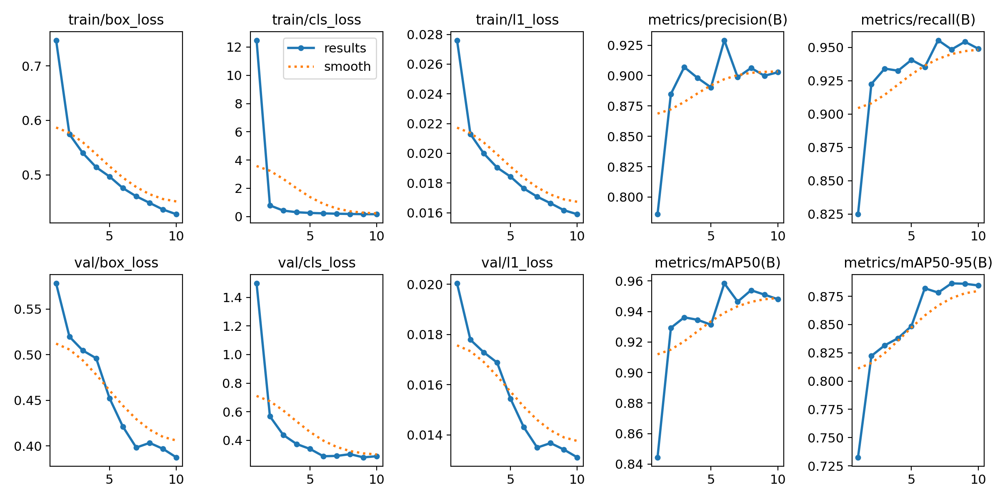

In [ ]:
from pathlib import Path
from IPython.display import display, Image

results_dir = Path("/content/YOLO_Results/student4_initial_training")

print("Results folder exists:", results_dir.exists())

if (results_dir / "results.png").exists():
    display(Image(filename=str(results_dir / "results.png")))
else:
    print("Training graph not found")


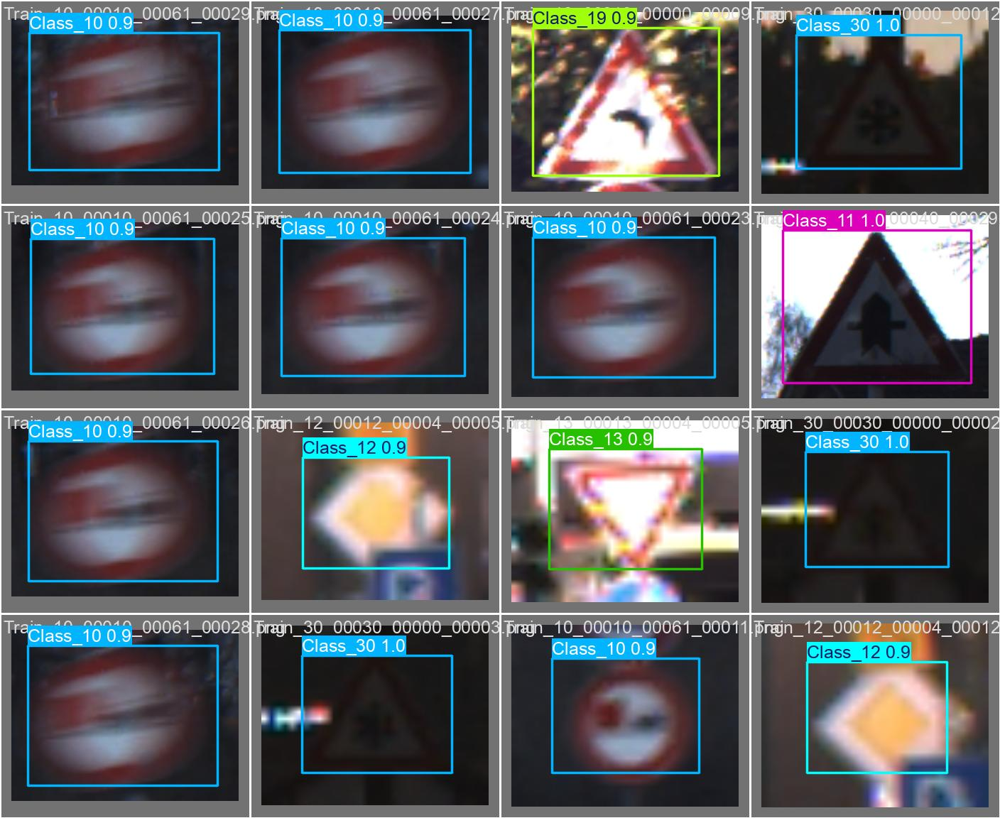

In [ ]:
from IPython.display import display, Image

pred_path = results_dir / "val_batch0_pred.jpg"

if pred_path.exists():
    display(Image(filename=str(pred_path)))
else:
    print("Prediction image not found")


GROUND TRUTH


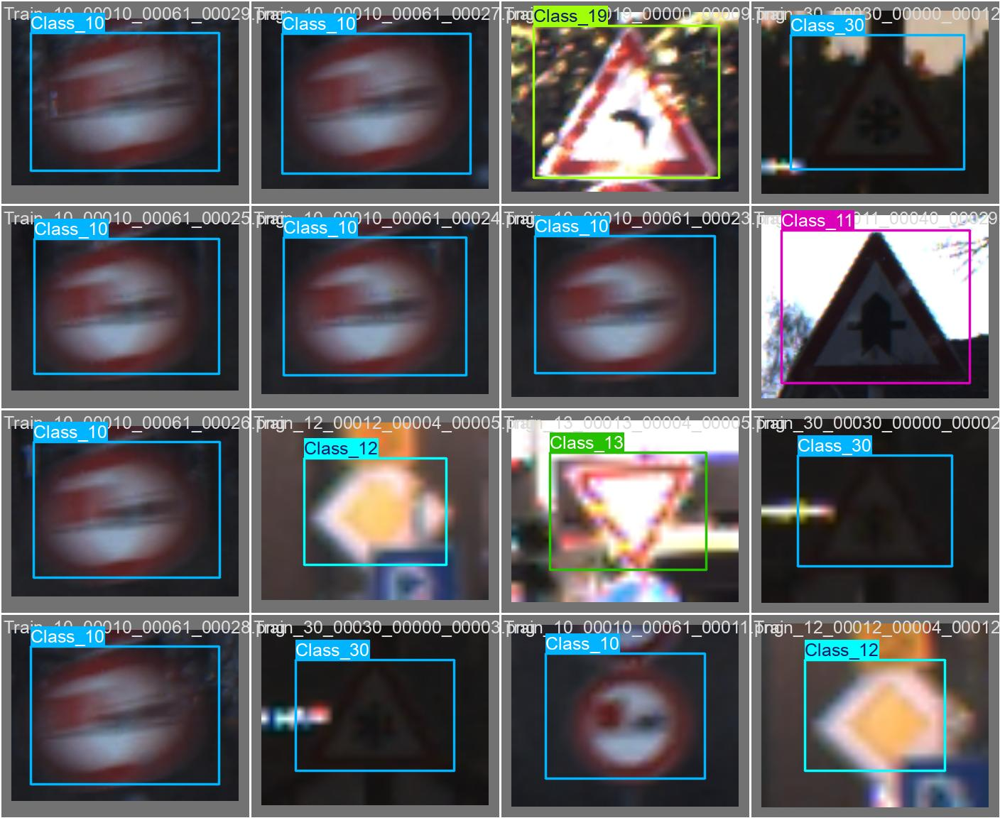

MODEL PREDICTIONS


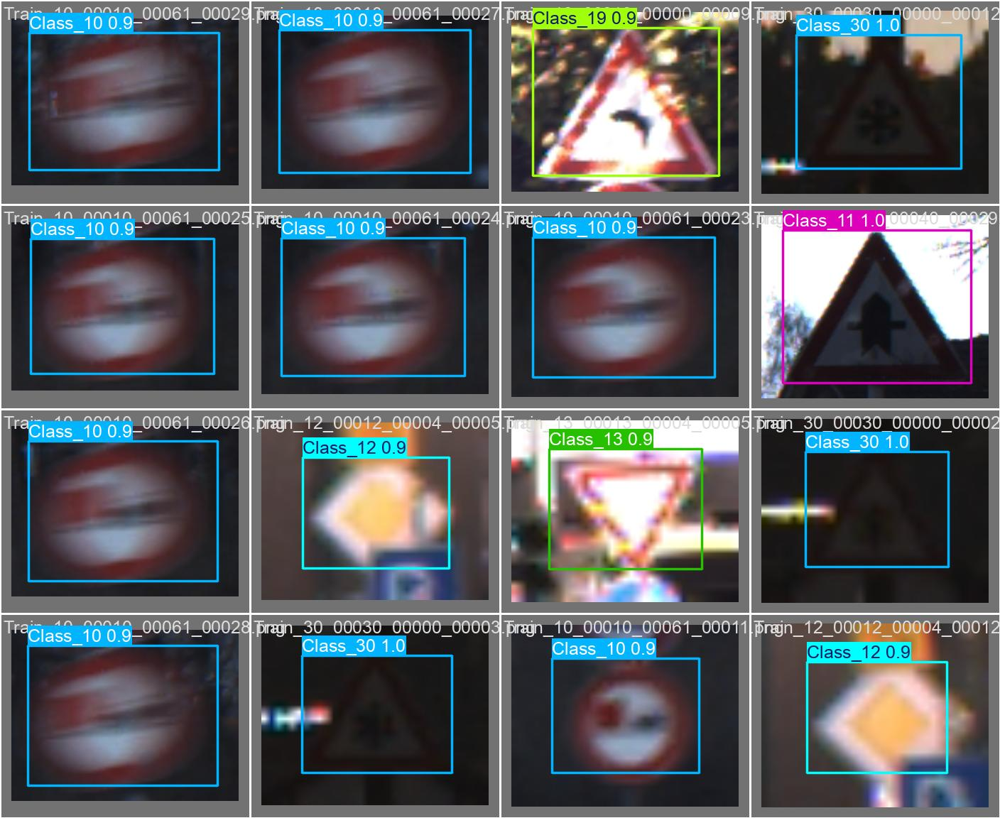

In [ ]:
from IPython.display import display, Image

labels_path = results_dir / "val_batch0_labels.jpg"
pred_path = results_dir / "val_batch0_pred.jpg"

print("GROUND TRUTH")
display(Image(filename=str(labels_path)))

print("MODEL PREDICTIONS")
display(Image(filename=str(pred_path)))


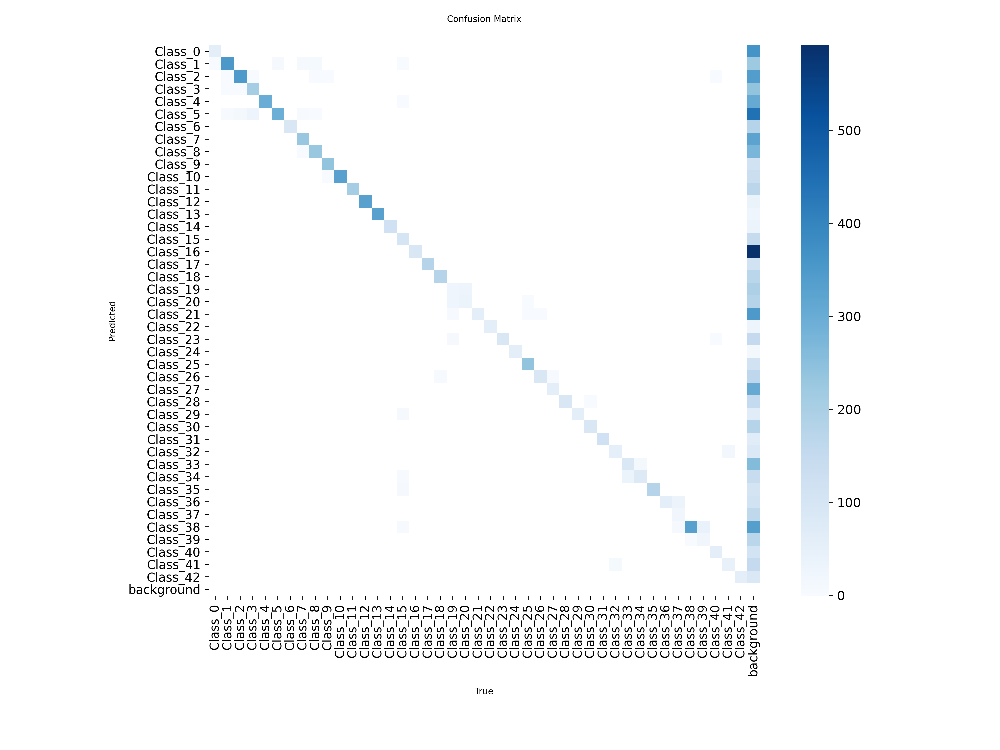

In [ ]:
from IPython.display import display, Image

cm_path = results_dir / "confusion_matrix.png"

if cm_path.exists():
    display(Image(filename=str(cm_path)))
else:
    print("Confusion matrix not found")


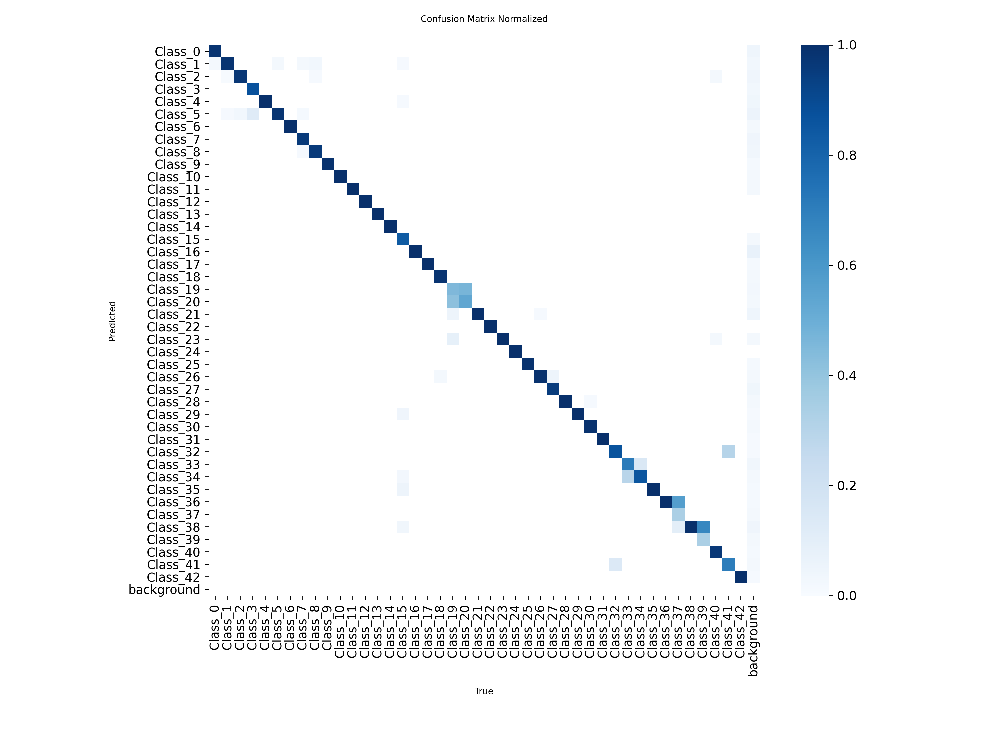

In [ ]:
from IPython.display import display, Image

cm_normalized = results_dir / "confusion_matrix_normalized.png"

if cm_normalized.exists():
    display(Image(filename=str(cm_normalized)))
else:
    print("Normalized confusion matrix not found")


In [ ]:
import pandas as pd

csv_path = results_dir / "results.csv"

df = pd.read_csv(csv_path)

metrics = [
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)"
]

print("Final Epoch Results:")
print(df[metrics].tail(1).to_string(index=False))


Final Epoch Results:
 metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
              0.90273            0.94903           0.94809              0.88459


In [ ]:
best_epoch = df["metrics/mAP50-95(B)"].idxmax()

print("Best Epoch:", int(df.loc[best_epoch, "epoch"]))
print("Best mAP50-95:", df.loc[best_epoch, "metrics/mAP50-95(B)"])
print("Best Precision:", df.loc[best_epoch, "metrics/precision(B)"])
print("Best Recall:", df.loc[best_epoch, "metrics/recall(B)"])


Best Epoch: 8
Best mAP50-95: 0.88644
Best Precision: 0.9063
Best Recall: 0.94843


In [ ]:
print("Best model path:", model_path)
print("Best model exists:", model_path.exists())
print("Number of classes:", len(model.names))

checkpoint = model.ckpt

if checkpoint is not None:
    print("Checkpoint epoch:", checkpoint.get("epoch", "Not available"))
else:
    print("Checkpoint information not available")

print("Best epoch from results.csv:",
      int(df.loc[best_epoch, "epoch"]))



Best model path: /content/Student4_YOLO_Final (3).pt
Best model exists: True
Number of classes: 43
Checkpoint epoch: -1
Best epoch from results.csv: 8


In [ ]:
from pathlib import Path

print("Checking available files...\n")

paths = [
    "/content/Student4_YOLO_Final (3).pt",
    "/content/YOLO_Results",
    "/content/YOLO_Results/student4_initial_training",
    "/content/Student4_Dataset_Config (2)",
]

for p in paths:
    path = Path(p)
    print(f"{p}: {'FOUND' if path.exists() else 'NOT FOUND'}")

print("\nDataset YAML files:")
for p in Path("/content").rglob("data.yaml"):
    print(p)


Checking available files...

/content/Student4_YOLO_Final (3).pt: FOUND
/content/YOLO_Results: FOUND
/content/YOLO_Results/student4_initial_training: FOUND
/content/Student4_Dataset_Config (2): NOT FOUND

Dataset YAML files:


In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("/content/Student4_Dataset_Config (2).zip")
extract_path = Path("/content/Student4_Dataset_Config")

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Config extracted successfully!")

for file in extract_path.rglob("*"):
    if file.is_file():
        print(file.relative_to(extract_path))


Dataset Config extracted successfully!
data.yaml
dataset_source.txt
yolo_val_split.csv
yolo_train_split.csv


In [ ]:
from pathlib import Path
import yaml

config_dir = Path("/content/Student4_Dataset_Config")
yaml_path = config_dir / "data.yaml"

with open(yaml_path, "r") as f:
    data_config = yaml.safe_load(f)

print("=== DATASET CONFIGURATION ===")
print(data_config)

print("\n=== DATASET SOURCE ===")
source_path = config_dir / "dataset_source.txt"

if source_path.exists():
    print(source_path.read_text())

print("\n=== DATASET PATH CHECK ===")

for key in ["path", "train", "val", "test"]:
    print(f"{key}: {data_config.get(key, 'Not specified')}")

print("\n=== AVAILABLE DATASET FOLDERS ===")

for folder in Path("/content").iterdir():
    if folder.is_dir():
        print(folder.name)


=== DATASET CONFIGURATION ===
{'path': '/content/GTSRB_YOLO', 'train': 'images/train', 'val': 'images/val', 'nc': 43, 'names': {0: 'Speed limit (20km/h)', 1: 'Speed limit (30km/h)', 2: 'Speed limit (50km/h)', 3: 'Speed limit (60km/h)', 4: 'Speed limit (70km/h)', 5: 'Speed limit (80km/h)', 6: 'End of speed limit (80km/h)', 7: 'Speed limit (100km/h)', 8: 'Speed limit (120km/h)', 9: 'No passing', 10: 'No passing for vehicles over 3.5 tons', 11: 'Right-of-way at next intersection', 12: 'Priority road', 13: 'Yield', 14: 'Stop', 15: 'No vehicles', 16: 'Vehicles over 3.5 tons prohibited', 17: 'No entry', 18: 'General caution', 19: 'Dangerous curve to the left', 20: 'Dangerous curve to the right', 21: 'Double curve', 22: 'Bumpy road', 23: 'Slippery road', 24: 'Road narrows on the right', 25: 'Road work', 26: 'Traffic signals', 27: 'Pedestrians', 28: 'Children crossing', 29: 'Bicycles crossing', 30: 'Beware of ice/snow', 31: 'Wild animals crossing', 32: 'End of all speed and passing limits', 33

In [ ]:
import pandas as pd
from pathlib import Path

config_dir = Path("/content/Student4_Dataset_Config")

train_csv = pd.read_csv(config_dir / "yolo_train_split.csv")
val_csv = pd.read_csv(config_dir / "yolo_val_split.csv")

print("=== TRAINING DATA ===")
print("Number of rows:", len(train_csv))
print("Columns:", train_csv.columns.tolist())
print(train_csv.head(5).to_string(index=False))

print("\n=== VALIDATION DATA ===")
print("Number of rows:", len(val_csv))
print("Columns:", val_csv.columns.tolist())
print(val_csv.head(5).to_string(index=False))


=== TRAINING DATA ===
Number of rows: 32609
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'TrackId']
 Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId                          Path     TrackId
    27      26       6       5      22      21        0 Train/0/00000_00002_00000.png 00000_00002
    27      28       5       6      22      23        0 Train/0/00000_00002_00001.png 00000_00002
    27      28       5       6      22      23        0 Train/0/00000_00002_00002.png 00000_00002
    30      29       6       5      25      24        0 Train/0/00000_00002_00003.png 00000_00002
    30      29       6       5      25      24        0 Train/0/00000_00002_00004.png 00000_00002

=== VALIDATION DATA ===
Number of rows: 6600
Columns: ['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path', 'TrackId']
 Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId                          Path     TrackId
    29      30       5    

In [ ]:
from pathlib import Path

print("=== CHECKING IMAGE FILES ===")

image_files = []

for extension in ["*.png", "*.jpg", "*.jpeg", "*.ppm"]:
    image_files.extend(
        Path("/content").rglob(extension)
    )

print("Total image files found:", len(image_files))

print("\nFirst 10 image files:")
for file in image_files[:10]:
    print(file)

print("\n=== CHECKING YOLO DATASET ===")

dataset_path = Path("/content/GTSRB_YOLO")

print("Dataset exists:", dataset_path.exists())

if dataset_path.exists():
    for folder in dataset_path.iterdir():
        print(folder.name)


=== CHECKING IMAGE FILES ===
Total image files found: 17

First 10 image files:
/content/YOLO_Results/student4_initial_training/results.png
/content/YOLO_Results/student4_initial_training/BoxPR_curve.png
/content/YOLO_Results/student4_initial_training/BoxR_curve.png
/content/YOLO_Results/student4_initial_training/confusion_matrix_normalized.png
/content/YOLO_Results/student4_initial_training/BoxP_curve.png
/content/YOLO_Results/student4_initial_training/BoxF1_curve.png
/content/YOLO_Results/student4_initial_training/confusion_matrix.png
/content/YOLO_Results/student4_initial_training/val_batch0_pred.jpg
/content/YOLO_Results/student4_initial_training/val_batch2_labels.jpg
/content/YOLO_Results/student4_initial_training/labels.jpg

=== CHECKING YOLO DATASET ===
Dataset exists: False


In [ ]:
!pip install -q kagglehub

import kagglehub
from pathlib import Path

dataset_path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)

print("\nDataset contents:")
for item in Path(dataset_path).iterdir():
    print(item.name)


Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/gtsrb-german-traffic-sign

Dataset contents:
Meta
meta
Meta.csv
Train.csv
Test.csv
Test
test
Train
train


In [ ]:
from pathlib import Path
import pandas as pd

dataset_root = Path(dataset_path)

train_sample = train_csv.iloc[0]
val_sample = val_csv.iloc[0]

print("=== TRAIN SAMPLE ===")
print("CSV Path:", train_sample["Path"])

train_image = dataset_root / train_sample["Path"]
print("Image exists:", train_image.exists())

print("\n=== VALIDATION SAMPLE ===")
print("CSV Path:", val_sample["Path"])

val_image = dataset_root / val_sample["Path"]
print("Image exists:", val_image.exists())

print("\n=== DATASET STRUCTURE ===")
for folder in ["Train", "train", "Test", "test"]:
    path = dataset_root / folder
    print(f"{folder}: {path.exists()}")

print("\n=== TRAIN / VAL OVERLAP ===")
overlap = set(train_csv["Path"]) & set(val_csv["Path"])
print("Overlapping images:", len(overlap))


=== TRAIN SAMPLE ===
CSV Path: Train/0/00000_00002_00000.png
Image exists: True

=== VALIDATION SAMPLE ===
CSV Path: Train/0/00000_00000_00000.png
Image exists: True

=== DATASET STRUCTURE ===
Train: True
train: True
Test: True
test: True

=== TRAIN / VAL OVERLAP ===
Overlapping images: 0


In [ ]:
from pathlib import Path
import pandas as pd

required_cols = [
    "Width", "Height",
    "Roi.X1", "Roi.Y1",
    "Roi.X2", "Roi.Y2",
    "ClassId", "Path"
]

print("=== DATASET VALIDATION ===")

for split_name, data in [
    ("Training", train_csv),
    ("Validation", val_csv)
]:
    print(f"\n=== {split_name} ===")

    missing_cols = set(required_cols) - set(data.columns)
    print("Missing columns:", missing_cols)

    if missing_cols:
        continue

    missing_values = data[required_cols].isna().sum().sum()
    print("Missing values:", missing_values)

    valid_boxes = (
        (data["Width"] > 0) &
        (data["Height"] > 0) &
        (data["Roi.X1"] >= 0) &
        (data["Roi.Y1"] >= 0) &
        (data["Roi.X2"] > data["Roi.X1"]) &
        (data["Roi.Y2"] > data["Roi.Y1"]) &
        (data["Roi.X2"] <= data["Width"]) &
        (data["Roi.Y2"] <= data["Height"])
    )

    print("Valid bounding boxes:", valid_boxes.sum())
    print("Invalid bounding boxes:", (~valid_boxes).sum())

    existing_images = data["Path"].apply(
        lambda p: (dataset_root / str(p)).is_file()
    )

    print("Existing images:", existing_images.sum())
    print("Missing images:", (~existing_images).sum())

    print("Number of classes:", data["ClassId"].nunique())


=== DATASET VALIDATION ===

=== Training ===
Missing columns: set()
Missing values: 0
Valid bounding boxes: 32609
Invalid bounding boxes: 0
Existing images: 32609
Missing images: 0
Number of classes: 43

=== Validation ===
Missing columns: set()
Missing values: 0
Valid bounding boxes: 6600
Invalid bounding boxes: 0
Existing images: 6600
Missing images: 0
Number of classes: 43


In [ ]:
from pathlib import Path
import shutil

yolo_root = Path("/content/GTSRB_YOLO")

for split in ["train", "val"]:
    (yolo_root / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (yolo_root / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

def convert_to_yolo(data, split):
    converted = 0

    for i, (_, row) in enumerate(data.iterrows()):
        image_path = dataset_root / str(row["Path"])
        class_id = int(row["ClassId"])

        width = float(row["Width"])
        height = float(row["Height"])

        x1 = float(row["Roi.X1"])
        y1 = float(row["Roi.Y1"])
        x2 = float(row["Roi.X2"])
        y2 = float(row["Roi.Y2"])

        x_center = ((x1 + x2) / 2) / width
        y_center = ((y1 + y2) / 2) / height
        box_width = (x2 - x1) / width
        box_height = (y2 - y1) / height

        new_name = f"{split}_{i:06d}"

        destination = (
            yolo_root / "images" / split /
            f"{new_name}{image_path.suffix.lower()}"
        )

        shutil.copy2(image_path, destination)

        label_path = (
            yolo_root / "labels" / split /
            f"{new_name}.txt"
        )

        with open(label_path, "w") as f:
            f.write(
                f"{class_id} {x_center:.6f} "
                f"{y_center:.6f} {box_width:.6f} "
                f"{box_height:.6f}\n"
            )

        converted += 1

    print(f"{split}: {converted} images converted")

convert_to_yolo(train_csv, "train")
convert_to_yolo(val_csv, "val")

print("\nYOLO dataset preparation completed!")


train: 32609 images converted
val: 6600 images converted

YOLO dataset preparation completed!


In [ ]:
from pathlib import Path
from collections import Counter

yolo_root = Path("/content/GTSRB_YOLO")

print("=== YOLO DATASET VERIFICATION ===")

for split in ["train", "val"]:
    images_dir = yolo_root / "images" / split
    labels_dir = yolo_root / "labels" / split

    images = sorted(
        p for p in images_dir.iterdir()
        if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
    )
    labels = sorted(labels_dir.glob("*.txt"))

    image_names = {p.stem for p in images}
    label_names = {p.stem for p in labels}

    missing_labels = image_names - label_names
    missing_images = label_names - image_names

    invalid_boxes = 0
    class_counts = Counter()

    for label_file in labels:
        with open(label_file, "r") as f:
            for line in f:
                try:
                    values = line.strip().split()
                    if len(values) != 5:
                        invalid_boxes += 1
                        continue

                    class_id = int(values[0])
                    x, y, w, h = map(float, values[1:])

                    if (
                        not 0 <= class_id < 43
                        or not 0 <= x <= 1
                        or not 0 <= y <= 1
                        or not 0 < w <= 1
                        or not 0 < h <= 1
                        or x - w/2 < -1e-5
                        or y - h/2 < -1e-5
                        or x + w/2 > 1 + 1e-5
                        or y + h/2 > 1 + 1e-5
                    ):
                        invalid_boxes += 1
                    else:
                        class_counts[class_id] += 1

                except (ValueError, OverflowError):
                    invalid_boxes += 1

    print(f"\n=== {split.upper()} DATASET ===")
    print("Number of images:", len(images))
    print("Number of labels:", len(labels))
    print("Missing labels:", len(missing_labels))
    print("Missing images:", len(missing_images))
    print("Invalid bounding boxes:", invalid_boxes)
    print("Number of classes:", len(class_counts))

print("\nDataset verification completed!")


=== YOLO DATASET VERIFICATION ===

=== TRAIN DATASET ===
Number of images: 32609
Number of labels: 32609
Missing labels: 0
Missing images: 0
Invalid bounding boxes: 0
Number of classes: 43

=== VAL DATASET ===
Number of images: 6600
Number of labels: 6600
Missing labels: 0
Missing images: 0
Invalid bounding boxes: 0
Number of classes: 43

Dataset verification completed!


In [ ]:
from pathlib import Path
import yaml

yolo_root = Path("/content/GTSRB_YOLO")

config = data_config.copy()
config["path"] = str(yolo_root)
config["train"] = "images/train"
config["val"] = "images/val"

# Test dataset will be configured separately
config.pop("test", None)

yaml_output = yolo_root / "data.yaml"

with open(yaml_output, "w") as f:
    yaml.safe_dump(
        config,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print("YOLO configuration saved successfully!")
print("YAML path:", yaml_output)
print("Number of classes:", config["nc"])
print("Train path:", yolo_root / config["train"])
print("Validation path:", yolo_root / config["val"])


YOLO configuration saved successfully!
YAML path: /content/GTSRB_YOLO/data.yaml
Number of classes: 43
Train path: /content/GTSRB_YOLO/images/train
Validation path: /content/GTSRB_YOLO/images/val


In [ ]:
import torch

print("=== GPU CHECK ===")
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
    print("GPU Memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
          "GB")
else:
    print("No GPU detected!")


=== GPU CHECK ===
CUDA Available: True
GPU Name: Tesla T4
GPU Memory: 15.64 GB


In [ ]:
from ultralytics import YOLO
from pathlib import Path

model_path = Path("/content/Student4_YOLO_Final (3).pt")
yaml_path = Path("/content/GTSRB_YOLO/data.yaml")

assert model_path.exists(), "Student 4 model not found!"
assert yaml_path.exists(), "data.yaml not found!"

model = YOLO(str(model_path))

print("Starting Student 5 - Experiment 1")

results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=640,
    batch=16,
    lr0=0.001,
    optimizer="AdamW",
    device=0,
    workers=2,
    project="/content/Student5_YOLO_Optimization",
    name="experiment_1",
    exist_ok=True,
    seed=42,
    plots=True
)

print("Experiment 1 completed!")


Starting Student 5 - Experiment 1
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/GTSRB_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/Student4_YOLO_Final (3).pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name

In [ ]:
from pathlib import Path
from google.colab import files
import shutil

experiment_path = Path(
    "/content/Student5_YOLO_Optimization/experiment_1"
)

assert experiment_path.exists(), "Experiment 1 not found!"

zip_path = shutil.make_archive(
    "/content/Student5_Experiment_1_Backup",
    "zip",
    root_dir=experiment_path.parent,
    base_dir=experiment_path.name
)

print("Backup created successfully!")
print("Backup size:", round(Path(zip_path).stat().st_size / (1024**2), 2), "MB")

files.download(zip_path)



Backup created successfully!
Backup size: 13.89 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from ultralytics import YOLO
from pathlib import Path

model_path = Path("/content/Student4_YOLO_Final (3).pt")
yaml_path = Path("/content/GTSRB_YOLO/data.yaml")

assert model_path.exists(), "Student 4 model not found!"
assert yaml_path.exists(), "data.yaml not found!"

model = YOLO(str(model_path))

print("Starting Student 5 - Experiment 2")

results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=640,
    batch=32,
    lr0=0.0005,
    optimizer="AdamW",
    device=0,
    workers=2,
    project="/content/Student5_YOLO_Optimization",
    name="experiment_2",
    exist_ok=True,
    seed=42,
    plots=True
)

print("Experiment 2 completed!")


Starting Student 5 - Experiment 2
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/GTSRB_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/Student4_YOLO_Final (3).pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, nam

In [ ]:
from pathlib import Path
from google.colab import files
import shutil

experiment_path = Path(
    "/content/Student5_YOLO_Optimization/experiment_2"
)

assert experiment_path.exists(), "Experiment 2 not found!"

zip_path = shutil.make_archive(
    "/content/Student5_Experiment_2_Backup",
    "zip",
    root_dir=experiment_path.parent,
    base_dir=experiment_path.name
)

print("Experiment 2 backup created successfully!")

files.download(zip_path)


Experiment 2 backup created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from ultralytics import YOLO
from pathlib import Path

model_path = Path("/content/Student4_YOLO_Final (3).pt")
yaml_path = Path("/content/GTSRB_YOLO/data.yaml")

assert model_path.exists(), "Student 4 model not found!"
assert yaml_path.exists(), "data.yaml not found!"

experiment_dir = Path(
    "/content/Student5_YOLO_Optimization/experiment_3"
)

assert not experiment_dir.exists(), (
    "Experiment 3 folder already exists! "
    "Do not overwrite previous results."
)

model = YOLO(str(model_path))

print("Starting Student 5 - Experiment 3")

results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=640,
    batch=16,
    lr0=0.0005,
    optimizer="AdamW",
    device=0,
    workers=2,
    project="/content/Student5_YOLO_Optimization",
    name="experiment_3",
    exist_ok=False,
    seed=42,
    plots=True
)

print("Experiment 3 completed!")


AssertionError: Experiment 3 folder already exists! Do not overwrite previous results.

In [ ]:
from pathlib import Path

experiment_dir = Path(
    "/content/Student5_YOLO_Optimization/experiment_3"
)

last_model = experiment_dir / "weights" / "last.pt"
best_model = experiment_dir / "weights" / "best.pt"
results_csv = experiment_dir / "results.csv"

print("=== EXPERIMENT 3 CHECK ===")
print("Experiment folder exists:", experiment_dir.exists())
print("Last checkpoint exists:", last_model.exists())
print("Best model exists:", best_model.exists())
print("Results CSV exists:", results_csv.exists())

if results_csv.exists():
    import pandas as pd
    df = pd.read_csv(results_csv)
    print("Completed epochs recorded:", len(df))
    print(df.tail(3).to_string(index=False))


=== EXPERIMENT 3 CHECK ===
Experiment folder exists: True
Last checkpoint exists: True
Best model exists: True
Results CSV exists: True
Completed epochs recorded: 1
 epoch   time  train/box_loss  train/cls_loss  train/l1_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  val/box_loss  val/cls_loss  val/l1_loss   lr/pg0   lr/pg1  lr/pg2
     1 538.42         0.72503         0.58125        0.02766               0.82151            0.79945           0.85244               0.7012       0.70965       0.89891      0.02613 0.000167 0.000167 0.06685


In [ ]:
import torch
from pathlib import Path

checkpoint_path = Path(
    "/content/Student5_YOLO_Optimization/experiment_3/weights/last.pt"
)

checkpoint = torch.load(
    str(checkpoint_path),
    map_location="cpu",
    weights_only=False
)

print("=== CHECKPOINT INFORMATION ===")
print("Saved epoch:", checkpoint.get("epoch"))
print("Optimizer state exists:",
      checkpoint.get("optimizer") is not None)
print("EMA state exists:",
      checkpoint.get("ema") is not None)


=== CHECKPOINT INFORMATION ===
Saved epoch: 0
Optimizer state exists: True
EMA state exists: True


In [ ]:
from ultralytics import YOLO
from pathlib import Path

checkpoint_path = Path(
    "/content/Student5_YOLO_Optimization/experiment_3/weights/last.pt"
)

assert checkpoint_path.exists(), "Checkpoint not found!"

model = YOLO(str(checkpoint_path))

print("Resuming Experiment 3...")

results = model.train(
    resume=True,
    device=0
)

print("Experiment 3 completed!")


Resuming Experiment 3...
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/GTSRB_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/Student5_YOLO_Optimization/experiment_3/weights/last.pt, momentum=0.937, mosaic=1.0,

In [ ]:
from pathlib import Path
import torch

print("GPU Available:", torch.cuda.is_available())

print("\n=== FILE CHECK ===")

files_to_check = {
    "Student 4 Model": "/content/Student4_YOLO_Final (3).pt",
    "YOLO Dataset": "/content/GTSRB_YOLO",
    "Experiment 1": "/content/Student5_YOLO_Optimization/experiment_1",
    "Experiment 2": "/content/Student5_YOLO_Optimization/experiment_2",
    "Experiment 3": "/content/Student5_YOLO_Optimization/experiment_3"
}

for name, path in files_to_check.items():
    print(f"{name}: {Path(path).exists()}")


GPU Available: True

=== FILE CHECK ===
Student 4 Model: False
YOLO Dataset: False
Experiment 1: False
Experiment 2: False
Experiment 3: False


In [ ]:
from google.colab import files

print("Select Student 4 model and dataset configuration ZIP")

uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded.keys():
    print(filename)


Select Student 4 model and dataset configuration ZIP


Saving Student4_YOLO_Final (3).pt to Student4_YOLO_Final (3).pt

Uploaded files:
Student4_YOLO_Final (3).pt


In [ ]:
from pathlib import Path
import zipfile

model_path = Path("/content/Student4_YOLO_Final (3).pt")
config_zip = Path("/content/Student4_Dataset_Config (2).zip")
extract_path = Path("/content/Student4_Dataset_Config")

print("=== FILE VERIFICATION ===")
print("Student 4 Model:", model_path.exists())
print("Dataset Config ZIP:", config_zip.exists())

if model_path.exists() and config_zip.exists():
    extract_path.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(config_zip, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("\nConfiguration extracted successfully!")

    print("\nExtracted files:")
    for file in extract_path.rglob("*"):
        if file.is_file():
            print(file.relative_to(extract_path))
else:
    print("\nSome files are missing!")


=== FILE VERIFICATION ===
Student 4 Model: True
Dataset Config ZIP: True

Configuration extracted successfully!

Extracted files:
yolo_val_split.csv
data.yaml
yolo_train_split.csv
dataset_source.txt


In [ ]:
import sys
import subprocess
from pathlib import Path

# Install KaggleHub if needed
subprocess.run(
    [sys.executable, "-m", "pip", "-q", "install", "kagglehub"],
    check=True
)

import kagglehub
import pandas as pd

# Download original GTSRB dataset
dataset_path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

dataset_root = Path(dataset_path)

# Load Student 4's original train/val splits
config_root = Path("/content/Student4_Dataset_Config")

train_csv = pd.read_csv(
    config_root / "yolo_train_split.csv"
)

val_csv = pd.read_csv(
    config_root / "yolo_val_split.csv"
)

print("=== DATASET RESTORATION ===")
print("Dataset path:", dataset_root)
print("Training images:", len(train_csv))
print("Validation images:", len(val_csv))

print("First training image exists:",
      (dataset_root / str(train_csv.iloc[0]["Path"])).exists())

print("First validation image exists:",
      (dataset_root / str(val_csv.iloc[0]["Path"])).exists())

print("Dataset download and split loading completed!")


Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
=== DATASET RESTORATION ===
Dataset path: /kaggle/input/gtsrb-german-traffic-sign
Training images: 32609
Validation images: 6600
First training image exists: True
First validation image exists: True
Dataset download and split loading completed!


In [ ]:
from pathlib import Path
import shutil
import yaml

yolo_root = Path("/content/GTSRB_YOLO")

for split in ["train", "val"]:
    (yolo_root / "images" / split).mkdir(
        parents=True, exist_ok=True
    )
    (yolo_root / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

def convert_to_yolo(data, split):
    converted = 0

    for i, (_, row) in enumerate(data.iterrows()):
        image_path = dataset_root / str(row["Path"])

        class_id = int(row["ClassId"])
        width = float(row["Width"])
        height = float(row["Height"])

        x1 = float(row["Roi.X1"])
        y1 = float(row["Roi.Y1"])
        x2 = float(row["Roi.X2"])
        y2 = float(row["Roi.Y2"])

        x_center = ((x1 + x2) / 2) / width
        y_center = ((y1 + y2) / 2) / height
        box_width = (x2 - x1) / width
        box_height = (y2 - y1) / height

        new_name = f"{split}_{i:06d}"

        destination = (
            yolo_root / "images" / split /
            f"{new_name}{image_path.suffix.lower()}"
        )

        shutil.copy2(image_path, destination)

        label_path = (
            yolo_root / "labels" / split /
            f"{new_name}.txt"
        )

        with open(label_path, "w") as f:
            f.write(
                f"{class_id} {x_center:.6f} "
                f"{y_center:.6f} {box_width:.6f} "
                f"{box_height:.6f}\n"
            )

        converted += 1

    print(f"{split}: {converted} images converted")

convert_to_yolo(train_csv, "train")
convert_to_yolo(val_csv, "val")

# Restore the original dataset configuration
config_path = Path(
    "/content/Student4_Dataset_Config/data.yaml"
)

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

config["path"] = str(yolo_root)
config["train"] = "images/train"
config["val"] = "images/val"
config.pop("test", None)

with open(yolo_root / "data.yaml", "w") as f:
    yaml.safe_dump(
        config,
        f,
        sort_keys=False,
        allow_unicode=True
    )

print("\nYOLO dataset restored successfully!")
print("Configuration:", yolo_root / "data.yaml")
print("Number of classes:", config["nc"])


train: 32609 images converted
val: 6600 images converted

YOLO dataset restored successfully!
Configuration: /content/GTSRB_YOLO/data.yaml
Number of classes: 43


In [ ]:
%pip install -q ultralytics==8.4.212

from ultralytics import YOLO
import ultralytics

print("Ultralytics installed successfully!")
print("Version:", ultralytics.__version__)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics installed successfully!
Version: 8.4.212


In [ ]:
from ultralytics import YOLO
from pathlib import Path
import torch

model_path = Path("/content/Student4_YOLO_Final (3).pt")
yaml_path = Path("/content/GTSRB_YOLO/data.yaml")

assert model_path.exists(), "Student 4 model not found!"
assert yaml_path.exists(), "data.yaml not found!"
assert torch.cuda.is_available(), "GPU not available!"

experiment_dir = Path(
    "/content/Student5_YOLO_Optimization/experiment_3"
)

assert not experiment_dir.exists(), (
    "Experiment 3 already exists. "
    "Check its files before starting again."
)

model = YOLO(str(model_path))

print("Starting Student 5 - Experiment 3")

results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=640,
    batch=16,
    lr0=0.0005,
    optimizer="AdamW",
    device=0,
    workers=2,
    project="/content/Student5_YOLO_Optimization",
    name="experiment_3",
    exist_ok=False,
    seed=42,
    plots=True
)

print("Experiment 3 completed!")


Starting Student 5 - Experiment 3
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/GTSRB_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/Student4_YOLO_Final (3).pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, na

In [ ]:
from pathlib import Path
from google.colab import files
import shutil

experiment_path = Path(
    "/content/Student5_YOLO_Optimization/experiment_3"
)

assert experiment_path.exists(), "Experiment 3 folder not found!"

assert (experiment_path / "weights" / "best.pt").exists(), (
    "Best model not found!"
)

zip_path = shutil.make_archive(
    "/content/Student5_Experiment_3_Backup",
    "zip",
    root_dir=experiment_path.parent,
    base_dir=experiment_path.name
)

print("Experiment 3 backup created successfully!")
print("Backup size:",
      round(Path(zip_path).stat().st_size / (1024**2), 2),
      "MB")

files.download(zip_path)


Experiment 3 backup created successfully!
Backup size: 13.96 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from ultralytics import YOLO
from pathlib import Path
import torch

model_path = Path("/content/Student4_YOLO_Final (3).pt")
yaml_path = Path("/content/GTSRB_YOLO/data.yaml")

assert model_path.exists(), "Student 4 model not found!"
assert yaml_path.exists(), "data.yaml not found!"
assert torch.cuda.is_available(), "GPU not available!"

experiment_dir = Path(
    "/content/Student5_YOLO_Optimization/experiment_4"
)

assert not experiment_dir.exists(), (
    "Experiment 4 folder already exists! "
    "Do not overwrite previous results."
)

model = YOLO(str(model_path))

print("Starting Student 5 - Experiment 4")

results = model.train(
    data=str(yaml_path),
    epochs=10,
    imgsz=512,
    batch=16,
    lr0=0.001,
    optimizer="AdamW",
    device=0,
    workers=2,
    project="/content/Student5_YOLO_Optimization",
    name="experiment_4",
    exist_ok=False,
    seed=42,
    plots=True
)

print("Experiment 4 completed!")


Starting Student 5 - Experiment 4
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/GTSRB_YOLO/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/Student4_YOLO_Final (3).pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, nam

In [ ]:
from pathlib import Path
from google.colab import files
import shutil

experiment_path = Path(
    "/content/Student5_YOLO_Optimization/experiment_4"
)

assert experiment_path.exists(), "Experiment 4 folder not found!"
assert (experiment_path / "weights" / "best.pt").exists(), (
    "Best model not found!"
)

zip_path = shutil.make_archive(
    "/content/Student5_Experiment_4_Backup",
    "zip",
    root_dir=experiment_path.parent,
    base_dir=experiment_path.name
)

print("Experiment 4 backup created successfully!")
print(
    "Backup size:",
    round(Path(zip_path).stat().st_size / (1024**2), 2),
    "MB"
)

files.download(zip_path)


Experiment 4 backup created successfully!
Backup size: 13.88 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
import pandas as pd

root = Path("/content/Student5_YOLO_Optimization")

print("=== EXPERIMENT FILE CHECK ===")

for i in range(1, 5):
    folder = root / f"experiment_{i}"
    csv_path = folder / "results.csv"
    best_path = folder / "weights" / "best.pt"

    print(f"\nExperiment {i}")
    print("Folder exists:", folder.exists())
    print("Results CSV exists:", csv_path.exists())
    print("Best model exists:", best_path.exists())

    if csv_path.exists():
        df = pd.read_csv(csv_path)
        df.columns = df.columns.str.strip()

        metric = "metrics/mAP50-95(B)"

        if metric in df.columns:
            best_row = df.loc[df[metric].idxmax()]
            print("Best epoch:", int(best_row["epoch"]))
            print("Best mAP50-95:", round(float(best_row[metric]), 6))

print("\nExperiment file check completed!")


=== EXPERIMENT FILE CHECK ===

Experiment 1
Folder exists: False
Results CSV exists: False
Best model exists: False

Experiment 2
Folder exists: False
Results CSV exists: False
Best model exists: False

Experiment 3
Folder exists: True
Results CSV exists: True
Best model exists: True
Best epoch: 9
Best mAP50-95: 0.89256

Experiment 4
Folder exists: True
Results CSV exists: True
Best model exists: True
Best epoch: 8
Best mAP50-95: 0.89677

Experiment file check completed!


In [ ]:
from pathlib import Path
import zipfile

root = Path("/content/Student5_YOLO_Optimization")
root.mkdir(parents=True, exist_ok=True)

for i in [1, 2]:
    zip_path = Path(
        f"/content/Student5_Experiment_{i}_Backup.zip"
    )

    assert zip_path.exists(), (
        f"Experiment {i} backup ZIP not found!"
    )

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(root)

    print(f"Experiment {i} extracted successfully!")

print("\n=== FINAL FILE CHECK ===")

for i in range(1, 5):
    folder = root / f"experiment_{i}"

    print(f"\nExperiment {i}")
    print("Results CSV:", (folder / "results.csv").exists())
    print("Best model:", (folder / "weights" / "best.pt").exists())

print("\nRestoration check completed!")


Experiment 1 extracted successfully!
Experiment 2 extracted successfully!

=== FINAL FILE CHECK ===

Experiment 1
Results CSV: True
Best model: True

Experiment 2
Results CSV: True
Best model: True

Experiment 3
Results CSV: True
Best model: True

Experiment 4
Results CSV: True
Best model: True

Restoration check completed!


In [ ]:
from pathlib import Path
import pandas as pd

root = Path("/content/Student5_YOLO_Optimization")

metric_cols = {
    "Precision": "metrics/precision(B)",
    "Recall": "metrics/recall(B)",
    "mAP50": "metrics/mAP50(B)",
    "mAP50-95": "metrics/mAP50-95(B)"
}

comparison = []

for i in range(1, 5):
    folder = root / f"experiment_{i}"
    csv_path = folder / "results.csv"
    best_path = folder / "weights" / "best.pt"

    assert csv_path.exists(), f"Missing CSV: Experiment {i}"
    assert best_path.exists(), f"Missing model: Experiment {i}"

    df = pd.read_csv(csv_path)
    df.columns = df.columns.str.strip()

    # Select the epoch with the highest validation mAP50-95
    best_idx = df["metrics/mAP50-95(B)"].idxmax()
    best_row = df.loc[best_idx]

    row = {
        "Experiment": f"Experiment {i}",
        "Best Epoch": int(best_row["epoch"]),
        "Image Size": 512 if i == 4 else 640,
        "Batch Size": 32 if i == 2 else 16,
        "Learning Rate": 0.0005 if i in [2, 3] else 0.001
    }

    for name, col in metric_cols.items():
        row[name] = float(best_row[col])

    comparison.append(row)

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="mAP50-95",
    ascending=False
).reset_index(drop=True)

print("=== FINAL EXPERIMENT COMPARISON ===")
print(comparison_df.to_string(index=False))

winner = comparison_df.iloc[0]

print("\n=== BEST EXPERIMENT ===")
print("Experiment:", winner["Experiment"])
print("Best Epoch:", winner["Best Epoch"])
print("Precision:", round(winner["Precision"], 6))
print("Recall:", round(winner["Recall"], 6))
print("mAP50:", round(winner["mAP50"], 6))
print("mAP50-95:", round(winner["mAP50-95"], 6))

output_path = root / "Student5_Experiment_Comparison.csv"
comparison_df.to_csv(output_path, index=False)

print("\nComparison saved to:", output_path)


=== FINAL EXPERIMENT COMPARISON ===
  Experiment  Best Epoch  Image Size  Batch Size  Learning Rate  Precision  Recall   mAP50  mAP50-95
Experiment 1          10         640          16         0.0010    0.92758 0.93696 0.95644   0.89678
Experiment 4           8         512          16         0.0010    0.93913 0.92840 0.95745   0.89677
Experiment 3           9         640          16         0.0005    0.90680 0.93731 0.94726   0.89256
Experiment 2          10         640          32         0.0005    0.91472 0.93059 0.94243   0.88700

=== BEST EXPERIMENT ===
Experiment: Experiment 1
Best Epoch: 10
Precision: 0.92758
Recall: 0.93696
mAP50: 0.95644
mAP50-95: 0.89678

Comparison saved to: /content/Student5_YOLO_Optimization/Student5_Experiment_Comparison.csv


In [ ]:
from pathlib import Path
import shutil

root = Path("/content/Student5_YOLO_Optimization")

source_model = root / "experiment_1" / "weights" / "best.pt"
final_model = root / "Student5_Best_Model.pt"

assert source_model.exists(), "Experiment 1 best.pt not found!"

shutil.copy2(source_model, final_model)

print("Best model selected: Experiment 1")
print("Final model saved:", final_model)
print(
    "Model size:",
    round(final_model.stat().st_size / (1024**2), 2),
    "MB"
)
print("Ready for independent test evaluation!")


Best model selected: Experiment 1
Final model saved: /content/Student5_YOLO_Optimization/Student5_Best_Model.pt
Model size: 5.21 MB
Ready for independent test evaluation!


In [ ]:
from pathlib import Path
import pandas as pd
import kagglehub

# Locate the original GTSRB dataset
dataset_path = kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
)

dataset_root = Path(dataset_path)

test_csv_path = dataset_root / "Test.csv"
test_images_path = dataset_root / "Test"

assert test_csv_path.exists(), "Test.csv not found!"
assert test_images_path.exists(), "Test images folder not found!"

test_df = pd.read_csv(test_csv_path)

print("=== ORIGINAL GTSRB TEST DATASET ===")
print("Dataset root:", dataset_root)
print("Test CSV exists:", test_csv_path.exists())
print("Test folder exists:", test_images_path.exists())
print("Total test images:", len(test_df))

print("\n=== CSV COLUMNS ===")
print(test_df.columns.tolist())

print("\n=== FIRST 5 ROWS ===")
print(test_df.head().to_string(index=False))

print("\n=== CLASS DISTRIBUTION ===")
print(test_df["ClassId"].value_counts().sort_index().to_string())

print("\n=== IMAGE PATH CHECK ===")
sample_paths = test_df["Path"].head(5)

for relative_path in sample_paths:
    image_path = dataset_root / relative_path
    print(relative_path, "Exists:", image_path.exists())

print("\nTest dataset inspection completed!")


Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
=== ORIGINAL GTSRB TEST DATASET ===
Dataset root: /kaggle/input/gtsrb-german-traffic-sign
Test CSV exists: True
Test folder exists: True
Total test images: 12630

=== CSV COLUMNS ===
['Width', 'Height', 'Roi.X1', 'Roi.Y1', 'Roi.X2', 'Roi.Y2', 'ClassId', 'Path']

=== FIRST 5 ROWS ===
 Width  Height  Roi.X1  Roi.Y1  Roi.X2  Roi.Y2  ClassId           Path
    53      54       6       5      48      49       16 Test/00000.png
    42      45       5       5      36      40        1 Test/00001.png
    48      52       6       6      43      47       38 Test/00002.png
    27      29       5       5      22      24       33 Test/00003.png
    60      57       5       5      55      52       11 Test/00004.png

=== CLASS DISTRIBUTION ===
ClassId
0      60
1     720
2     750
3     450
4     660
5     630
6     150
7     450
8     450
9     480
10    660
11    420
12    690
13    720
14    270
15    210
16    150
17  

In [ ]:
from pathlib import Path

root = Path("/content/GTSRB_YOLO")

images_dir = root / "images" / "test"
labels_dir = root / "labels" / "test"

image_count = len(list(images_dir.glob("*.png"))) if images_dir.exists() else 0
label_count = len(list(labels_dir.glob("*.txt"))) if labels_dir.exists() else 0

print("Test images folder exists:", images_dir.exists())
print("Test labels folder exists:", labels_dir.exists())
print("Total test images:", image_count)
print("Total test labels:", label_count)

if image_count == 12630 and label_count == 12630:
    print("SUCCESS: Test Dataset is ready!")
else:
    print("Test Dataset conversion is not complete yet.")



Test images folder exists: False
Test labels folder exists: False
Total test images: 0
Total test labels: 0
Test Dataset conversion is not complete yet.


In [ ]:
from pathlib import Path
import pandas as pd
import shutil

# Original GTSRB test dataset
dataset_root = Path("/kaggle/input/gtsrb-german-traffic-sign")
test_csv_path = dataset_root / "Test.csv"

# YOLO dataset directories
yolo_root = Path("/content/GTSRB_YOLO")
images_dir = yolo_root / "images" / "test"
labels_dir = yolo_root / "labels" / "test"

assert test_csv_path.exists(), "Test.csv not found!"

images_dir.mkdir(parents=True, exist_ok=True)
labels_dir.mkdir(parents=True, exist_ok=True)

test_df = pd.read_csv(test_csv_path)

print("Starting Test Dataset conversion...")

converted = 0

for idx, row in test_df.iterrows():

    source = dataset_root / str(row["Path"])
    assert source.exists(), f"Missing image: {source}"

    w = float(row["Width"])
    h = float(row["Height"])

    x1 = float(row["Roi.X1"])
    y1 = float(row["Roi.Y1"])
    x2 = float(row["Roi.X2"])
    y2 = float(row["Roi.Y2"])

    class_id = int(row["ClassId"])

    assert (
        w > 0 and h > 0
        and 0 <= x1 < x2 <= w
        and 0 <= y1 < y2 <= h
        and 0 <= class_id < 43
    ), f"Invalid annotation at row {idx}"

    x_center = (x1 + x2) / (2 * w)
    y_center = (y1 + y2) / (2 * h)
    box_w = (x2 - x1) / w
    box_h = (y2 - y1) / h

    filename = f"test_{idx:05d}"

    shutil.copy2(
        source,
        images_dir / f"{filename}.png"
    )

    label_path = labels_dir / f"{filename}.txt"

    label_path.write_text(
        f"{class_id} "
        f"{x_center:.6f} "
        f"{y_center:.6f} "
        f"{box_w:.6f} "
        f"{box_h:.6f}\n"
    )

    converted += 1

print("\n=== TEST CONVERSION RESULTS ===")
print("Expected images:", len(test_df))
print("Converted images:", converted)
print("Images saved:", len(list(images_dir.glob("*.png"))))
print("Labels saved:", len(list(labels_dir.glob("*.txt"))))

assert converted == 12630
assert len(list(images_dir.glob("*.png"))) == 12630
assert len(list(labels_dir.glob("*.txt"))) == 12630

print("\nSUCCESS: Test Dataset converted successfully!")


Starting Test Dataset conversion...

=== TEST CONVERSION RESULTS ===
Expected images: 12630
Converted images: 12630
Images saved: 12630
Labels saved: 12630

SUCCESS: Test Dataset converted successfully!


In [ ]:

from pathlib import Path
import yaml

yaml_path = Path("/content/GTSRB_YOLO/data.yaml")

assert yaml_path.exists(), "data.yaml not found!"

# Read the existing dataset configuration
with open(yaml_path, "r") as f:
    data_config = yaml.safe_load(f)

print("=== ORIGINAL DATA CONFIG ===")
print(yaml.safe_dump(data_config, sort_keys=False))

# Add the independent test split
data_config["test"] = "images/test"

# Keep all existing settings unchanged
with open(yaml_path, "w") as f:
    yaml.safe_dump(
        data_config,
        f,
        sort_keys=False,
        allow_unicode=True
    )

# Verify the updated configuration
with open(yaml_path, "r") as f:
    updated_config = yaml.safe_load(f)

assert updated_config["test"] == "images/test"
assert updated_config["train"] == "images/train"
assert updated_config["val"] == "images/val"
assert int(updated_config["nc"]) == 43

print("\n=== UPDATED DATA CONFIG ===")
print("Dataset path:", updated_config["path"])
print("Train:", updated_config["train"])
print("Validation:", updated_config["val"])
print("Test:", updated_config["test"])
print("Number of classes:", updated_config["nc"])

print("\nSUCCESS: Test split added to data.yaml!")


=== ORIGINAL DATA CONFIG ===
path: /content/GTSRB_YOLO
train: images/train
val: images/val
nc: 43
names:
  0: Speed limit (20km/h)
  1: Speed limit (30km/h)
  2: Speed limit (50km/h)
  3: Speed limit (60km/h)
  4: Speed limit (70km/h)
  5: Speed limit (80km/h)
  6: End of speed limit (80km/h)
  7: Speed limit (100km/h)
  8: Speed limit (120km/h)
  9: No passing
  10: No passing for vehicles over 3.5 tons
  11: Right-of-way at next intersection
  12: Priority road
  13: Yield
  14: Stop
  15: No vehicles
  16: Vehicles over 3.5 tons prohibited
  17: No entry
  18: General caution
  19: Dangerous curve to the left
  20: Dangerous curve to the right
  21: Double curve
  22: Bumpy road
  23: Slippery road
  24: Road narrows on the right
  25: Road work
  26: Traffic signals
  27: Pedestrians
  28: Children crossing
  29: Bicycles crossing
  30: Beware of ice/snow
  31: Wild animals crossing
  32: End of all speed and passing limits
  33: Turn right ahead
  34: Turn left ahead
  35: Ahead o

In [ ]:

from ultralytics import YOLO
from pathlib import Path
import torch
import json

root = Path("/content/Student5_YOLO_Optimization")

model_path = root / "Student5_Best_Model.pt"
yaml_path = Path("/content/GTSRB_YOLO/data.yaml")

assert model_path.exists(), "Best model not found!"
assert yaml_path.exists(), "data.yaml not found!"

assert torch.cuda.is_available(), "GPU is not available!"

print("Starting Independent Test Evaluation...")
print("Model:", model_path)
print("Dataset:", yaml_path)
print("Split: TEST")

# Load the selected model
model = YOLO(str(model_path))

# Evaluate on independent TEST data
test_results = model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    workers=2,
    plots=True,
    project=str(root),
    name="final_test_evaluation",
    exist_ok=False
)

# Extract evaluation metrics
metrics = {
    "Precision": float(test_results.box.mp),
    "Recall": float(test_results.box.mr),
    "mAP50": float(test_results.box.map50),
    "mAP50-95": float(test_results.box.map)
}

print("\n=== FINAL TEST RESULTS ===")

for name, value in metrics.items():
    print(f"{name}: {value:.6f} ({value*100:.2f}%)")

# Save test metrics
output_path = root / "Student5_Final_Test_Metrics.json"

with open(output_path, "w") as f:
    json.dump(metrics, f, indent=4)

print("\nMetrics saved to:", output_path)
print("Evaluation outputs:", test_results.save_dir)
print("\nIndependent Test Evaluation completed!")


Starting Independent Test Evaluation...
Model: /content/Student5_YOLO_Optimization/Student5_Best_Model.pt
Dataset: /content/GTSRB_YOLO/data.yaml
Split: TEST
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,399,941 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 158.3±104.7 MB/s, size: 5.0 KB)
val: Scanning /content/GTSRB_YOLO/labels/test... 12630 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 12630/12630 1.6Kit/s 7.7s
val: New cache created: /content/GTSRB_YOLO/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 790/790 8.0it/s 1:39
                   all      12630      12630      0.932      0.928      0.945       0.88
  Speed limit (20km/h)         60         60      0.935          1      0.995      0.944
  Speed limit (30km/h)        720        720      0.994          1      0.995      0.896
  S

In [ ]:

from pathlib import Path

evaluation_dir = Path(
    "/content/Student5_YOLO_Optimization/final_test_evaluation"
)

assert evaluation_dir.exists(), "Evaluation folder not found!"

print("=== FINAL TEST EVALUATION FILES ===")

for file in sorted(evaluation_dir.iterdir()):
    if file.is_file():
        print(file.name)

print("\n=== REQUIRED PLOTS CHECK ===")

plot_names = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "P_curve.png",
    "R_curve.png",
    "F1_curve.png"
]

for name in plot_names:
    path = evaluation_dir / name
    print(f"{name}: {path.exists()}")

print("\nEvaluation file inspection completed!")


=== FINAL TEST EVALUATION FILES ===
BoxF1_curve.png
BoxPR_curve.png
BoxP_curve.png
BoxR_curve.png
confusion_matrix.png
confusion_matrix_normalized.png
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg

=== REQUIRED PLOTS CHECK ===
confusion_matrix.png: True
confusion_matrix_normalized.png: True
PR_curve.png: False
P_curve.png: False
R_curve.png: False
F1_curve.png: False

Evaluation file inspection completed!



Precision-Recall Curve


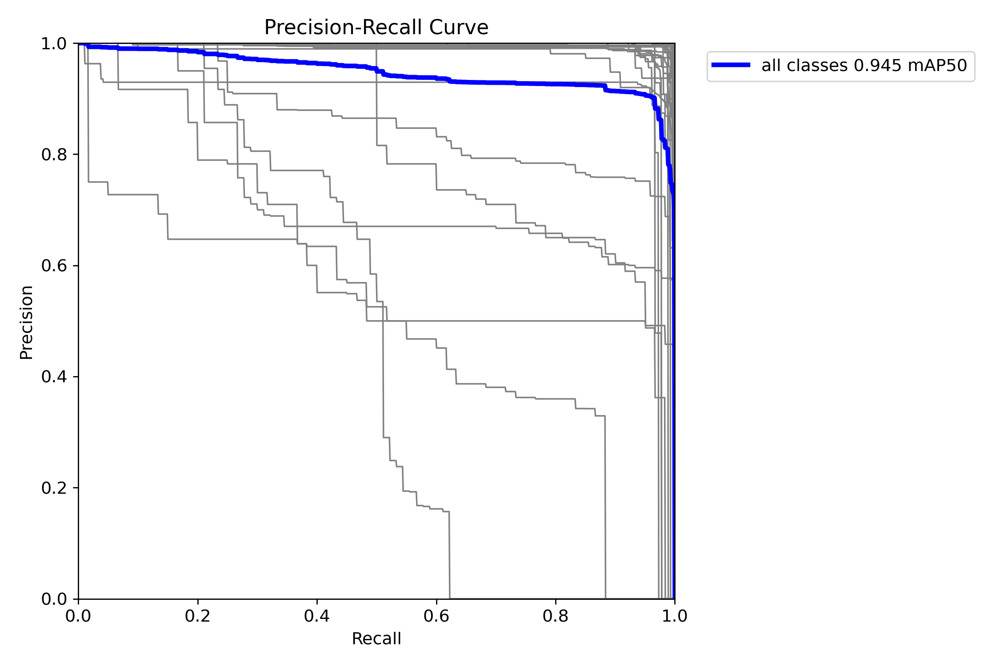


Precision Curve


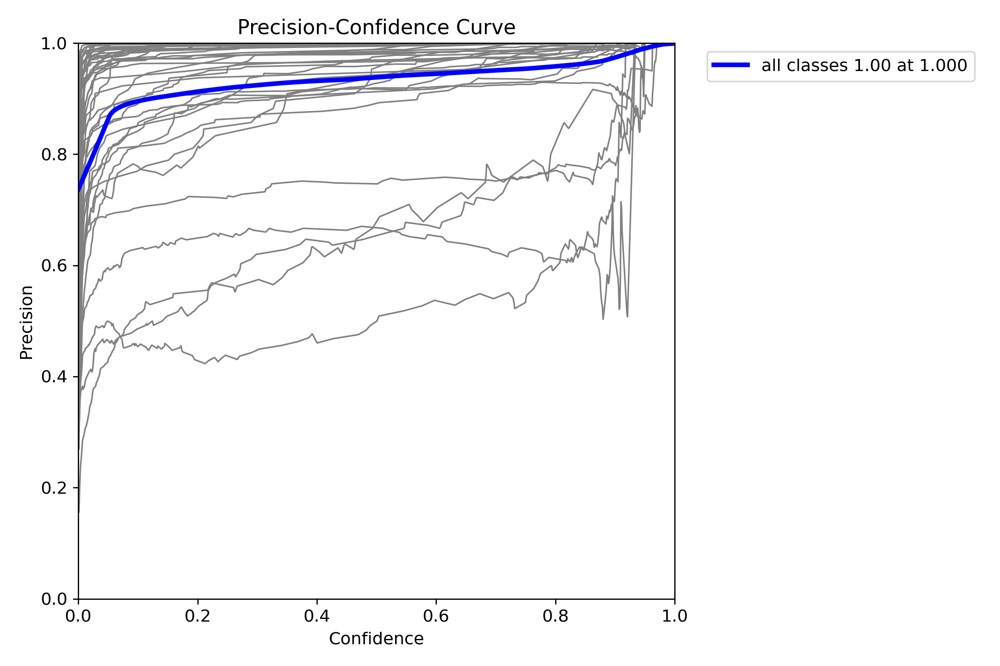


Recall Curve


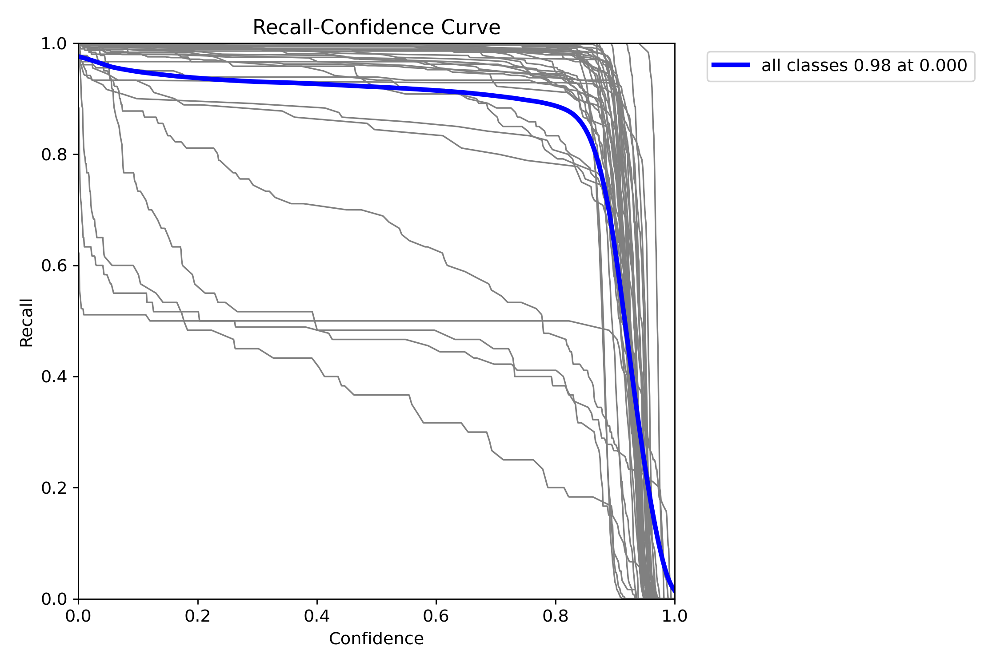


F1 Curve


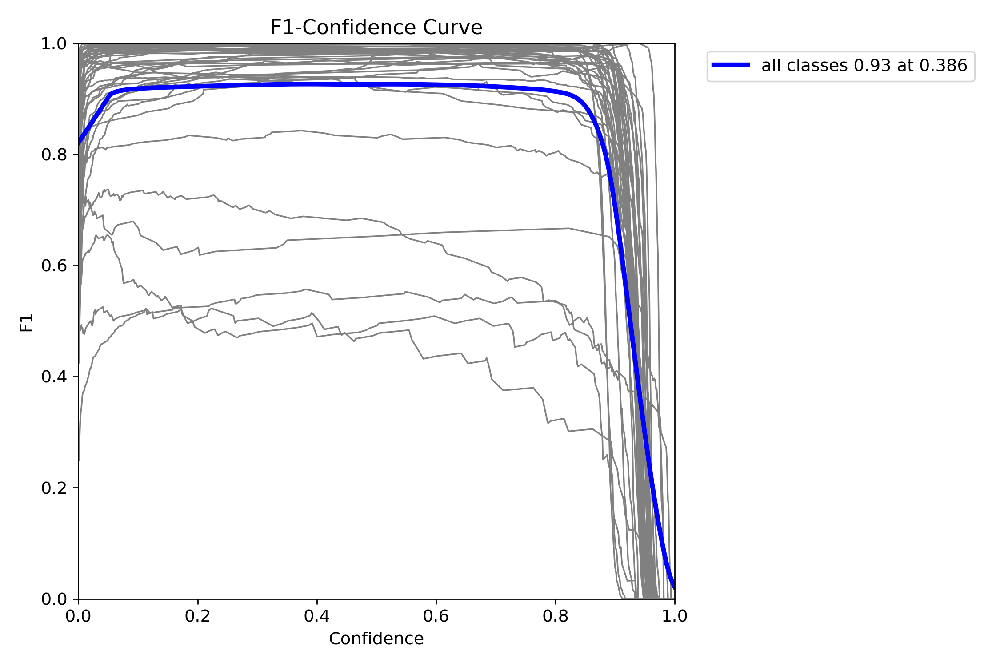


Confusion Matrix


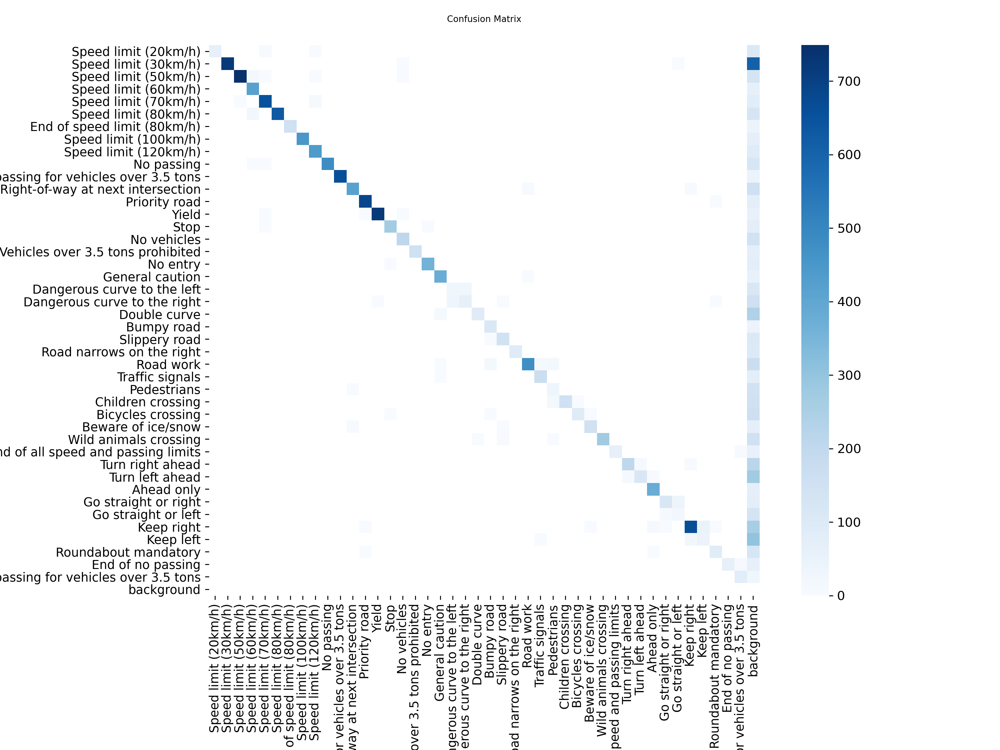


Normalized Confusion Matrix


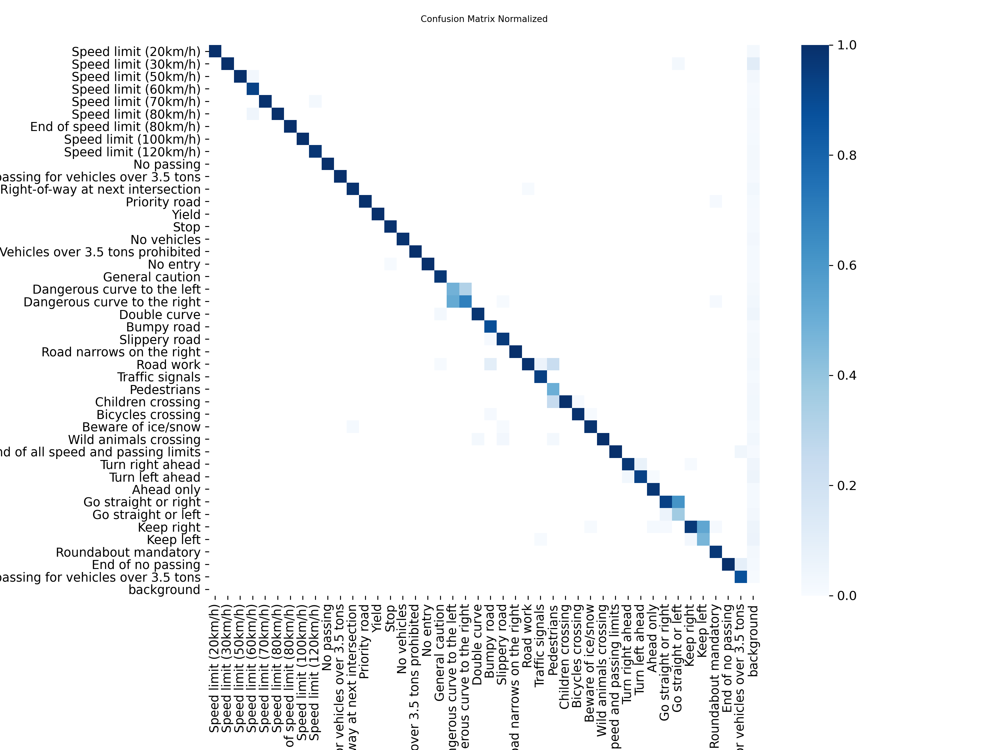


All evaluation plots displayed successfully!


In [ ]:
from pathlib import Path
from IPython.display import display, Image

evaluation_dir = Path(
    "/content/Student5_YOLO_Optimization/final_test_evaluation"
)

plots = [
    ("Precision-Recall Curve", "BoxPR_curve.png"),
    ("Precision Curve", "BoxP_curve.png"),
    ("Recall Curve", "BoxR_curve.png"),
    ("F1 Curve", "BoxF1_curve.png"),
    ("Confusion Matrix", "confusion_matrix.png"),
    (
        "Normalized Confusion Matrix",
        "confusion_matrix_normalized.png"
    )
]

for title, filename in plots:
    plot_path = evaluation_dir / filename

    assert plot_path.exists(), f"Missing plot: {filename}"

    print("\n" + "=" * 50)
    print(title)
    print("=" * 50)

    display(Image(filename=str(plot_path), width=900))

print("\nAll evaluation plots displayed successfully!")


=== GROUND TRUTH VS PREDICTIONS ===

BATCH 0 - GROUND TRUTH


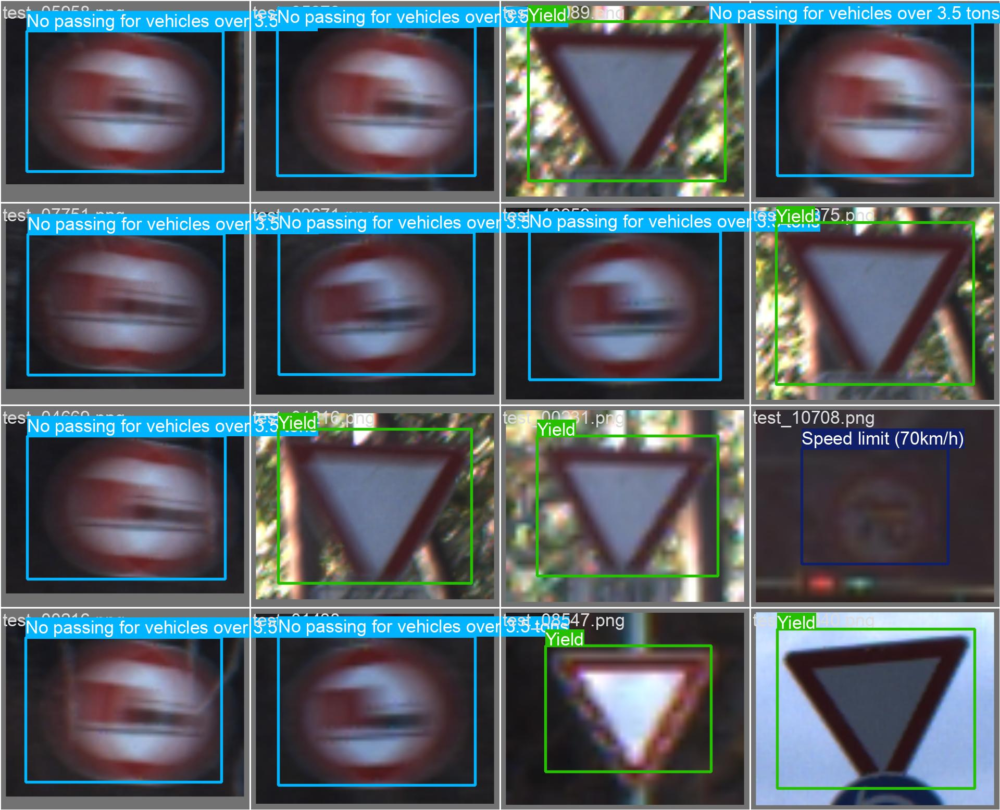


BATCH 0 - MODEL PREDICTIONS


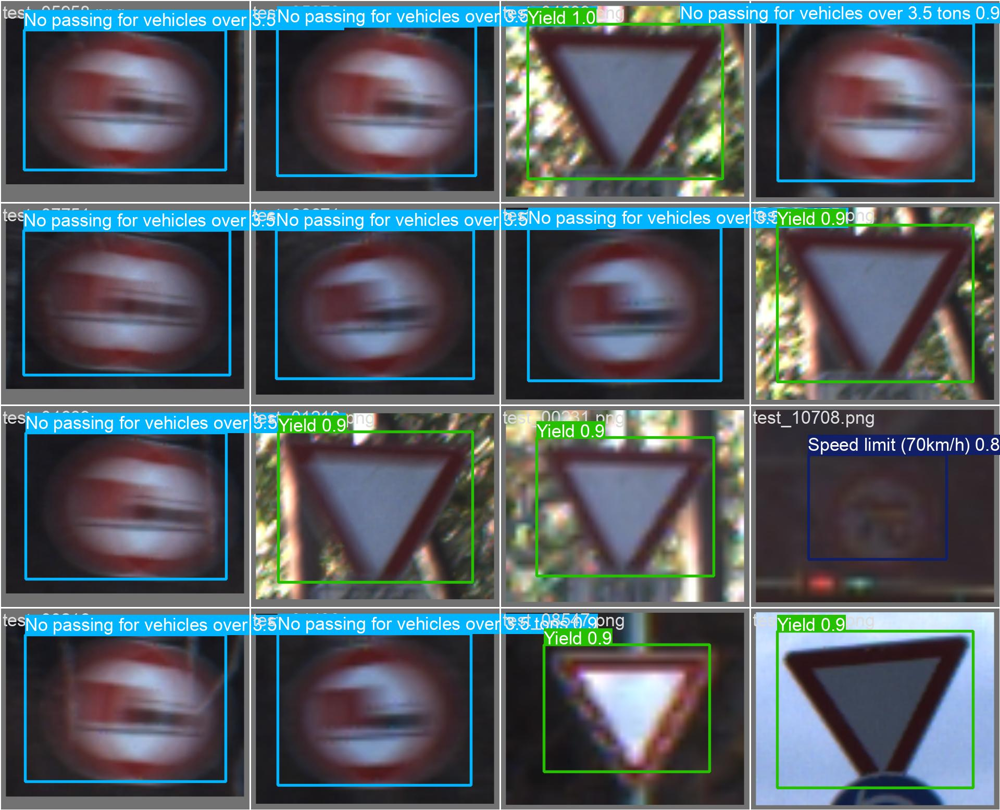


BATCH 1 - GROUND TRUTH


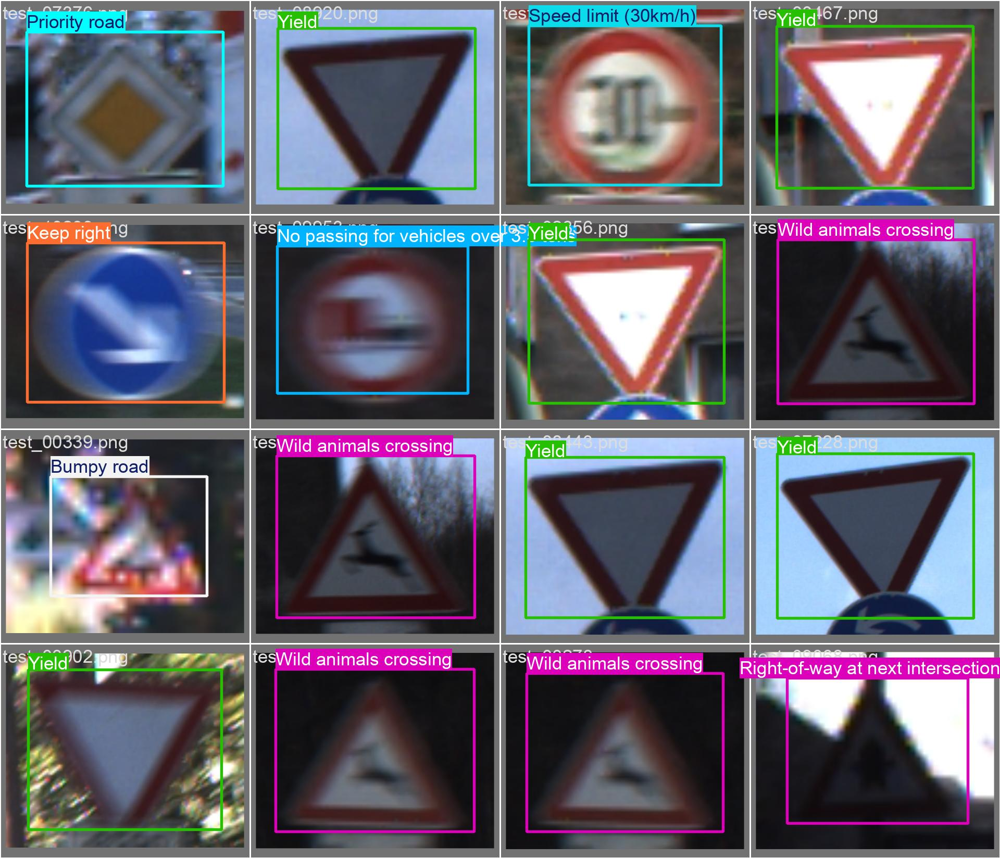


BATCH 1 - MODEL PREDICTIONS


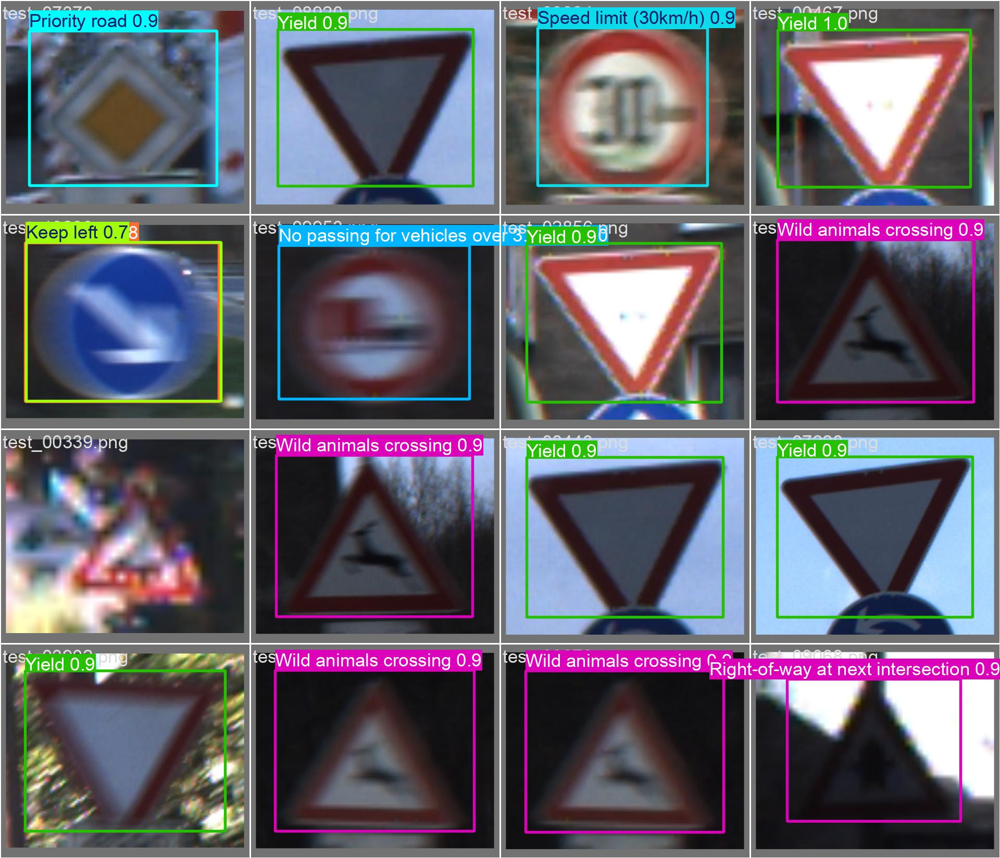


BATCH 2 - GROUND TRUTH


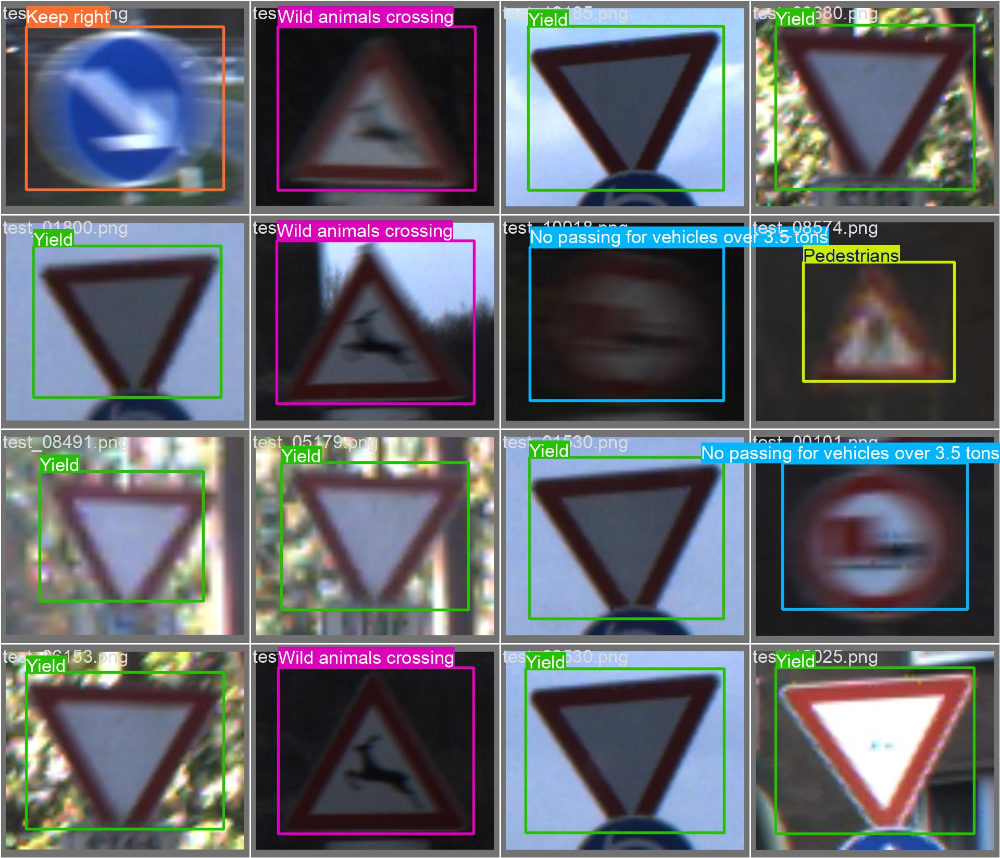


BATCH 2 - MODEL PREDICTIONS


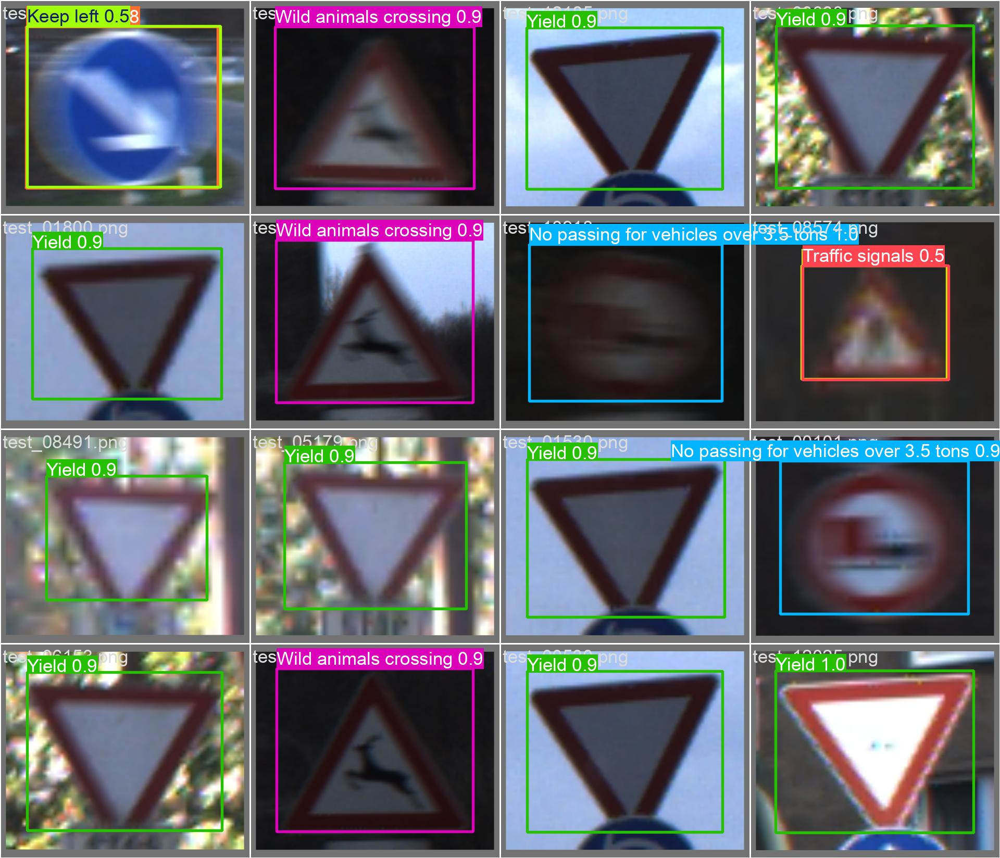


All prediction samples displayed successfully!


In [ ]:
from pathlib import Path
from IPython.display import display, Image

evaluation_dir = Path(
    "/content/Student5_YOLO_Optimization/final_test_evaluation"
)

print("=== GROUND TRUTH VS PREDICTIONS ===")

for i in range(3):

    labels_path = evaluation_dir / f"val_batch{i}_labels.jpg"
    predictions_path = evaluation_dir / f"val_batch{i}_pred.jpg"

    assert labels_path.exists(), f"Missing: {labels_path.name}"
    assert predictions_path.exists(), f"Missing: {predictions_path.name}"

    print(f"\n{'=' * 45}")
    print(f"BATCH {i} - GROUND TRUTH")
    print(f"{'=' * 45}")

    display(Image(filename=str(labels_path), width=900))

    print(f"\nBATCH {i} - MODEL PREDICTIONS")
    print(f"{'=' * 45}")

    display(Image(filename=str(predictions_path), width=900))

print("\nAll prediction samples displayed successfully!")


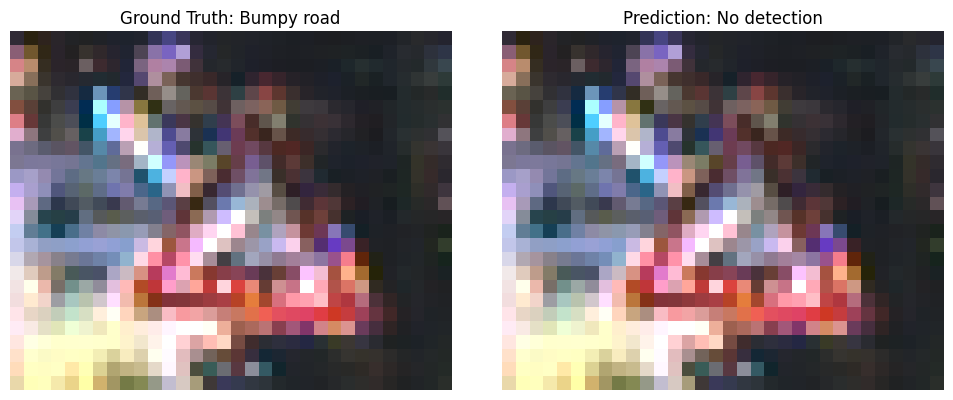

Image: test_00339.png
True class: Bumpy road
Predicted classes: None
--------------------------------------------------


In [ ]:

from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

root = Path("/content/Student5_YOLO_Optimization")
model = YOLO(str(root / "Student5_Best_Model.pt"))

dataset_root = Path("/content/GTSRB_YOLO")
original_csv = pd.read_csv(
    "/kaggle/input/gtsrb-german-traffic-sign/Test.csv"
)

# Examples identified in the evaluation samples
example_indices = [339]

for idx in example_indices:
    image_path = dataset_root / "images" / "test" / f"test_{idx:05d}.png"

    assert image_path.exists(), f"Image not found: {image_path}"

    true_class = int(original_csv.iloc[idx]["ClassId"])
    true_name = model.names[true_class]

    results = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        device=0,
        verbose=False
    )

    result = results[0]

    predicted_names = [
        model.names[int(c)]
        for c in result.boxes.cls.cpu().numpy()
    ]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(Image.open(image_path))
    axes[0].set_title(f"Ground Truth: {true_name}")
    axes[0].axis("off")

    axes[1].imshow(result.plot()[..., ::-1])
    axes[1].set_title(
        "Prediction: " +
        (", ".join(predicted_names) if predicted_names else "No detection")
    )
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

    print("Image:", image_path.name)
    print("True class:", true_name)
    print("Predicted classes:", predicted_names or "None")
    print("-" * 50)


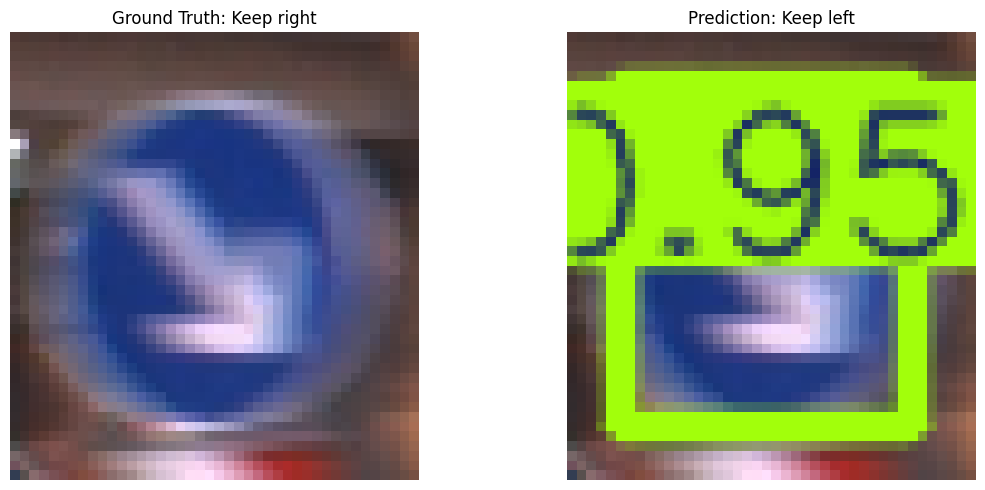

=== MISCLASSIFICATION FOUND ===
Image: test_01383.png
True class: Keep right (38)
Predicted classes: ['Keep left']
Error type: Misclassification


In [ ]:
from pathlib import Path
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

model_path = Path(
    "/content/Student5_YOLO_Optimization/Student5_Best_Model.pt"
)

test_images = Path("/content/GTSRB_YOLO/images/test")
test_labels = Path("/content/GTSRB_YOLO/labels/test")

assert model_path.exists(), "Best model not found!"
assert test_images.exists(), "Test images not found!"
assert test_labels.exists(), "Test labels not found!"

model = YOLO(str(model_path))

# Find a Keep right image incorrectly classified as Keep left
found = False

for label_path in sorted(test_labels.glob("*.txt")):
    lines = label_path.read_text().strip().splitlines()

    if not lines:
        continue

    true_class = int(float(lines[0].split()[0]))

    if true_class != 38:  # Keep right
        continue

    image_path = test_images / (label_path.stem + ".png")

    if not image_path.exists():
        continue

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    predicted_classes = (
        result.boxes.cls.int().cpu().tolist()
        if len(result.boxes) > 0 else []
    )

    if 39 in predicted_classes:  # Keep left
        found = True

        image = cv2.cvtColor(
            cv2.imread(str(image_path)),
            cv2.COLOR_BGR2RGB
        )

        annotated = cv2.cvtColor(
            result.plot(),
            cv2.COLOR_BGR2RGB
        )

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        axes[0].imshow(image)
        axes[0].set_title("Ground Truth: Keep right")
        axes[0].axis("off")

        axes[1].imshow(annotated)
        axes[1].set_title("Prediction: Keep left")
        axes[1].axis("off")

        plt.tight_layout()
        plt.show()

        print("=== MISCLASSIFICATION FOUND ===")
        print("Image:", image_path.name)
        print("True class: Keep right (38)")
        print("Predicted classes:", [model.names[i] for i in predicted_classes])
        print("Error type: Misclassification")

        break

if not found:
    print("No Keep right -> Keep left example found at confidence 0.25.")

Searching for an extra False Positive detection...


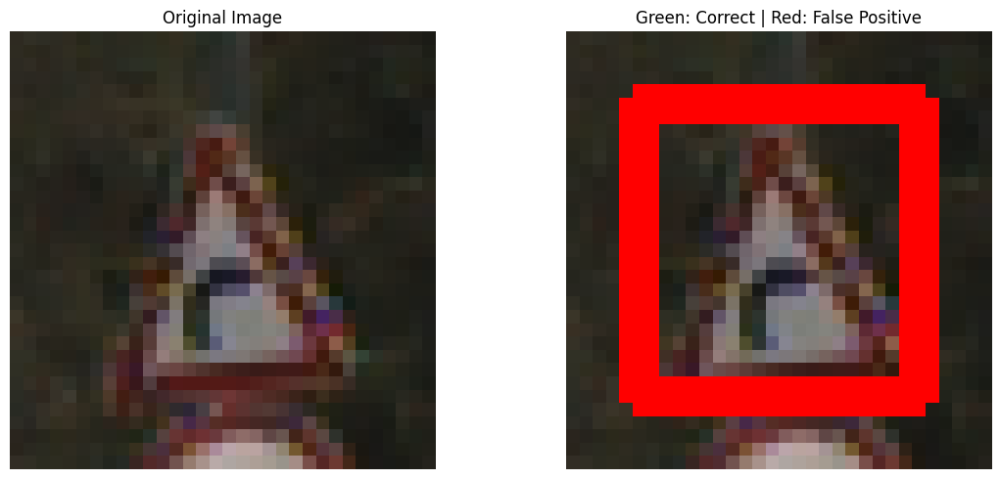


=== FALSE POSITIVE FOUND ===
Image: test_00017.png
Correct detections: 1
False positives: 1
False Positive: Dangerous curve to the left | Confidence: 0.444
Saved to: /content/Student5_YOLO_Optimization/error_analysis/false_positive_example.png


In [ ]:
from pathlib import Path
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Paths
root = Path("/content/GTSRB_YOLO")
images_dir = root / "images/test"
labels_dir = root / "labels/test"

model_path = Path(
    "/content/Student5_YOLO_Optimization/Student5_Best_Model.pt"
)

output_dir = Path(
    "/content/Student5_YOLO_Optimization/error_analysis"
)
output_dir.mkdir(parents=True, exist_ok=True)

assert model_path.exists()
assert images_dir.exists()
assert labels_dir.exists()

model = YOLO(str(model_path))

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0

found = False

print("Searching for an extra False Positive detection...")

for image_path in sorted(images_dir.glob("*.png")):

    label_path = labels_dir / (image_path.stem + ".txt")

    if not label_path.exists():
        continue

    image = cv2.imread(str(image_path))
    if image is None:
        continue

    h, w = image.shape[:2]

    # Read all ground-truth boxes
    gt_objects = []

    for line in label_path.read_text().splitlines():
        values = line.split()
        if len(values) != 5:
            continue

        cls = int(float(values[0]))
        xc, yc, bw, bh = map(float, values[1:])

        gt_box = [
            (xc - bw/2) * w,
            (yc - bh/2) * h,
            (xc + bw/2) * w,
            (yc + bh/2) * h
        ]

        gt_objects.append((cls, gt_box))

    if not gt_objects:
        continue

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    if len(result.boxes) < 2:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    classes = result.boxes.cls.int().cpu().numpy()
    confidences = result.boxes.conf.cpu().numpy()

    correct_indices = []
    false_positive_indices = []

    # Match predictions to ground truth one-to-one
    matched_gt = set()

    order = np.argsort(-confidences)

    for i in order:
        best_iou = 0
        best_gt = None

        for j, (gt_cls, gt_box) in enumerate(gt_objects):
            if j in matched_gt or classes[i] != gt_cls:
                continue

            iou = calculate_iou(boxes[i], gt_box)

            if iou > best_iou:
                best_iou = iou
                best_gt = j

        if best_gt is not None and best_iou >= 0.5:
            correct_indices.append(i)
            matched_gt.add(best_gt)
        else:
            false_positive_indices.append(i)

    if correct_indices and false_positive_indices:

        found = True

        annotated = image.copy()

        # Correct detections in green
        for i in correct_indices:
            x1, y1, x2, y2 = boxes[i].astype(int)
            cv2.rectangle(
                annotated, (x1, y1), (x2, y2),
                (0, 255, 0), 2
            )

        # False positives in red
        for i in false_positive_indices:
            x1, y1, x2, y2 = boxes[i].astype(int)
            cv2.rectangle(
                annotated, (x1, y1), (x2, y2),
                (0, 0, 255), 2
            )

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))

        axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        axes[0].set_title("Original Image")
        axes[0].axis("off")

        axes[1].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
        axes[1].set_title(
            "Green: Correct | Red: False Positive"
        )
        axes[1].axis("off")

        plt.tight_layout()

        save_path = output_dir / "false_positive_example.png"
        plt.savefig(save_path, dpi=200, bbox_inches="tight")
        plt.show()

        print("\n=== FALSE POSITIVE FOUND ===")
        print("Image:", image_path.name)
        print("Correct detections:", len(correct_indices))
        print("False positives:", len(false_positive_indices))

        for i in false_positive_indices:
            print(
                "False Positive:",
                model.names[int(classes[i])],
                "| Confidence:",
                round(float(confidences[i]), 4)
            )

        print("Saved to:", save_path)
        break

if not found:
    print(
        "No image with both a correct detection "
        "and an extra false positive was found."
    )

In [ ]:
from pathlib import Path

root = Path("/content/Student5_YOLO_Optimization")
error_dir = root / "error_analysis"

print("=== ERROR ANALYSIS FILE CHECK ===")

print("Error analysis folder:", error_dir.exists())

if error_dir.exists():
    for file in sorted(error_dir.iterdir()):
        print(file.name, "|", round(file.stat().st_size / 1024, 2), "KB")

print("\nFinal model:", (root / "Student5_Best_Model.pt").exists())
print("Test metrics:", (root / "Student5_Final_Test_Metrics.json").exists())
print("Experiment comparison:", (root / "Student5_Experiment_Comparison.csv").exists())

=== ERROR ANALYSIS FILE CHECK ===
Error analysis folder: True
false_positive_example.png | 32.17 KB

Final model: True
Test metrics: True
Experiment comparison: True


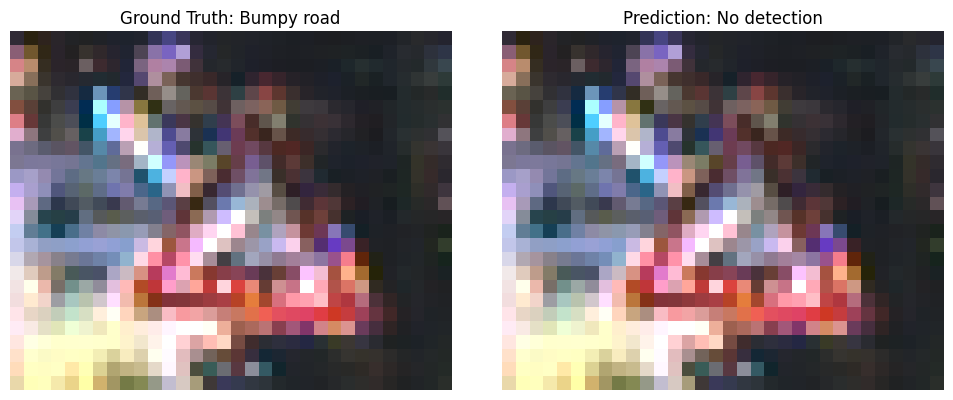

Saved: false_negative_example.png
Predicted classes: []
--------------------------------------------------


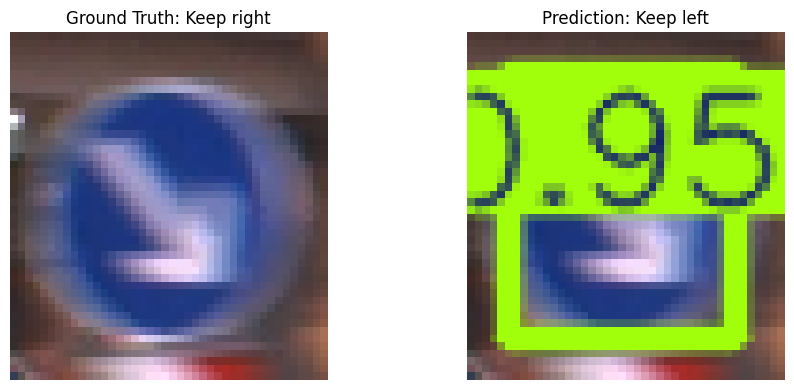

Saved: misclassification_example.png
Predicted classes: ['Keep left']
--------------------------------------------------

=== FINAL ERROR ANALYSIS FILES ===
false_negative_example.png
false_positive_example.png
misclassification_example.png

Total PNG files: 3


In [ ]:
from pathlib import Path
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2

root = Path("/content/Student5_YOLO_Optimization")
error_dir = root / "error_analysis"
error_dir.mkdir(parents=True, exist_ok=True)

images_dir = Path("/content/GTSRB_YOLO/images/test")
model = YOLO(str(root / "Student5_Best_Model.pt"))

examples = [
    ("test_00339.png", "Bumpy road", "false_negative_example.png"),
    ("test_01383.png", "Keep right", "misclassification_example.png")
]

for filename, true_class, output_name in examples:

    image_path = images_dir / filename
    assert image_path.exists(), f"Missing image: {filename}"

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    original = cv2.cvtColor(
        cv2.imread(str(image_path)),
        cv2.COLOR_BGR2RGB
    )

    predicted = cv2.cvtColor(
        result.plot(),
        cv2.COLOR_BGR2RGB
    )

    predicted_names = [
        model.names[int(i)]
        for i in result.boxes.cls.cpu().tolist()
    ]

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(original)
    axes[0].set_title(f"Ground Truth: {true_class}")
    axes[0].axis("off")

    axes[1].imshow(predicted)
    axes[1].set_title(
        "Prediction: " +
        (", ".join(predicted_names) if predicted_names else "No detection")
    )
    axes[1].axis("off")

    plt.tight_layout()

    save_path = error_dir / output_name
    plt.savefig(save_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Saved:", save_path.name)
    print("Predicted classes:", predicted_names)
    print("-" * 50)

print("\n=== FINAL ERROR ANALYSIS FILES ===")

for file in sorted(error_dir.glob("*.png")):
    print(file.name)

print("\nTotal PNG files:", len(list(error_dir.glob("*.png"))))

Available columns:
['Experiment', 'Best Epoch', 'Image Size', 'Batch Size', 'Learning Rate', 'Precision', 'Recall', 'mAP50', 'mAP50-95']

=== EXPERIMENT COMPARISON ===


,Experiment,Best Epoch,Image Size,Batch Size,Learning Rate,Precision,Recall,mAP50,mAP50-95
0,Experiment 1,10,640,16,0.0010,0.92758,0.93696,0.95644,0.89678
1,Experiment 4,8,512,16,0.0010,0.93913,0.92840,0.95745,0.89677
2,Experiment 3,9,640,16,0.0005,0.90680,0.93731,0.94726,0.89256
3,Experiment 2,10,640,32,0.0005,0.91472,0.93059,0.94243,0.88700


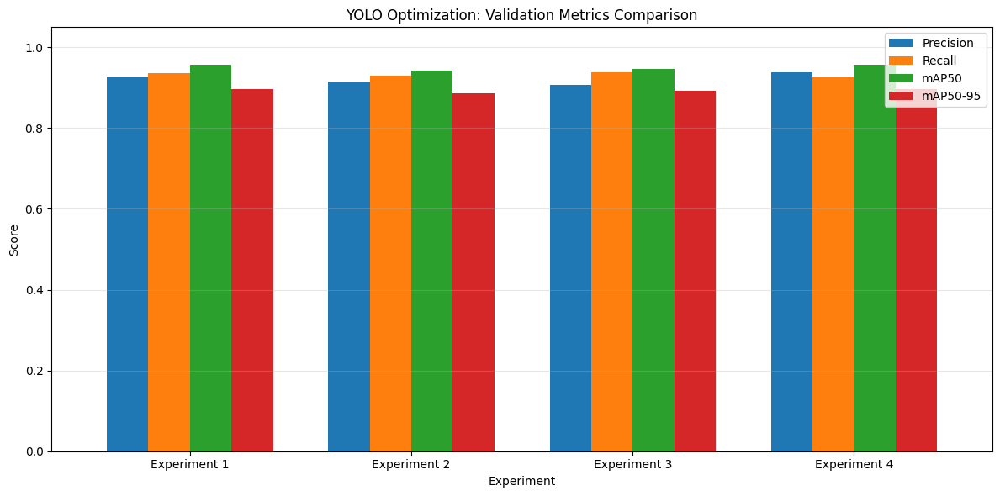

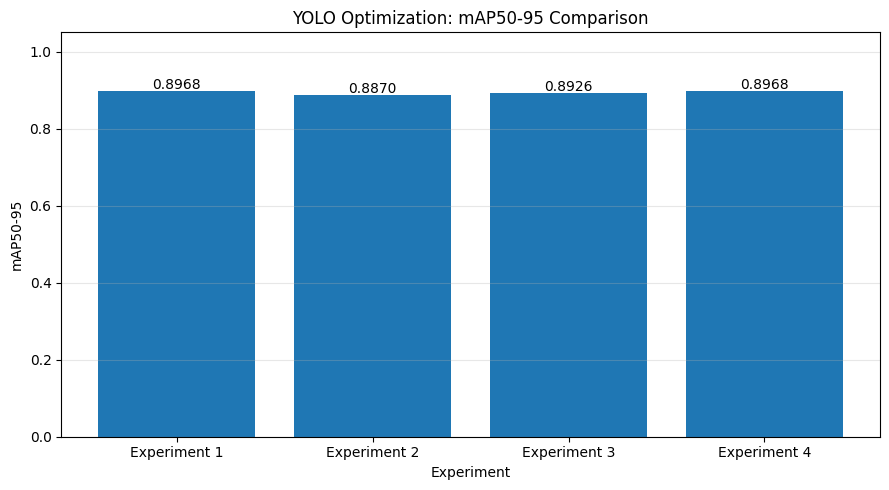


=== SAVED PLOTS ===
Student5_Validation_Metrics_Comparison.png : True
Student5_mAP50_95_Comparison.png : True


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

root = Path("/content/Student5_YOLO_Optimization")
csv_path = root / "Student5_Experiment_Comparison.csv"

assert csv_path.exists(), "Experiment comparison CSV not found!"

df = pd.read_csv(csv_path)

print("Available columns:")
print(df.columns.tolist())

print("\n=== EXPERIMENT COMPARISON ===")
display(df)

# Find the metric columns
metric_columns = {
    "Precision": "Precision",
    "Recall": "Recall",
    "mAP50": "mAP50",
    "mAP50-95": "mAP50-95"
}

required = ["Experiment"] + list(metric_columns.values())
assert all(c in df.columns for c in required), "Unexpected CSV columns!"

df = df.sort_values("Experiment")

# Plot 1: All validation metrics
ax = df.plot(
    x="Experiment",
    y=list(metric_columns.values()),
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

ax.set_title("YOLO Optimization: Validation Metrics Comparison")
ax.set_xlabel("Experiment")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()

plot1 = root / "Student5_Validation_Metrics_Comparison.png"
plt.savefig(plot1, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

# Plot 2: mAP50-95 comparison
plt.figure(figsize=(9, 5))

bars = plt.bar(
    df["Experiment"],
    df["mAP50-95"]
)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.005,
        f"{height:.4f}",
        ha="center"
    )

plt.title("YOLO Optimization: mAP50-95 Comparison")
plt.xlabel("Experiment")
plt.ylabel("mAP50-95")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plot2 = root / "Student5_mAP50_95_Comparison.png"
plt.savefig(plot2, dpi=200, bbox_inches="tight")
plt.show()
plt.close()

print("\n=== SAVED PLOTS ===")
print(plot1.name, ":", plot1.exists())
print(plot2.name, ":", plot2.exists())

In [ ]:
from pathlib import Path

root = Path("/content/Student5_YOLO_Optimization")

print("=== FINAL PROJECT FILES ===")

for file in sorted(root.iterdir()):
    if file.is_file():
        print(file.name)

print("\n=== FINAL MODEL CHECK ===")
model_path = root / "Student5_Best_Model.pt"
print("Final model exists:", model_path.exists())

=== FINAL PROJECT FILES ===
Student5_Best_Model.pt
Student5_Experiment_Comparison.csv
Student5_Final_Test_Metrics.json
Student5_Validation_Metrics_Comparison.png
Student5_mAP50_95_Comparison.png

=== FINAL MODEL CHECK ===
Final model exists: True


In [ ]:
from pathlib import Path
import zipfile

root = Path("/content/Student5_YOLO_Optimization")
zip_path = Path("/content/Student5_Final_Delivery.zip")

required_files = [
    "Student5_Best_Model.pt",
    "Student5_Final_Test_Metrics.json",
    "Student5_Experiment_Comparison.csv",
    "Student5_Validation_Metrics_Comparison.png",
    "Student5_mAP50_95_Comparison.png",
]

print("=== CHECKING REQUIRED FILES ===")

for name in required_files:
    file_path = root / name
    print(f"{name}: {file_path.exists()}")
    assert file_path.exists(), f"Missing: {name}"

print("\n=== CHECKING ERROR ANALYSIS ===")

error_dir = root / "error_analysis"

assert error_dir.exists(), "Error analysis folder missing!"

for name in [
    "false_negative_example.png",
    "false_positive_example.png",
    "misclassification_example.png",
]:
    file_path = error_dir / name
    print(f"{name}: {file_path.exists()}")
    assert file_path.exists(), f"Missing: {name}"

print("\n=== CREATING FINAL DELIVERY ZIP ===")

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for file_path in root.rglob("*"):

        if not file_path.is_file():
            continue

        relative_path = file_path.relative_to(root)

        # Exclude large experiment training folders
        if any(
            part.startswith("experiment_")
            for part in relative_path.parts
        ):
            continue

        z.write(file_path, arcname=str(relative_path))

print("\n=== FINAL ZIP CREATED ===")
print("Filename:", zip_path.name)
print(
    "Size:",
    round(zip_path.stat().st_size / (1024 ** 2), 2),
    "MB"
)

with zipfile.ZipFile(zip_path) as z:
    print("Files inside ZIP:", len(z.namelist()))
    print(
        "ZIP integrity:",
        "OK" if z.testzip() is None else "FAILED"
    )

=== CHECKING REQUIRED FILES ===
Student5_Best_Model.pt: True
Student5_Final_Test_Metrics.json: True
Student5_Experiment_Comparison.csv: True
Student5_Validation_Metrics_Comparison.png: True
Student5_mAP50_95_Comparison.png: True

=== CHECKING ERROR ANALYSIS ===
false_negative_example.png: True
false_positive_example.png: True
misclassification_example.png: True

=== CREATING FINAL DELIVERY ZIP ===

=== FINAL ZIP CREATED ===
Filename: Student5_Final_Delivery.zip
Size: 8.36 MB
Files inside ZIP: 20
ZIP integrity: OK


In [ ]:
from google.colab import files
from pathlib import Path

zip_path = Path("/content/Student5_Final_Delivery.zip")

assert zip_path.exists(), "Final ZIP not found!"

files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
from pathlib import Path
import shutil

road_dir = Path("/content/Student5_YOLO_Optimization/road_test_images")
road_dir.mkdir(parents=True, exist_ok=True)

print("Upload 3–5 road images (JPG or PNG)")

uploaded = files.upload()

for filename, content in uploaded.items():
    if Path(filename).suffix.lower() not in [".jpg", ".jpeg", ".png"]:
        print("Skipped unsupported file:", filename)
        continue

    destination = road_dir / Path(filename).name
    destination.write_bytes(content)
    print("Saved:", destination.name)

print("\nTotal road images:", len([
    p for p in road_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]))

Upload 3–5 road images (JPG or PNG)


Saving 1280px-Autobahn-bremen-120_hg.jpg to 1280px-Autobahn-bremen-120_hg.jpg
Saving 1280px-Road_sign_Germany_-_Way_to_school.jpg to 1280px-Road_sign_Germany_-_Way_to_school.jpg
Saving 1280px-Traffic_sign_in_Germany.jpg to 1280px-Traffic_sign_in_Germany.jpg
Saving 1280px-Verkehrsregeln_in_Deutschland.JPG to 1280px-Verkehrsregeln_in_Deutschland.JPG
Saved: 1280px-Autobahn-bremen-120_hg.jpg
Saved: 1280px-Road_sign_Germany_-_Way_to_school.jpg
Saved: 1280px-Traffic_sign_in_Germany.jpg
Saved: 1280px-Verkehrsregeln_in_Deutschland.JPG

Total road images: 4


Results saved to /content/Student5_YOLO_Optimization/road_test_results

Image: 1280px-Autobahn-bremen-120_hg.jpg
Detections: 0


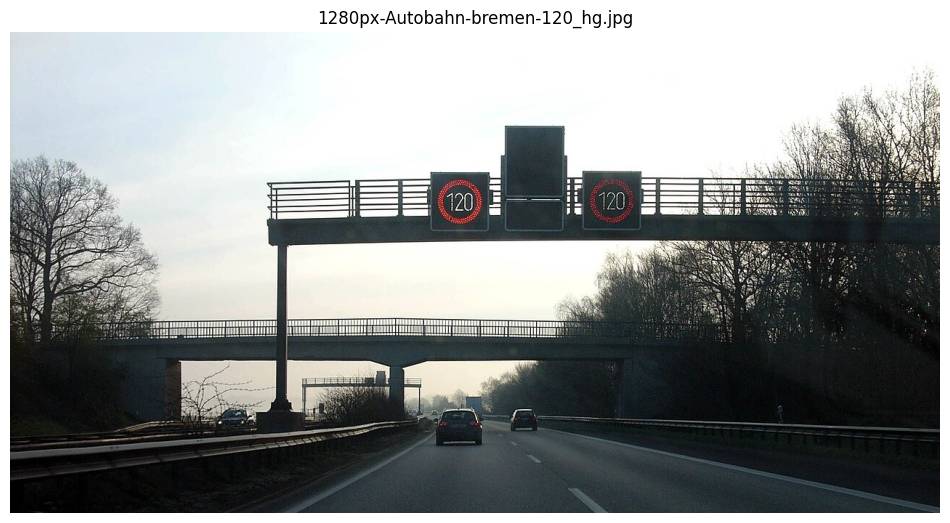


Image: 1280px-Road_sign_Germany_-_Way_to_school.jpg
Detections: 0


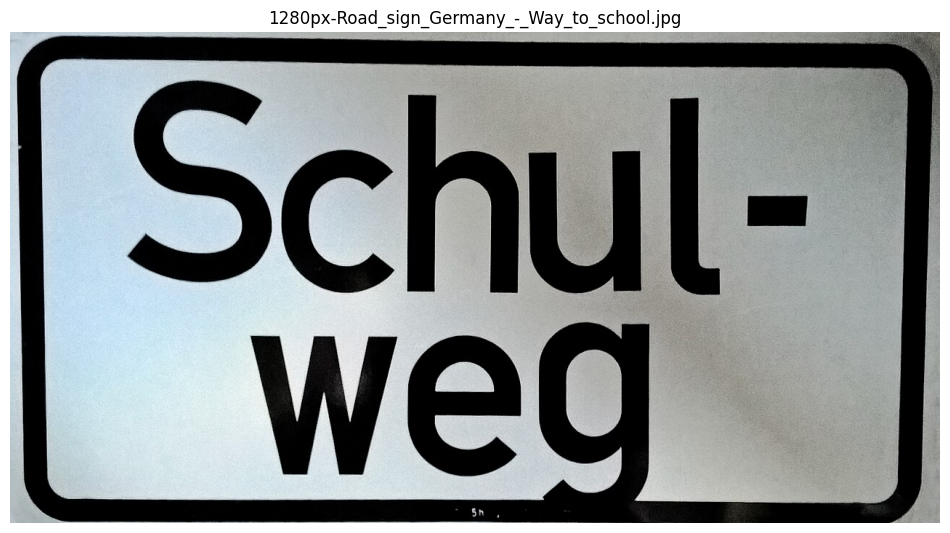


Image: 1280px-Traffic_sign_in_Germany.jpg
Detections: 0


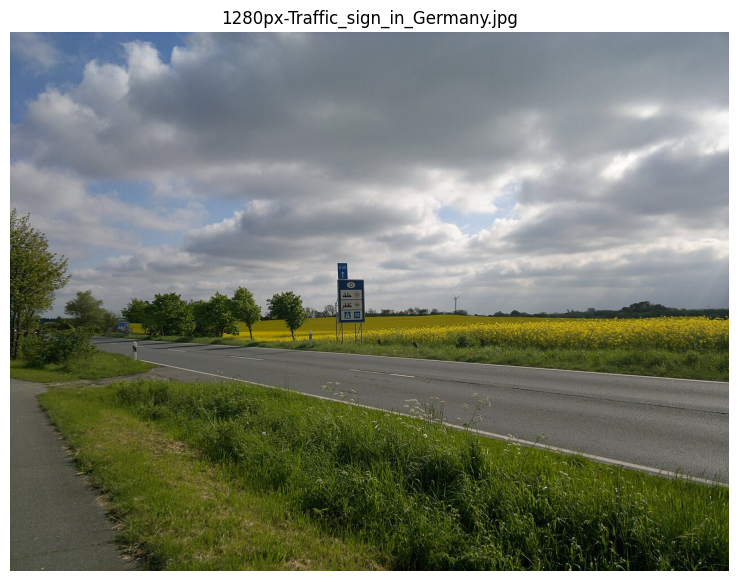


Image: 1280px-Verkehrsregeln_in_Deutschland.JPG
Detections: 0


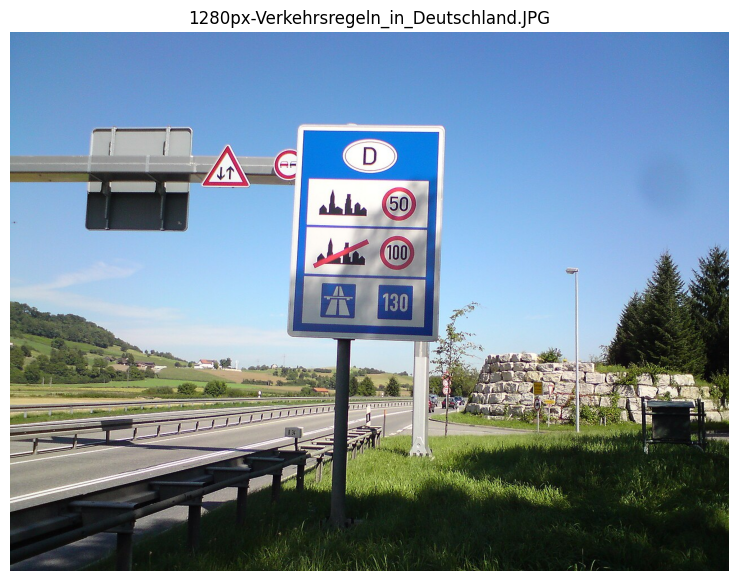


Results saved in: /content/Student5_YOLO_Optimization/road_test_results


In [ ]:

from pathlib import Path
from ultralytics import YOLO
import matplotlib.pyplot as plt

# Paths
root = Path("/content/Student5_YOLO_Optimization")
model_path = root / "Student5_Best_Model.pt"
road_dir = root / "road_test_images"
output_dir = root / "road_test_results"

# Verify files
assert model_path.exists(), "Final model not found!"
assert road_dir.exists(), "Road images folder not found!"

images = sorted(
    p for p in road_dir.iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

assert len(images) > 0, "No road images found!"

# Load optimized model
model = YOLO(str(model_path))

# Run inference
results = model.predict(
    source=[str(p) for p in images],
    imgsz=640,
    conf=0.25,
    save=True,
    project=str(root),
    name="road_test_results",
    exist_ok=True,
    verbose=False
)

# Display results
for image_path, result in zip(images, results):
    print("\nImage:", image_path.name)
    print("Detections:", len(result.boxes))

    for box in result.boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())
        print(f"  {model.names[class_id]}: {confidence:.3f}")

    plt.figure(figsize=(12, 7))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.axis("off")
    plt.title(image_path.name)
    plt.show()

print("\nResults saved in:", output_dir)


In [ ]:

from pathlib import Path
from ultralytics import YOLO

root = Path("/content/Student5_YOLO_Optimization")
model = YOLO(str(root / "Student5_Best_Model.pt"))

images = sorted(
    p for p in (root / "road_test_images").iterdir()
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

results = model.predict(
    source=[str(p) for p in images],
    imgsz=640,
    conf=0.05,
    save=True,
    project=str(root),
    name="road_test_results_low_conf",
    exist_ok=True,
    verbose=False
)

for image, result in zip(images, results):
    print(f"\n{image.name}")
    print("Detections:", len(result.boxes))

    for box in result.boxes:
        class_id = int(box.cls.item())
        confidence = float(box.conf.item())
        print(f"  {model.names[class_id]}: {confidence:.3f}")

print("\nLow-confidence test completed!")


Results saved to /content/Student5_YOLO_Optimization/road_test_results_low_conf

1280px-Autobahn-bremen-120_hg.jpg
Detections: 0

1280px-Road_sign_Germany_-_Way_to_school.jpg
Detections: 0

1280px-Traffic_sign_in_Germany.jpg
Detections: 0

1280px-Verkehrsregeln_in_Deutschland.JPG
Detections: 0

Low-confidence test completed!


In [ ]:

from pathlib import Path
import json

root = Path("/content/Student5_YOLO_Optimization")

road_test_summary = {
    "test_name": "External Road Scene Evaluation",
    "number_of_images": 4,
    "dataset": "External road/sign photographs",
    "model": "Student5_Best_Model.pt",
    "image_size": 640,
    "confidence_thresholds": [0.25, 0.05],
    "detections_at_0_25": 0,
    "detections_at_0_05": 0,
    "observations": [
        "No bounding boxes were produced for the four external images.",
        "Some signs are small relative to the full image.",
        "Some signs are outside the 43 trained GTSRB classes.",
        "The external results indicate limited generalization to these scenes."
    ],
    "limitations": (
        "This is a small qualitative test, not a statistically "
        "representative benchmark. No external ground-truth "
        "annotations were used."
    )
}

output_path = root / "Student5_External_Road_Test_Summary.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(road_test_summary, f, indent=4, ensure_ascii=False)

print("Saved:", output_path)
print("External road test documentation completed!")


Saved: /content/Student5_YOLO_Optimization/Student5_External_Road_Test_Summary.json
External road test documentation completed!


In [ ]:

from pathlib import Path
import zipfile

root = Path("/content/Student5_YOLO_Optimization")
zip_path = Path("/content/Student5_Final_Delivery_Updated.zip")

# Verify essential files
required = [
    "Student5_Best_Model.pt",
    "Student5_Final_Test_Metrics.json",
    "Student5_Experiment_Comparison.csv",
    "Student5_External_Road_Test_Summary.json"
]

for name in required:
    assert (root / name).is_file(), f"Missing: {name}"

# Verify external test images and results
for folder in [
    "road_test_images",
    "road_test_results",
    "road_test_results_low_conf",
    "error_analysis"
]:
    assert (root / folder).is_dir(), f"Missing folder: {folder}"

# Create updated ZIP
with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for file in root.rglob("*"):
        if not file.is_file():
            continue

        relative = file.relative_to(root)

        # Experiment backups are already saved separately
        if any(
            part.startswith("experiment_")
            for part in relative.parts
        ):
            continue

        z.write(file, arcname=str(relative))

# Verify ZIP integrity
with zipfile.ZipFile(zip_path) as z:
    count = len(z.namelist())
    integrity = z.testzip()

print("=== UPDATED FINAL DELIVERY ===")
print("Filename:", zip_path.name)
print("Size:", round(zip_path.stat().st_size / (1024**2), 2), "MB")
print("Files inside:", count)
print("ZIP integrity:", "OK" if integrity is None else integrity)


=== UPDATED FINAL DELIVERY ===
Filename: Student5_Final_Delivery_Updated.zip
Size: 11.8 MB
Files inside: 33
ZIP integrity: OK


In [ ]:

from google.colab import files
from pathlib import Path

zip_path = Path("/content/Student5_Final_Delivery_Updated.zip")

assert zip_path.exists(), "Updated ZIP not found!"

files.download(str(zip_path))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Student 6 Model Integration & Final Evaluation

Pipeline:** Input image → YOLO detection → crop detected signs → CNN classification → final predictions

**Before running, upload these files to `/content`:**
| File | From |
|---|---|
| `best_cnn_final.keras` | Student 3 (`/content/Optimization_output/`) |
| `Student5_Best_Model.pt` | Student 5 |
| `Student5_Final_Test_Metrics.json` | Student 5 (optional – only printed for reference) |
| `road_test_images/` (a few JPG/PNG road photos) | Student 5 (optional) |

Run the cells top to bottom. This notebook is self-contained: it re-downloads GTSRB and does not depend on the other students' runtime variables.

In [ ]:
!pip install -q ultralytics==8.4.212 kagglehub

In [ ]:
import json, time, zipfile, random, sys
from pathlib import Path

import cv2
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import torch
from IPython.display import display
from scipy.stats import binomtest
from sklearn.metrics import precision_recall_fscore_support

# TensorFlow (CNN) and PyTorch (YOLO) share one GPU: stop TF from reserving all of it.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

SEED = 42
random.seed(SEED); np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED); torch.manual_seed(SEED)

# ---------- inputs ----------
CNN_PATH   = Path("/content/best_cnn_final.keras")             # Student 3
YOLO_PATH  = Path("/content/Student5_Best_Model.pt")           # Student 5
S5_METRICS = Path("/content/Student5_Final_Test_Metrics.json") # Student 5 (optional)
ROAD_DIR   = Path("/content/road_test_images")                 # optional

# ---------- pipeline settings (fixed up-front, NOT tuned on the test set) ----------
YOLO_IMGSZ = 640    # same image size Student 5 selected
DET_CONF   = 0.25   # YOLO confidence threshold
CROP_PAD   = 0.10   # context added around each box before the CNN (CNN was trained on whole GTSRB frames)
CNN_SIZE   = 64     # CNN input size (Student 1 preprocessing)
MATCH_IOU  = 0.5    # a detection counts as correct localisation if IoU >= 0.5

OUT = Path("/content/Student6_output"); OUT.mkdir(parents=True, exist_ok=True)
for p in (CNN_PATH, YOLO_PATH):
    assert p.exists(), f"Missing {p} - upload it first"
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("TensorFlow", tf.__version__, "| PyTorch", torch.__version__)

GPU: Tesla T4
TensorFlow 2.21.0 | PyTorch 2.14.1+cu130


## 1. Integrated pipeline (saved as a reusable module)
The same code path is used for evaluation, timing and visualisation, so all numbers describe the same system.
The CNN preprocessing copies Student 1 exactly: RGB → `tf.image.resize` to 64×64 → divide by 255.

In [ ]:
%%writefile /content/traffic_sign_pipeline.py
"""Integrated traffic-sign recognition: YOLO detection -> crop -> CNN classification."""
import time
import numpy as np
import cv2
import tensorflow as tf
import torch
from ultralytics import YOLO


def sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


class TrafficSignRecognizer:
    def __init__(self, yolo_path, cnn_path, imgsz=640, conf=0.25, crop_pad=0.10,
                 cnn_size=64, device=0 if torch.cuda.is_available() else "cpu"):
        self.yolo = YOLO(str(yolo_path))
        self.cnn = tf.keras.models.load_model(str(cnn_path))
        self.imgsz, self.conf, self.crop_pad = imgsz, conf, crop_pad
        self.cnn_size, self.device = cnn_size, device
        self.names = {int(k): v for k, v in self.yolo.names.items()}
        n_cnn = int(self.cnn.output_shape[-1])
        if sorted(self.names) != list(range(n_cnn)):
            raise ValueError(f"Class mismatch: YOLO has {len(self.names)} classes, CNN outputs {n_cnn}")

    # ---- stage 1: detection ----
    def detect(self, sources, batch=64):
        """sources: list of image paths or BGR ndarrays."""
        return self.yolo.predict(source=sources, imgsz=self.imgsz, conf=self.conf,
                                 device=self.device, batch=batch, verbose=False)

    # ---- stage 2: crop ----
    def crop(self, img_bgr, box):
        h, w = img_bgr.shape[:2]
        x1, y1, x2, y2 = [float(v) for v in box]
        px, py = (x2 - x1) * self.crop_pad, (y2 - y1) * self.crop_pad
        x1 = int(min(max(0, np.floor(x1 - px)), w - 1))
        y1 = int(min(max(0, np.floor(y1 - py)), h - 1))
        x2 = int(min(w, max(np.ceil(x2 + px), x1 + 1)))
        y2 = int(min(h, max(np.ceil(y2 + py), y1 + 1)))
        return cv2.cvtColor(img_bgr[y1:y2, x1:x2], cv2.COLOR_BGR2RGB)

    # ---- stage 3: classification ----
    def preprocess(self, crops_rgb):
        out = [tf.cast(tf.image.resize(c, (self.cnn_size, self.cnn_size)), tf.float32) / 255.0
               for c in crops_rgb]
        return tf.stack(out)

    def classify(self, crops_rgb):
        if len(crops_rgb) == 0:
            return np.empty(0, dtype=int), np.empty(0, dtype=float)
        probs = self.cnn(self.preprocess(crops_rgb), training=False).numpy()
        return probs.argmax(axis=1), probs.max(axis=1)

    # ---- detections -> crops -> CNN labels (batched over all crops) ----
    def process_results(self, results, timing=None):
        per_image, crops, owners = [], [], []
        t0 = time.perf_counter()
        for r in results:
            dets = []
            if r.boxes is not None and len(r.boxes) > 0:
                xyxy = r.boxes.xyxy.cpu().numpy()
                conf = r.boxes.conf.cpu().numpy()
                cls = r.boxes.cls.cpu().numpy().astype(int)
                for j in np.argsort(-conf):                      # highest confidence first
                    dets.append({"box": tuple(float(v) for v in xyxy[j]),
                                 "det_conf": float(conf[j]), "yolo_cls": int(cls[j])})
                    crops.append(self.crop(r.orig_img, xyxy[j]))
                    owners.append((len(per_image), len(dets) - 1))
            per_image.append(dets)
        t1 = time.perf_counter()
        cnn_cls, cnn_conf = self.classify(crops)
        t2 = time.perf_counter()
        for (i, j), c, p in zip(owners, cnn_cls, cnn_conf):
            per_image[i][j]["cnn_cls"], per_image[i][j]["cnn_conf"] = int(c), float(p)
        for dets in per_image:
            for d in dets:
                d["yolo_name"] = self.names[d["yolo_cls"]]
                d["final_cls"] = d["cnn_cls"]                    # final label = CNN label
                d["final_name"] = self.names[d["final_cls"]]
        if timing is not None:
            timing["crop_ms"] = (t1 - t0) * 1e3
            timing["cnn_ms"] = (t2 - t1) * 1e3                   # preprocess + CNN inference
        return per_image

    def predict_image(self, image, timing=False):
        """image: path or BGR ndarray -> list of detections (+ timing dict if requested)."""
        t = {}
        sync(); a = time.perf_counter()
        results = self.detect([image], batch=1)
        sync(); b = time.perf_counter()
        dets = self.process_results(results, timing=t)[0]
        t["yolo_ms"] = (b - a) * 1e3
        t["total_ms"] = t["yolo_ms"] + t["crop_ms"] + t["cnn_ms"]
        return (dets, t) if timing else dets

Writing /content/traffic_sign_pipeline.py


In [ ]:
sys.path.insert(0, "/content")
from traffic_sign_pipeline import TrafficSignRecognizer, sync

pipe = TrafficSignRecognizer(YOLO_PATH, CNN_PATH, imgsz=YOLO_IMGSZ, conf=DET_CONF,
                             crop_pad=CROP_PAD, cnn_size=CNN_SIZE)
print("YOLO classes:", len(pipe.names), "| CNN outputs:", pipe.cnn.output_shape[-1])
print("CNN input shape:", pipe.cnn.input_shape)
assert pipe.cnn.input_shape[1:3] == (CNN_SIZE, CNN_SIZE)

# Unified class mapping = GTSRB ClassId (0-42), used by BOTH models.
class_names = [pipe.names[i] for i in range(43)]
with open(OUT / "class_mapping.json", "w") as f:
    json.dump({str(i): n for i, n in enumerate(class_names)}, f, indent=2)
display(pd.DataFrame({"ClassId": range(43), "Name (YOLO)": class_names}).set_index("ClassId").T)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
YOLO classes: 43 | CNN outputs: 43
CNN input shape: (None, 64, 64, 3)


ClassId,0,1,2,3,4,5,6,7,8,9,...,33,34,35,36,37,38,39,40,41,42
Name (YOLO),Speed limit (20km/h),Speed limit (30km/h),Speed limit (50km/h),Speed limit (60km/h),Speed limit (70km/h),Speed limit (80km/h),End of speed limit (80km/h),Speed limit (100km/h),Speed limit (120km/h),No passing,...,Turn right ahead,Turn left ahead,Ahead only,Go straight or right,Go straight or left,Keep right,Keep left,Roundabout mandatory,End of no passing,End of no passing for vehicles over 3.5 tons


## 2. Test data and label-mapping check
Both teams used the **same** GTSRB `Test.csv` (12,630 images, one sign per image, ground-truth ROI box given). Using this single set for both systems makes the comparison fair.
The check below catches a label-index mismatch early: if either model scored near chance (~2%), the class IDs would be misaligned.

In [ ]:
gtsrb_root = Path(kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"))
test = pd.read_csv(gtsrb_root / "Test.csv")
test["img_path"] = [str(gtsrb_root / p) for p in test["Path"]]
assert all(Path(p).exists() for p in test["img_path"].head(50))
print("Test images:", len(test), "| classes:", test["ClassId"].nunique())

# quick alignment check on 300 random images
chk = test.sample(300, random_state=SEED)
rgb = [cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB) for p in chk.img_path]
cnn_pred, _ = pipe.classify(rgb)
yres = pipe.detect(chk.img_path.tolist())
yolo_pred = np.array([int(r.boxes.cls[int(r.boxes.conf.argmax())]) if len(r.boxes) else -1 for r in yres])
cnn_acc = (cnn_pred == chk.ClassId.to_numpy()).mean()
yolo_acc = (yolo_pred == chk.ClassId.to_numpy()).mean()
print(f"CNN (whole image) accuracy on 300 samples : {cnn_acc:.1%}")
print(f"YOLO top-1 accuracy on 300 samples        : {yolo_acc:.1%}")
assert cnn_acc > 0.8 and yolo_acc > 0.8, "Very low accuracy -> class IDs of CNN and YOLO are probably misaligned"

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Test images: 12630 | classes: 43
CNN (whole image) accuracy on 300 samples : 98.7%
YOLO top-1 accuracy on 300 samples        : 97.3%


## 3. Run both systems on the full test set
For every image we take the **highest-confidence** YOLO box (each test image contains exactly one sign).
* **YOLO standalone:** class = YOLO's own class.
* **YOLO + CNN:** *same box*, class = CNN prediction on the crop.

Because both systems share the same boxes, any difference comes only from the classifier – a controlled comparison. An image counts as **correct** only if the box has IoU ≥ 0.5 with the ground truth **and** the class is right (missed or mislocalised signs count as errors).

In [ ]:
def iou_xyxy(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0.0

def evaluate(df, chunk=256):
    rows = []
    for s in range(0, len(df), chunk):
        part = df.iloc[s:s + chunk]
        dets_per_img = pipe.process_results(pipe.detect(part["img_path"].tolist()))
        for (idx, r), dets in zip(part.iterrows(), dets_per_img):
            gt_box = (r["Roi.X1"], r["Roi.Y1"], r["Roi.X2"], r["Roi.Y2"])
            row = {"idx": idx, "gt_cls": int(r["ClassId"]), "n_det": len(dets),
                   "iou": 0.0, "yolo_cls": -1, "cnn_cls": -1, "det_conf": 0.0, "cnn_conf": 0.0,
                   "x1": np.nan, "y1": np.nan, "x2": np.nan, "y2": np.nan}
            if dets:
                top = dets[0]
                row.update(iou=iou_xyxy(top["box"], gt_box), yolo_cls=top["yolo_cls"],
                           cnn_cls=top["cnn_cls"], det_conf=top["det_conf"], cnn_conf=top["cnn_conf"],
                           x1=top["box"][0], y1=top["box"][1], x2=top["box"][2], y2=top["box"][3])
            rows.append(row)
        if (s // chunk) % 10 == 0:
            print(f"  {min(s + chunk, len(df))}/{len(df)} images", end="\r")
    print()
    return pd.DataFrame(rows).set_index("idx")

t0 = time.time()
res = evaluate(test)
print(f"Done in {(time.time() - t0) / 60:.1f} min")

res["localized"] = (res.n_det > 0) & (res.iou >= MATCH_IOU)
res["yolo_ok"] = res.localized & (res.yolo_cls == res.gt_cls)
res["pipe_ok"] = res.localized & (res.cnn_cls == res.gt_cls)
res.to_csv(OUT / "test_predictions.csv")
print("Images with >=1 detection:", int((res.n_det > 0).sum()), "/", len(res))


Done in 3.7 min
Images with >=1 detection: 12592 / 12630


## 4. Final comparison table

In [ ]:
y_true = res.gt_cls.to_numpy()
LABELS = list(range(43))

def summarize(name, pred_cls):
    y_pred = np.where(res.localized, pred_cls, 43)          # 43 = "no valid detection" (counts as an error)
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)
    _, _, fw, _ = precision_recall_fscore_support(y_true, y_pred, labels=LABELS, average="weighted", zero_division=0)
    ok = (y_pred == y_true)
    return {"System": name,
            "Detection rate (IoU>=0.5)": res.localized.mean(),
            "Classification acc. (on detected)": ok[res.localized].mean(),
            "End-to-end accuracy": ok.mean(),
            "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f, "F1 (weighted)": fw}

rows = [summarize("YOLO standalone", res.yolo_cls.to_numpy()),
        summarize("YOLO + CNN (integrated)", res.cnn_cls.to_numpy())]

# Reference: Student 3's CNN on the WHOLE image (no detector). Should reproduce Student 3's test accuracy.
def cnn_full_image(df, chunk=512):
    out = []
    for s in range(0, len(df), chunk):
        imgs = [cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB) for p in df.img_path.iloc[s:s + chunk]]
        out.append(pipe.classify(imgs)[0])
    return np.concatenate(out)

cnn_full = cnn_full_image(test)
p, r, f, _ = precision_recall_fscore_support(y_true, cnn_full, labels=LABELS, average="macro", zero_division=0)
_, _, fw, _ = precision_recall_fscore_support(y_true, cnn_full, labels=LABELS, average="weighted", zero_division=0)
rows.append({"System": "CNN only, whole image (reference)", "Detection rate (IoU>=0.5)": np.nan,
             "Classification acc. (on detected)": (cnn_full == y_true).mean(),
             "End-to-end accuracy": (cnn_full == y_true).mean(),
             "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f, "F1 (weighted)": fw})

s6_comparison = pd.DataFrame(rows).set_index("System")
display(s6_comparison.round(4))
s6_comparison.round(4).to_csv(OUT / "final_comparison_table.csv")

if S5_METRICS.exists():
    print("Student 5 YOLO test metrics (detector view, for reference):", json.load(open(S5_METRICS)))

# ---- paired analysis: same images, did the CNN change the outcome? ----
both = int((res.yolo_ok & res.pipe_ok).sum())
only_yolo = int((res.yolo_ok & ~res.pipe_ok).sum())
only_pipe = int((~res.yolo_ok & res.pipe_ok).sum())
neither = int((~res.yolo_ok & ~res.pipe_ok).sum())
paired = pd.DataFrame({"YOLO+CNN correct": [both, only_pipe], "YOLO+CNN wrong": [only_yolo, neither]},
                      index=["YOLO correct", "YOLO wrong"])
display(paired)
if only_yolo + only_pipe > 0:
    pval = binomtest(min(only_yolo, only_pipe), only_yolo + only_pipe, 0.5).pvalue
    print(f"CNN fixed {only_pipe} YOLO errors and introduced {only_yolo} new ones. McNemar exact p = {pval:.4g}")
paired.to_csv(OUT / "paired_outcomes.csv")

,Detection rate (IoU>=0.5),Classification acc. (on detected),End-to-end accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted)
System,,,,,,,
YOLO standalone,0.997,0.9694,0.9665,0.9303,0.9096,0.9157,0.9664
YOLO + CNN (integrated),0.997,0.9855,0.9825,0.9846,0.9786,0.9809,0.9838
"CNN only, whole image (reference)",NaN,0.9822,0.9822,0.9794,0.9751,0.9763,0.9820


,YOLO+CNN correct,YOLO+CNN wrong
YOLO correct,12103,104
YOLO wrong,306,117


CNN fixed 306 YOLO errors and introduced 104 new ones. McNemar exact p = 3.562e-24


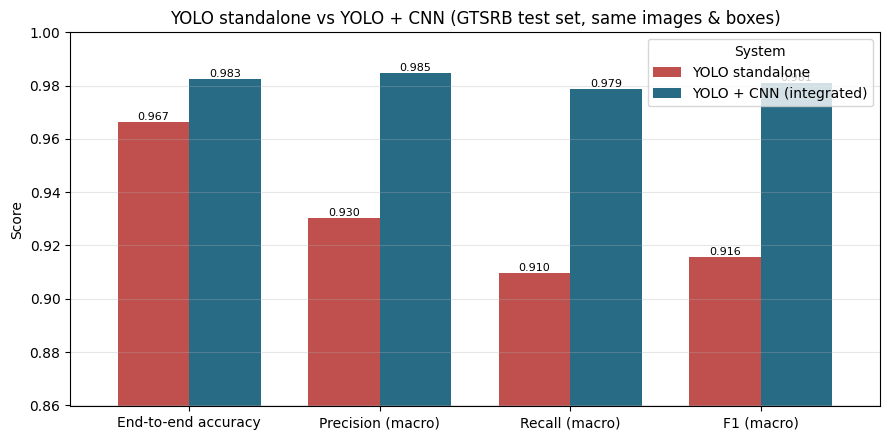

In [ ]:
# Figure: YOLO vs YOLO+CNN
cols = ["End-to-end accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
plot_df = s6_comparison.loc[["YOLO standalone", "YOLO + CNN (integrated)"], cols]
ax = plot_df.T.plot.bar(figsize=(9, 4.5), width=0.75, color=["#c0504d", "#276b85"])
ax.set_ylim(max(0, plot_df.min().min() - 0.05), 1.0)
ax.set_title("YOLO standalone vs YOLO + CNN (GTSRB test set, same images & boxes)")
ax.set_ylabel("Score"); ax.grid(axis="y", alpha=0.3); plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "comparison_metrics.png", dpi=300, bbox_inches="tight"); plt.show()

## 5. Crop-padding sensitivity (ablation – reported, not tuned)
The CNN was trained on whole GTSRB frames (sign plus a small border), while YOLO boxes are tight. This shows how much the amount of context around the box matters. The main pipeline keeps the pre-set `CROP_PAD = 0.10`; this table is for the discussion only (choosing the best row *on the test set* would be test-set tuning).

In [ ]:
det_idx = res.index[res.localized]

def accuracy_for_pad(pad, chunk=512):
    old, pipe.crop_pad = pipe.crop_pad, pad
    correct = 0
    for s in range(0, len(det_idx), chunk):
        ids = det_idx[s:s + chunk]
        crops = []
        for i in ids:
            img = cv2.imread(test.loc[i, "img_path"])
            crops.append(pipe.crop(img, (res.loc[i, "x1"], res.loc[i, "y1"], res.loc[i, "x2"], res.loc[i, "y2"])))
        pred, _ = pipe.classify(crops)
        correct += int((pred == res.loc[ids, "gt_cls"].to_numpy()).sum())
    pipe.crop_pad = old
    return correct

pad_rows = [{"Crop padding": pad, "Correct": c, "Acc. on detected": c / len(det_idx), "End-to-end acc.": c / len(res)}
            for pad in (0.0, 0.10, 0.20, 0.30) for c in [accuracy_for_pad(pad)]]
pad_df = pd.DataFrame(pad_rows).set_index("Crop padding")
display(pad_df.round(4)); pad_df.round(4).to_csv(OUT / "crop_padding_sensitivity.csv")

,Correct,Acc. on detected,End-to-end acc.
Crop padding,,,
0.0,12344,0.9803,0.9774
0.1,12409,0.9855,0.9825
0.2,12397,0.9845,0.9816
0.3,12389,0.9839,0.9809


## 6. Inference time
Per-image latency, batch size 1 (like a car camera), after a warm-up, with GPU synchronisation. "Crop + CNN" is the extra cost the integration adds on top of YOLO.

,Mean (ms),Median (ms),P95 (ms),FPS
System,,,,
YOLO standalone,16.52,15.23,24.37,60.53
YOLO + CNN (integrated),47.41,44.04,64.74,21.09


Mean stage time (ms):


,YOLO,Crop,CNN (preprocess+infer)
ms,14.82,0.28,32.31


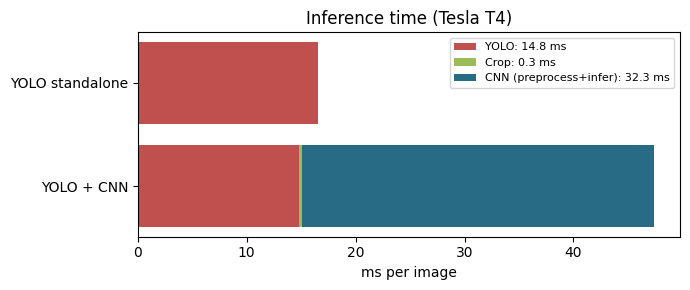

In [ ]:
N_TIME, WARMUP = 500, 30
sub = test.sample(N_TIME + WARMUP, random_state=SEED)
frames = [cv2.imread(p) for p in sub.img_path]          # decode up-front: disk I/O is not timed

yolo_only, stages = [], []
for k, img in enumerate(frames):
    sync(); a = time.perf_counter()
    pipe.detect([img], batch=1)
    sync(); y = (time.perf_counter() - a) * 1e3
    _, t = pipe.predict_image(img, timing=True)
    if k >= WARMUP:
        yolo_only.append(y); stages.append(t)

st = pd.DataFrame(stages)
def line(name, x):
    x = np.asarray(x)
    return {"System": name, "Mean (ms)": x.mean(), "Median (ms)": np.median(x),
            "P95 (ms)": np.percentile(x, 95), "FPS": 1000 / x.mean()}

timing = pd.DataFrame([line("YOLO standalone", yolo_only),
                       line("YOLO + CNN (integrated)", st["total_ms"])]).set_index("System")
display(timing.round(2)); timing.round(3).to_csv(OUT / "inference_time.csv")

breakdown = st[["yolo_ms", "crop_ms", "cnn_ms"]].mean().rename({"yolo_ms": "YOLO", "crop_ms": "Crop", "cnn_ms": "CNN (preprocess+infer)"})
print("Mean stage time (ms):"); display(breakdown.round(2).to_frame("ms").T)

fig, ax = plt.subplots(figsize=(7, 3))
left = 0
for name, color in zip(breakdown.index, ["#c0504d", "#9bbb59", "#276b85"]):
    ax.barh(["YOLO + CNN"], [breakdown[name]], left=left, color=color, label=f"{name}: {breakdown[name]:.1f} ms")
    left += breakdown[name]
ax.barh(["YOLO standalone"], [np.mean(yolo_only)], color="#c0504d")
ax.set_xlabel("ms per image"); ax.set_title(f"Inference time ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT / "inference_time.png", dpi=300, bbox_inches="tight"); plt.show()

## 7. Error analysis

,YOLO standalone,YOLO + CNN
Correct,12207,12409
Wrong class,385,183
Mislocalised (IoU<0.5),0,0
Missed (no detection),38,38
Extra boxes (false detections),119,119


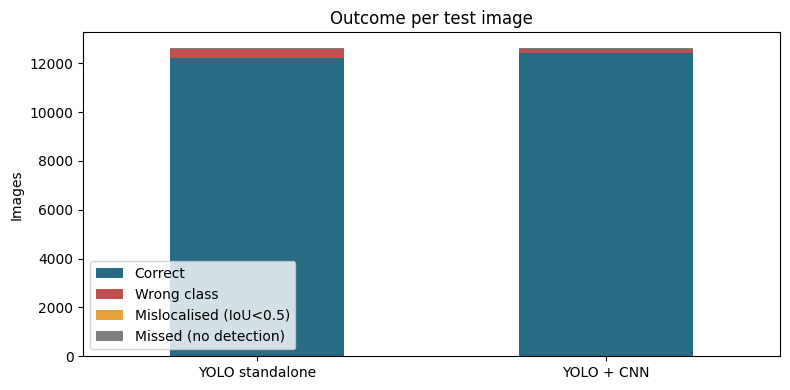

Top confusions - YOLO standalone


,True,Predicted,Count
0,39: Keep left,38: Keep right,59
1,20: Dangerous curve to the right,19: Dangerous curve to the left,42
2,37: Go straight or left,36: Go straight or right,41
3,19: Dangerous curve to the left,20: Dangerous curve to the right,30
4,3: Speed limit (60km/h),5: Speed limit (80km/h),17
5,36: Go straight or right,37: Go straight or left,17
6,27: Pedestrians,25: Road work,17
7,38: Keep right,39: Keep left,14


Top confusions - YOLO + CNN


,True,Predicted,Count
0,3: Speed limit (60km/h),5: Speed limit (80km/h),30
1,22: Bumpy road,25: Road work,26
2,8: Speed limit (120km/h),3: Speed limit (60km/h),20
3,12: Priority road,38: Keep right,16
4,35: Ahead only,40: Roundabout mandatory,6
5,4: Speed limit (70km/h),8: Speed limit (120km/h),6
6,6: End of speed limit (80km/h),42: End of no passing for vehicles over 3.5 tons,6
7,30: Beware of ice/snow,29: Bicycles crossing,5


Classes where the CNN helps / hurts most:


,name,yolo_ok,pipe_ok,diff
gt_cls,,,,
22,Bumpy road,0.883,0.750,-0.133
6,End of speed limit (80km/h),0.967,0.893,-0.073
30,Beware of ice/snow,0.993,0.947,-0.047
8,Speed limit (120km/h),0.969,0.933,-0.036
12,Priority road,0.994,0.967,-0.028
27,Pedestrians,0.483,0.867,0.383
20,Dangerous curve to the right,0.533,1.000,0.467
19,Dangerous curve to the left,0.500,1.000,0.500
39,Keep left,0.344,1.000,0.656


In [ ]:
def categorize(ok):
    return np.select([ok, res.n_det == 0, ~res.localized],
                     ["Correct", "Missed (no detection)", "Mislocalised (IoU<0.5)"], default="Wrong class")

err = pd.DataFrame({"YOLO standalone": categorize(res.yolo_ok).tolist(),
                    "YOLO + CNN": categorize(res.pipe_ok).tolist()})
err_table = pd.DataFrame({c: err[c].value_counts() for c in err}).fillna(0).astype(int)
err_table = err_table.reindex(["Correct", "Wrong class", "Mislocalised (IoU<0.5)", "Missed (no detection)"]).fillna(0).astype(int)
err_table.loc["Extra boxes (false detections)"] = int((res.n_det - 1).clip(lower=0).sum())   # same for both systems
display(err_table); err_table.to_csv(OUT / "error_analysis.csv")

err_table.iloc[:4].T.plot.bar(stacked=True, figsize=(8, 4), color=["#276b85", "#c0504d", "#e6a23c", "#7f7f7f"])
plt.title("Outcome per test image"); plt.ylabel("Images"); plt.xticks(rotation=0); plt.tight_layout()
plt.savefig(OUT / "error_breakdown.png", dpi=300, bbox_inches="tight"); plt.show()

def top_confusions(pred_col, ok_col, k=8):
    wrong = res[res.localized & ~res[ok_col]]
    pairs = wrong.groupby(["gt_cls", pred_col]).size().sort_values(ascending=False).head(k)
    return pd.DataFrame([{"True": f"{t}: {class_names[t]}", "Predicted": f"{p}: {class_names[p]}", "Count": int(n)}
                         for (t, p), n in pairs.items()])

print("Top confusions - YOLO standalone"); display(top_confusions("yolo_cls", "yolo_ok"))
print("Top confusions - YOLO + CNN");       display(top_confusions("cnn_cls", "pipe_ok"))

pc = res.groupby("gt_cls")[["yolo_ok", "pipe_ok"]].mean()
pc["diff"] = pc.pipe_ok - pc.yolo_ok
pc.insert(0, "name", [class_names[i] for i in pc.index])
pc.round(4).to_csv(OUT / "per_class_comparison.csv")
print("Classes where the CNN helps / hurts most:")
display(pd.concat([pc.sort_values("diff").head(5), pc.sort_values("diff").tail(5)]).round(3))

## 8. Prediction visualisations (test set)

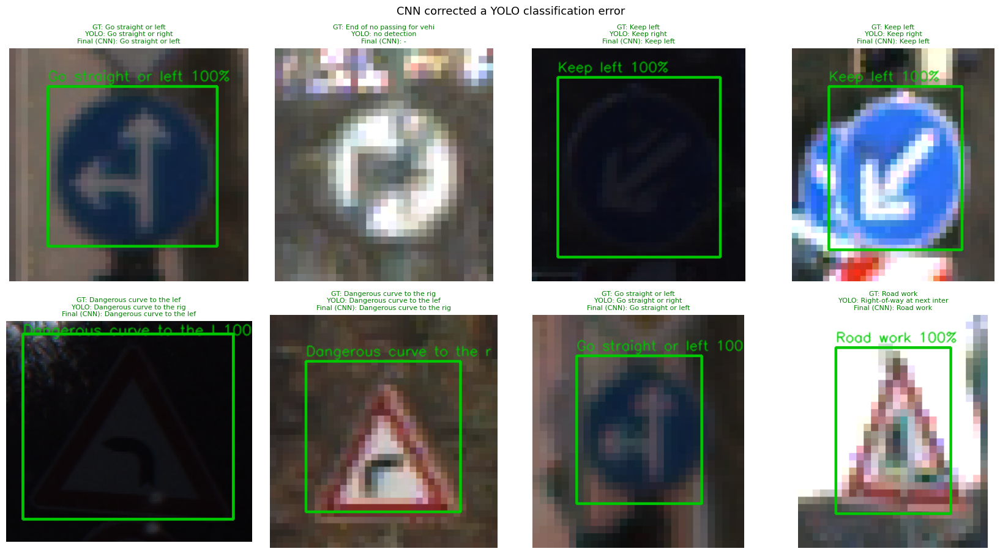

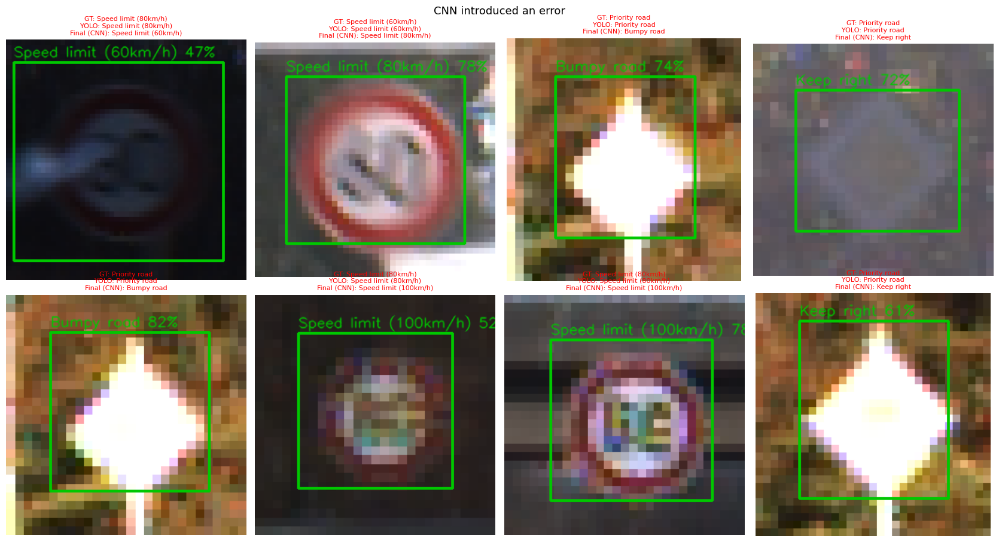

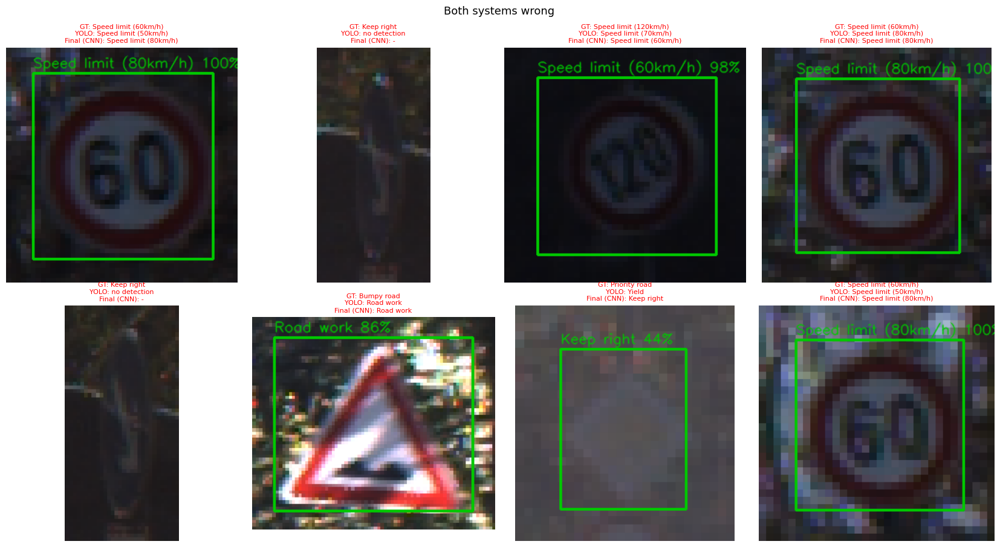

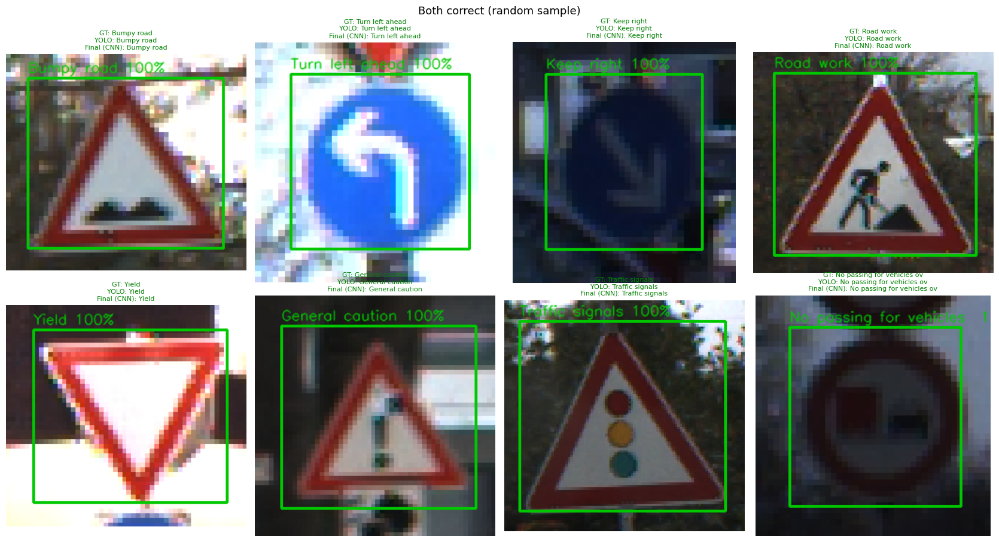

In [ ]:
def draw(img_bgr, dets, scale):
    out = cv2.resize(img_bgr, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)
    for d in dets:
        x1, y1, x2, y2 = [int(v * scale) for v in d["box"]]
        cv2.rectangle(out, (x1, y1), (x2, y2), (0, 200, 0), 2)
        cv2.putText(out, f'{d["final_name"][:24]} {d["cnn_conf"]:.0%}', (x1, max(14, y1 - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 200, 0), 1, cv2.LINE_AA)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

def show_examples(indices, title, fname, cols=4):
    indices = list(indices)[:8]
    if not indices:
        print("Nothing to show for:", title); return
    rows_ = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(4.2 * cols, 4.6 * rows_))
    for ax in np.atleast_1d(axes).flat: ax.axis("off")
    for ax, i in zip(np.atleast_1d(axes).flat, indices):
        img = cv2.imread(test.loc[i, "img_path"])
        dets = pipe.predict_image(img)
        ax.imshow(draw(img, dets, 256 / max(img.shape[:2])))
        d = dets[0] if dets else None
        ax.set_title(f"GT: {class_names[res.loc[i, 'gt_cls']][:26]}\n"
                     f"YOLO: {d['yolo_name'][:26] if d else 'no detection'}\n"
                     f"Final (CNN): {d['final_name'][:26] if d else '-'}",
                     fontsize=8, color="green" if res.loc[i, "pipe_ok"] else "red")
    plt.suptitle(title, fontsize=13); plt.tight_layout()
    plt.savefig(OUT / fname, dpi=300, bbox_inches="tight"); plt.show()

rng = np.random.default_rng(SEED)
pick = lambda mask: rng.permutation(res.index[mask].to_numpy())
show_examples(pick(res.pipe_ok & ~res.yolo_ok), "CNN corrected a YOLO classification error", "examples_cnn_fixes_yolo.png")
show_examples(pick(res.yolo_ok & ~res.pipe_ok), "CNN introduced an error", "examples_cnn_breaks.png")
show_examples(pick(~res.yolo_ok & ~res.pipe_ok), "Both systems wrong", "examples_both_wrong.png")
show_examples(pick(res.pipe_ok & res.yolo_ok), "Both correct (random sample)", "examples_correct.png")

## 9. Road-scene test (optional)
Student 5 found that the detector produced **no boxes** on external road photos (it was trained on GTSRB's pre-cropped sign images, where the sign fills the frame). This cell reports what the full pipeline does on those photos; an empty result is a genuine finding for the report, not a bug in the integration.

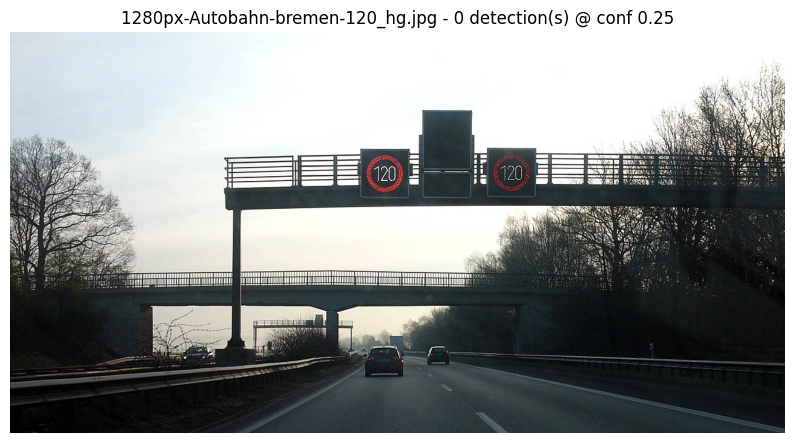

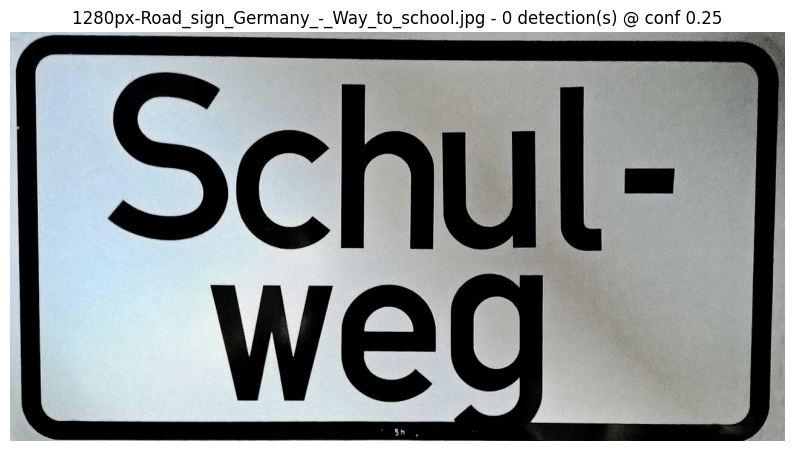

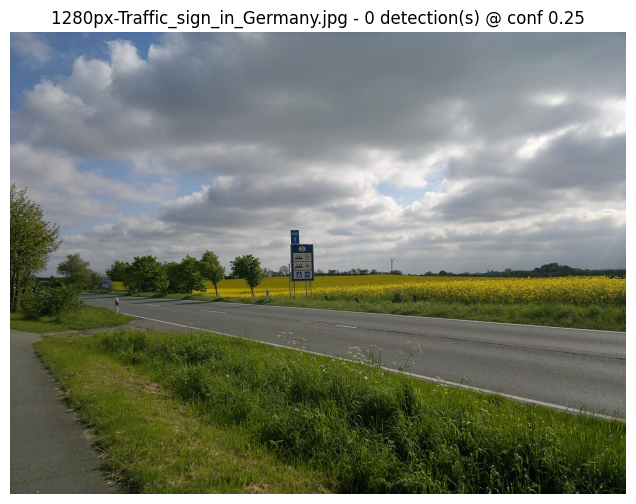

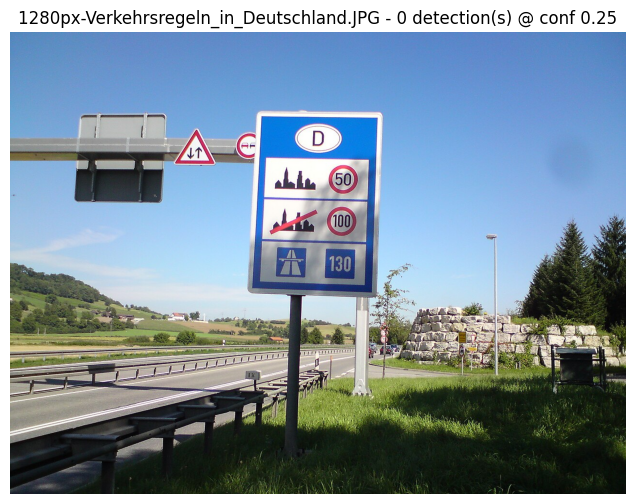

,image,detections,total_ms,labels
0,1280px-Autobahn-bremen-120_hg.jpg,0,31.9,-
1,1280px-Road_sign_Germany_-_Way_to_school.jpg,0,16.9,-
2,1280px-Traffic_sign_in_Germany.jpg,0,38.1,-
3,1280px-Verkehrsregeln_in_Deutschland.JPG,0,16.8,-


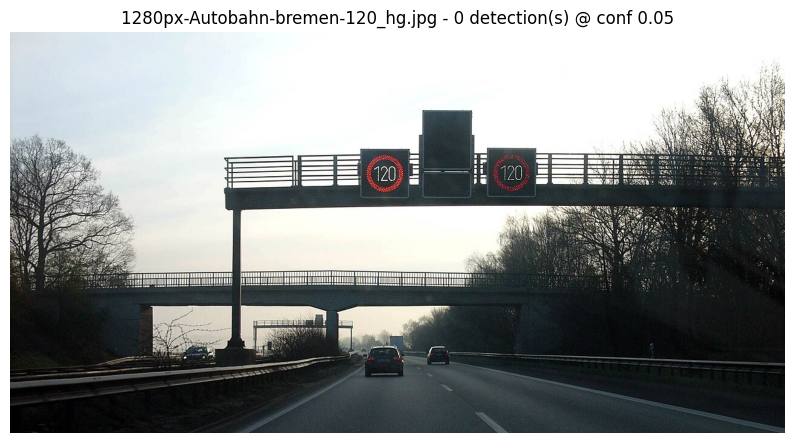

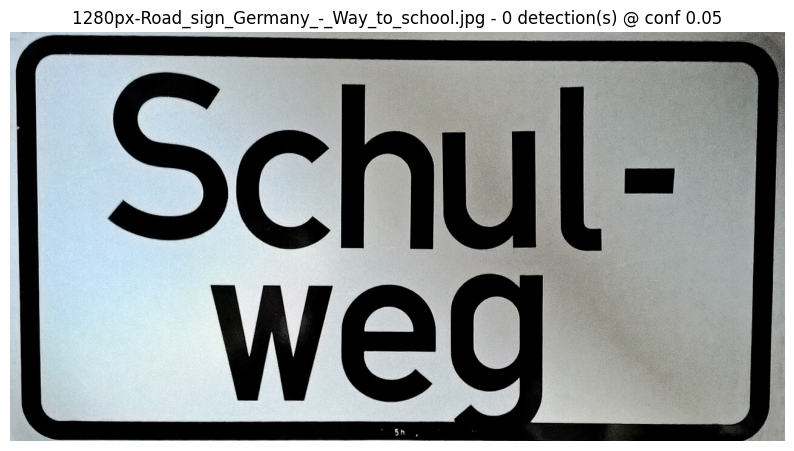

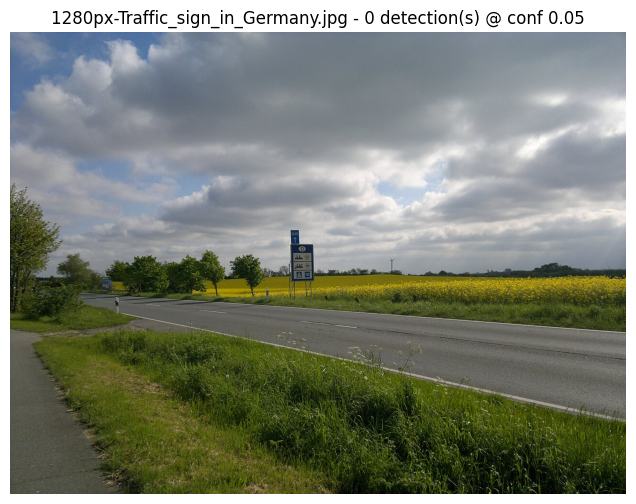

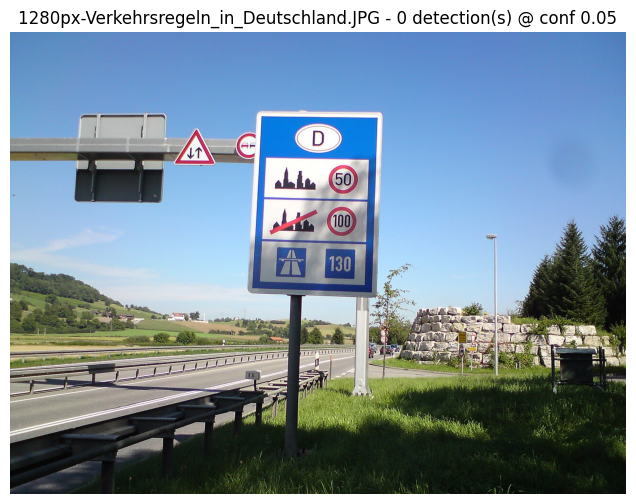

,image,detections,total_ms,labels
0,1280px-Autobahn-bremen-120_hg.jpg,0,20.0,-
1,1280px-Road_sign_Germany_-_Way_to_school.jpg,0,19.8,-
2,1280px-Traffic_sign_in_Germany.jpg,0,19.3,-
3,1280px-Verkehrsregeln_in_Deutschland.JPG,0,16.4,-


In [ ]:
def run_on_folder(folder, conf=DET_CONF, max_images=6):
    folder = Path(folder)
    paths = sorted(p for p in folder.glob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})[:max_images] if folder.exists() else []
    if not paths:
        print(f"No road images in {folder} - upload a few to run this cell."); return
    old, pipe.conf = pipe.conf, conf
    summary = []
    for p in paths:
        img = cv2.imread(str(p))
        dets, t = pipe.predict_image(img, timing=True)
        summary.append({"image": p.name, "detections": len(dets), "total_ms": round(t["total_ms"], 1),
                        "labels": ", ".join(f'{d["final_name"]} ({d["det_conf"]:.2f})' for d in dets) or "-"})
        plt.figure(figsize=(10, 6)); plt.imshow(draw(img, dets, 1.0)); plt.axis("off")
        plt.title(f"{p.name} - {len(dets)} detection(s) @ conf {conf}"); plt.show()
    pipe.conf = old
    return pd.DataFrame(summary)

for c in (DET_CONF, 0.05):
    road_df = run_on_folder(ROAD_DIR, conf=c)
    if road_df is not None:
        display(road_df); road_df.to_csv(OUT / f"road_scene_conf_{c}.csv", index=False)

## 10. Save the pipeline and final results

In [ ]:
import ultralytics
s6_config = {"pipeline": "Input image -> YOLO detection -> crop (+padding) -> CNN classification -> final label",
          "yolo_model": YOLO_PATH.name, "cnn_model": CNN_PATH.name,
          "yolo_imgsz": YOLO_IMGSZ, "detection_conf": DET_CONF, "crop_padding": CROP_PAD,
          "cnn_input_size": CNN_SIZE, "cnn_preprocessing": "RGB, tf.image.resize bilinear, /255",
          "box_match_iou": MATCH_IOU, "top_box_rule": "highest-confidence detection per image",
          "class_mapping": "GTSRB ClassId 0-42, identical for YOLO and CNN",
          "test_set": f"GTSRB Test.csv, {len(test)} images", "seed": SEED,
          "versions": {"ultralytics": ultralytics.__version__, "tensorflow": tf.__version__, "torch": torch.__version__}}
json.dump(s6_config, open(OUT / "integration_config.json", "w"), indent=2)

s6_final = {"comparison": s6_comparison.round(4).reset_index().to_dict("records"),
         "inference_time_ms": timing.round(3).reset_index().to_dict("records"),
         "paired_outcomes": {"both_correct": both, "only_yolo_correct": only_yolo,
                             "only_pipeline_correct": only_pipe, "both_wrong": neither}}
json.dump(s6_final, open(OUT / "final_results.json", "w"), indent=2)

shutil_src = Path("/content/traffic_sign_pipeline.py")
(OUT / shutil_src.name).write_text(shutil_src.read_text())

zip_path = Path("/content/Student6_Final_Delivery.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.rglob("*"):
        if f.is_file(): z.write(f, f.relative_to(OUT))
print("Saved", len(list(OUT.iterdir())), "files ->", zip_path)
for f in sorted(OUT.iterdir()): print(" -", f.name)

try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    pass

Saved 20 files -> /content/Student6_Final_Delivery.zip
 - class_mapping.json
 - comparison_metrics.png
 - crop_padding_sensitivity.csv
 - error_analysis.csv
 - error_breakdown.png
 - examples_both_wrong.png
 - examples_cnn_breaks.png
 - examples_cnn_fixes_yolo.png
 - examples_correct.png
 - final_comparison_table.csv
 - final_results.json
 - inference_time.csv
 - inference_time.png
 - integration_config.json
 - paired_outcomes.csv
 - per_class_comparison.csv
 - road_scene_conf_0.05.csv
 - road_scene_conf_0.25.csv
 - test_predictions.csv
 - traffic_sign_pipeline.py


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>